In [17]:
# %%
# Parent version: skyfield_101224_positions_and_contamination_final_ver4.2
# Runs with daily increments, samples every 0.1m of the satellites and checks masterfıts in the sky.
# This version simulates whole sky per second (satellite and time incremation swapped)
import os
import sys
import logging
import numpy as np
from astropy import units as u
from astropy.time import Time
from astropy.io import fits
from astropy.table import Table
from astropy.coordinates import SkyCoord, EarthLocation
import skyfield as sf
from skyfield.api import load, wgs84, EarthSatellite, N, W,S,E, Star, Angle
import datetime as dt
import time
from skyfield import almanac
from skyfield.framelib import galactic_frame
from skyfield.data import hipparcos
import lumos.calculator
import random
from src.satellites.starlink_sat import *
from src.utils.calculations import *
from src.utils.plots import *
from src.utils.utils import *
from src.tracking.satellite_tracker import SatelliteTracker
from src.tracking.target_tracker import TargetTracker
from src.tracking.exposure_tracker import ExposureTracker
import lumos.plot
import lumos.brdf.library
from astropy.wcs import WCS
import matplotlib.pyplot as plt
import matplotlib
from matplotlib.ticker import FuncFormatter
import matplotlib.dates as mdates
from datetime import datetime, timedelta
from matplotlib import colors as mcolors
from astropy.visualization import quantity_support, time_support
import pandas as pd
quantity_support()  

now = datetime.now()
cwd = os.getcwd()
print(cwd)
cwd = os.getcwd() + '/../..'
pathToTargets = os.path.join(cwd, "in_LSST_footprint_coordinates.fits")
pathToCalculatedTargets = os.path.join(cwd, "Skyfield/calculated_targets")
pathToTLE = os.path.join(cwd, "Skyfield/tle_data")
pathToFiles = os.path.join(cwd, "Skyfield/files/new/fixed")
pathToLogs = os.path.join(cwd, "Skyfield/logs")
pathToPlots = os.path.join(cwd, "Skyfield/plots/new/fixed")

zone = timezone('Chile/Continental')

/data/a.saricaoglu/repo/RubinsForge/Skyfield/scripts


#### Initialize the data arrays for the OpSim entegrated Skyfield simulations
Read each month into a dictionary item.

In [18]:

files = [f for f in os.listdir(pathToFiles) if f.endswith('.fits') and 'old' not in f ]
months = {}

may = [f for f in files if 'visit_2025-05' in f]
july = [f for f in files if 'visit_2025-07' in f]
june = [f for f in files if 'visit_2025-06' in f]
august = [f for f in files if 'visit_2025-08' in f]
september = [f for f in files if 'visit_2025-09' in f]  
october = [f for f in files if 'visit_2025-10' in f]
november = [f for f in files if 'visit_2025-11' in f]
december = [f for f in files if 'visit_2025-12' in f]
january = [f for f in files if 'visit_2026-01' in f]
february = [f for f in files if 'visit_2026-02' in f]
march = [f for f in files if 'visit_2026-03' in f]
april = [f for f in files if 'visit_2026-04' in f]
may2 = [f for f in files if 'visit_2026-05' in f]
june2 = [f for f in files if 'visit_2026-06' in f]
july2 = [f for f in files if 'visit_2026-07' in f]

months['may25'] = may
months['june25'] = june
months['july25'] = july
months['august25'] = august
months['september25'] = september
months['october25'] = october
months['november25'] = november
months['december25'] = december
months['january26'] = january
months['february26'] = february
months['march26'] = march
months['april26'] = april
months['may26'] = may2
months['june26'] = june2
months['july26'] = july2

files.sort()
print(months)
print([len(month) for month in months.values()])

for month in months:
    
    print(f'Processing month: {month}')
    print(sorted(months[month]))

{'may25': ['skyfield_data_visit_2025-05-03.fits', 'skyfield_data_visit_2025-05-05.fits', 'skyfield_data_visit_2025-05-04.fits', 'skyfield_data_visit_2025-05-01.fits', 'skyfield_data_visit_2025-05-02.fits', 'skyfield_data_visit_2025-05-06.fits', 'skyfield_data_visit_2025-05-10.fits', 'skyfield_data_visit_2025-05-07.fits', 'skyfield_data_visit_2025-05-08.fits', 'skyfield_data_visit_2025-05-17.fits', 'skyfield_data_visit_2025-05-13.fits', 'skyfield_data_visit_2025-05-09.fits', 'skyfield_data_visit_2025-05-16.fits', 'skyfield_data_visit_2025-05-11.fits', 'skyfield_data_visit_2025-05-12.fits', 'skyfield_data_visit_2025-05-18.fits', 'skyfield_data_visit_2025-05-20.fits', 'skyfield_data_visit_2025-05-21.fits', 'skyfield_data_visit_2025-05-22.fits', 'skyfield_data_visit_2025-05-28.fits'], 'june25': ['skyfield_data_visit_2025-06-04.fits', 'skyfield_data_visit_2025-06-07.fits', 'skyfield_data_visit_2025-06-16.fits', 'skyfield_data_visit_2025-06-17.fits', 'skyfield_data_visit_2025-06-02.fits', 's

In [19]:
from collections import defaultdict

monthly_exposures_data = defaultdict(dict)

for month in months:
    
    days_data = defaultdict(dict)
    for day in months[month]:
        print(f"Processing file: {day}")
        n = day.split('_')[3].strip('.fits')  # Extract the month part from the filename
        print(f"Date: {n}")

        # CORRECTED: Store by exposure ID, then extension type
        exposures_data = defaultdict(dict)

        with fits.open(os.path.join(pathToFiles, day)) as hdul:
            hdul.info()
            
            # Iterate through all HDUs and organize by exposure ID
            for i, hdu in enumerate(hdul):
                if hdu.header.get('EXTNAME') is None:
                    continue  # Skip primary HDU
                
                ext_name = hdu.header.get('EXTNAME')
                exp_id = hdu.header.get('EXPID', f'unknown_{i}') #EXP_ID ++ VISIT_ID if visit_info provided

                
                print(f"  HDU {i}: {ext_name}, EXPID: {exp_id}")
                
                # CORRECTED: Store by exposure ID, then extension type
                if exp_id not in exposures_data:
                    exposures_data[exp_id] = {}
                
                exposures_data[exp_id][ext_name] = {
                    'data': hdu.data,
                    'header': hdu.header,
                    'hdu_index': i
                     # Store the start time for easy access
                }
            
            print(f"Found {len(exposures_data)} exposures in file {day}")
            
            # Optional: Print summary of each exposure
            for exp_id, exp_data in exposures_data.items():
                print(f"\nExposure {exp_id}:")
                print(f"  Extensions: {list(exp_data.keys())}")
                
                # Get exposure start time for grouping by date later
                if 'SATELLITE_DATA' in exp_data:
                    exp_start = exp_data['SATELLITE_DATA']['header']['EXPSTART']
                    print(f"  Start time: {exp_start}")
                    
                    sat_data = exp_data['SATELLITE_DATA']['data']
                    sat_header = exp_data['SATELLITE_DATA']['header']
                    
                    print(f"  Satellite observations: {len(sat_data) if sat_data is not None else 0}")
                    print(f"  Events: {sat_header.get('EVENTS', 'Unknown')}")
                    print(f"  Trail candidates: {sat_header.get('TRAILCAN', 'Unknown')}")
                    print(f"  Contaminations: {sat_header.get('CONTAM', 'Unknown')}")
    
        days_data[n] = exposures_data
    monthly_exposures_data[month] = days_data

Processing file: skyfield_data_visit_2025-05-03.fits
Date: 2025-05-03
Filename: /data/a.saricaoglu/repo/RubinsForge/Skyfield/scripts/../../Skyfield/files/new/fixed/skyfield_data_visit_2025-05-03.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      13   ()      
  1  VISIT_INFO    1 BinTableHDU     42   1R x 14C   [K, D, D, 25A, D, K, D, D, K, 25A, 25A, D, D, D]   
  2  SATELLITE_DATA    1 BinTableHDU     45   30R x 8C   [2D, 13A, D, D, D, D, D, D]   
  3  VISIT_INFO    1 BinTableHDU     42   1R x 14C   [K, D, D, 25A, D, K, D, D, K, 25A, 25A, D, D, D]   
  4  SATELLITE_DATA    1 BinTableHDU     45   30R x 8C   [2D, 13A, D, D, D, D, D, D]   
  5  CONTAMINATED_TARGETS    1 BinTableHDU     28   1R x 4C   [19A, 2D, D, D]   
  6  SEPARATIONS    1 BinTableHDU     16   1R x 1C   [D]   
  7  VISIT_INFO    1 BinTableHDU     42   1R x 14C   [K, D, D, 25A, D, K, D, D, K, 25A, 25A, D, D, D]   
  8  SATELLITE_DATA    1 BinTableHDU     45   30R x 8C 

In [20]:
print(f"Total months processed: {len(monthly_exposures_data)}")
print(monthly_exposures_data.keys())
exposure_records = []
for month in monthly_exposures_data:
    for day in monthly_exposures_data[month]:
        for exp_id in monthly_exposures_data[month][day]:
            exp_data = monthly_exposures_data[month][day][exp_id]
            
            if 'SATELLITE_DATA' in exp_data:
                sat_header = exp_data['SATELLITE_DATA']['header']
                visit_header = exp_data['VISIT_INFO']['header'] if 'VISIT_INFO' in exp_data else {}
                sat_data = exp_data['SATELLITE_DATA']['data']
                visit_data = exp_data['VISIT_INFO']['data'] if 'VISIT_INFO' in exp_data else None
                contam_header = exp_data['CONTAMINATED_TARGETS']['header'] if 'CONTAMINATED_TARGETS' in exp_data else {}
                contam_data = exp_data['CONTAMINATED_TARGETS']['data'] if 'CONTAMINATED_TARGETS' in exp_data else None
                exp_start = exp_data['SATELLITE_DATA']['header'].get('EXPSTART', 'unknown_date')
                
                if exp_start and exp_start != 'unknown_date':
                    try:
                        exp_datetime = datetime.fromisoformat(exp_start).astimezone(zone)
                        
                        record = {
                            'month': month,
                            'day': day,
                            'exp_id': exp_id,
                            'datetime': exp_datetime,
                            'date': exp_datetime.date(),
                            'filter': visit_header.get('FILTER', 'Unknown'),
                            'field_ra': visit_data['FIELD_RA'][0] ,
                            'field_dec': visit_data['FIELD_DEC'][0] ,
                            'seeing': visit_data['SEEING'][0],
                            'sky_brightness': visit_data['SKY_BRIGHTNESS'][0] ,
                            'events': sat_header.get('EVENTS', 0) or 0,
                            'trail_candidates': sat_header.get('TRAILCAN', 0) or 0,
                            'contaminations': sat_header.get('CONTAM', 0) or 0,
                            'contaminated_targets': contam_header.get('NCONTAM', 0) or 0,
                            'contaminated_unique_targets':contam_header.get('NTARG', 0) or 0,
                            'peak_magnitude': sat_header.get('PEAKM'),
                            'avg_magnitude': sat_header.get('AVGM'),
                            'peak_intensity': sat_header.get('PEAKI'),
                            'avg_intensity': sat_header.get('AVGI'),
                            'num_satellites': sat_header.get('NSAT', 0) or 0
                        }
                        exposure_records.append(record)
                    except Exception as e:
                        print(f"Error parsing exposure {exp_id} for day {day}: {e}")
                        continue

# Create DataFrame
df = pd.DataFrame(exposure_records)
print(f"DataFrame created with {len(df)} records")
print(df.head())

Total months processed: 15
dict_keys(['may25', 'june25', 'july25', 'august25', 'september25', 'october25', 'november25', 'december25', 'january26', 'february26', 'march26', 'april26', 'may26', 'june26', 'july26'])
DataFrame created with 12103 records
   month         day  exp_id                  datetime        date filter  \
0  may25  2025-05-03    2188 2025-05-03 04:29:59-04:00  2025-05-03      g   
1  may25  2025-05-03    2189 2025-05-03 04:30:37-04:00  2025-05-03      g   
2  may25  2025-05-03    2196 2025-05-03 04:35:07-04:00  2025-05-03      g   
3  may25  2025-05-03    2197 2025-05-03 04:35:45-04:00  2025-05-03      g   
4  may25  2025-05-03    2232 2025-05-03 05:01:30-04:00  2025-05-03      u   

     field_ra  field_dec    seeing  sky_brightness  events  trail_candidates  \
0  224.239784 -38.636427  0.719650       21.972210     869                30   
1  221.433095 -40.441152  0.735906       21.976185     851                30   
2  217.102269 -36.023147  0.807774       21.91

In [21]:

# Create DataFrame
df = pd.DataFrame(exposure_records)
print("DataFrame created:")
print(df.head())
# Add this debugging cell to understand your data better:

print("Debugging exposure dates:")
print(f"DataFrame shape: {df.shape}")
print(f"Date range in DataFrame: {df['date'].min()} to {df['date'].max()}")
print(f"Unique dates: {sorted(df['date'].unique())}")
print(f"Number of unique dates: {df['date'].nunique()}")

# Check dates per month
print("\nDates per month:")
for month in df['month'].unique():
    month_data = df[df['month'] == month]
    print(f"Month {month}:")
    print(f"  Date range: {month_data['date'].min()} to {month_data['date'].max()}")
    print(f"  Unique dates: {sorted(month_data['date'].unique())}")
    print(f"  Number of exposures: {len(month_data)}")
    print(f"  Number of days: {month_data['date'].nunique()}")

# Check the exposure start times more closely
print("\nSample exposure start times:")
for i, row in df.head(10).iterrows():
    print(f"  {row['exp_id']}: {row['datetime']} (date: {row['date']})")
print(f"Total exposures: {len(df)}")
print("Checking exposure time distribution:")
for month in monthly_exposures_data:
    print(f"\nMonth {month}:")
    
    exposure_times = []
    for exp_id, exp in monthly_exposures_data[month].items():
        if 'SATELLITE_DATA' in exp:
            exp_start = exp['SATELLITE_DATA']['exp_start']
            if exp_start != 'unknown_date':
                try:
                    exp_datetime = datetime.fromisoformat(exp_start)
                    exposure_times.append(exp_datetime)
                except:
                    continue
    
    if exposure_times:
        exposure_times.sort()
        print(f"  First exposure: {exposure_times[0]}")
        print(f"  Last exposure: {exposure_times[-1]}")
        print(f"  Total exposures: {len(exposure_times)}")
        print(f"  Time span: {exposure_times[-1] - exposure_times[0]}")
        
        # Check unique dates
        unique_dates = set(dt.date() for dt in exposure_times)
        print(f"  Unique dates: {len(unique_dates)}")
        print(f"  Dates: {sorted(unique_dates)}")
    else:
        print("  No valid exposure times found")
# CORRECTED: Group by file (month) AND date to get daily statistics per month
daily_stats = df.groupby(['month', 'date']).agg({
    'events': 'sum',
    'trail_candidates': 'sum',
    'contaminations': 'sum',
    'peak_magnitude': 'min',  # Brightest (lowest magnitude)
    'avg_magnitude': 'mean',
    'peak_intensity': 'max',
    'avg_intensity': 'mean',
    'num_satellites': 'sum',
    'exp_id': 'count'  # Number of exposures per day
}).reset_index()

daily_stats.rename(columns={'exp_id': 'num_exposures'}, inplace=True)
print("\nDaily statistics:")
print(daily_stats.head())


DataFrame created:
   month         day  exp_id                  datetime        date filter  \
0  may25  2025-05-03    2188 2025-05-03 04:29:59-04:00  2025-05-03      g   
1  may25  2025-05-03    2189 2025-05-03 04:30:37-04:00  2025-05-03      g   
2  may25  2025-05-03    2196 2025-05-03 04:35:07-04:00  2025-05-03      g   
3  may25  2025-05-03    2197 2025-05-03 04:35:45-04:00  2025-05-03      g   
4  may25  2025-05-03    2232 2025-05-03 05:01:30-04:00  2025-05-03      u   

     field_ra  field_dec    seeing  sky_brightness  events  trail_candidates  \
0  224.239784 -38.636427  0.719650       21.972210     869                30   
1  221.433095 -40.441152  0.735906       21.976185     851                30   
2  217.102269 -36.023147  0.807774       21.916996     645                30   
3  214.231722 -37.647744  0.803452       21.902422     774                60   
4  219.249350 -45.272340  0.768834       22.525510    1264                39   

   contaminations  contaminated_targe

In [22]:
import matplotlib.pyplot as plt
import numpy as np
from astropy.coordinates import SkyCoord, EarthLocation, AltAz
from astropy import units as u
from astropy.time import Time
import matplotlib.patches as patches
from skyfield.api import Star, Angle, wgs84

eph = load('de421.bsp')
earth = eph['earth']
sun = eph['sun']
rubin_obs = wgs84.latlon(-30.244633,  -70.749417)
rubinobs_astr = earth +  wgs84.latlon(30.244633*S,  70.749417*W, elevation_m = 2647)
ts = load.timescale()



## LSST FOV Target Selection

Pick contaminated targets that is inside LSST FOV diameter of ~3.5 degrees.

In [31]:
print(len(iereg_target_nos))

13019


In [23]:
# targets, names = get_targets_as_stars(pathToTargets, region='In_Euclid_Lowdust_Region')
# print(f"Total targets loaded: {len(targets)}")
# print(f"Sample target names: {names[:5]}")
from astropy.io import fits
from astropy.table import Table

fits_path = pathToTargets

with fits.open(fits_path) as hdul:
    hdul.info()  # list all HDUs/extensions

    in_euclid_region = hdul[2].header
    print("\nIN_EUCLID_LOW_DUST_REGION header:")
    for key in in_euclid_region:
        print(f"  {key}: {in_euclid_region[key]}")
    iereg_data = hdul[2].data
    iereg_names = iereg_data.names
    print(f"Columns in IN_EUCLID_LOW_DUST_REGION: {iereg_names}")
    iereg_target_nos = iereg_data['Target_no']
    iereg_sled_names = iereg_data['SLEDName']
    iereg_RA = iereg_data['RA']
    iereg_Dec = iereg_data['Dec']
    print(f"First 3 targets in IN_EUCLID_LOW_DUST_REGION:")
    for i in range(3):
        print(f"  Target_no: {iereg_target_nos[i]}, SLEDName: {iereg_sled_names[i]}, RA: {iereg_RA[i]}, Dec: {iereg_Dec[i]}")
    # # Read a specific extension (example)
    # print("\nCONTAMINATED_TARGETS rows:", len(contam))
    # print("Columns:", contam.names)
    # print("First 3 target names:", contam["Target_Name"][:3])

    # # Optional: convert extension to Astropy Table / pandas
    # contam_table = Table(contam)
    # contam_df = contam_table.to_pandas()
    # display(contam_df.head())

Filename: /data/a.saricaoglu/repo/RubinsForge/Skyfield/scripts/../../in_LSST_footprint_coordinates.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       4   ()      
  1  In_LSST_Footprint    1 BinTableHDU     21   13746R x 4C   [12A, 28A, D, D]   
  2  In_Euclid_Lowdust_Region    1 BinTableHDU     21   13025R x 4C   [12A, 28A, D, D]   

IN_EUCLID_LOW_DUST_REGION header:
  XTENSION: BINTABLE
  BITPIX: 8
  NAXIS: 2
  NAXIS1: 56
  NAXIS2: 13025
  PCOUNT: 0
  GCOUNT: 1
  TFIELDS: 4
  TTYPE1: Target_no
  TFORM1: 12A
  TTYPE2: SLEDName
  TFORM2: 28A
  TTYPE3: RA
  TFORM3: D
  TUNIT3: deg
  TTYPE4: DEC
  TFORM4: D
  TUNIT4: deg
  EXTNAME: In_Euclid_Lowdust_Region
  NOBJ: 13025
  COMMENT: Lenses inside Euclid overlap and lowdust region
Columns in IN_EUCLID_LOW_DUST_REGION: ['Target_no', 'SLEDName', 'RA', 'DEC']
First 3 targets in IN_EUCLID_LOW_DUST_REGION:
  Target_no: target_0000, SLEDName: J095921+020638, RA: 149.8407, Dec: 2.11067
  Target

In [24]:
targets_, names = get_targets_as_stars(pathToTargets, region='In_LSST_footprint')
print(f"Total targets loaded: {len(targets_)}")
print(f"Sample target names: {names[:5]}")


Filename: /data/a.saricaoglu/repo/RubinsForge/Skyfield/scripts/../../in_LSST_footprint_coordinates.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       4   ()      
  1  In_LSST_Footprint    1 BinTableHDU     21   13746R x 4C   [12A, 28A, D, D]   
  2  In_Euclid_Lowdust_Region    1 BinTableHDU     21   13025R x 4C   [12A, 28A, D, D]   
Total targets loaded: 13746
Sample target names: ['target_0000', 'target_0001', 'target_0002', 'target_0003', 'target_0004']


In [19]:
print(names_array)

['target_0000' 'target_0001' 'target_0002' ... 'target_13737'
 'target_13738' 'target_13739']


In [25]:

for month in monthly_exposures_data:
    month_visits = 0
    month_events = 0
    month_contaminated_targets = 0
    monthly_contam = 0
    for day in monthly_exposures_data[month]:

        for exp_id in monthly_exposures_data[month][day]:
            exp_data = monthly_exposures_data[month][day][exp_id]
            month_visits += 1
            if 'SATELLITE_DATA' in exp_data:
                sat_header = exp_data['SATELLITE_DATA']['header']
                visit_header = exp_data['VISIT_INFO']['header'] if 'VISIT_INFO' in exp_data else {}
                sat_data = exp_data['SATELLITE_DATA']['data']
                visit_data = exp_data['VISIT_INFO']['data'] if 'VISIT_INFO' in exp_data else None
                contam_header = exp_data['CONTAMINATED_TARGETS']['header'] if 'CONTAMINATED_TARGETS' in exp_data else {}
                contam_data = exp_data['CONTAMINATED_TARGETS']['data'] if 'CONTAMINATED_TARGETS' in exp_data else None
                exp_start = exp_data['SATELLITE_DATA']['header'].get('EXPSTART', 'unknown_date')
                if contam_data is not None:
                    for i, name in enumerate(contam_data['Target_Name']):
                        target_name_str = name.split(' ')[-1]
                        # print(f"Contaminated target: {target_name_str}")
             
                            
                        name_idx = np.where(iereg_target_nos == target_name_str)[0]
                        if name_idx.size > 0:
                            month_contaminated_targets += 1
                            print(f"Target {target_name_str} is in the LSST footprint.")
        print(f" Contaminated targets in LSST footprint: {month_contaminated_targets}")

Target target_13552 is in the LSST footprint.
Target target_9869 is in the LSST footprint.
Target target_10041 is in the LSST footprint.
Target target_10207 is in the LSST footprint.
Target target_8899 is in the LSST footprint.
Target target_8454 is in the LSST footprint.
Target target_8513 is in the LSST footprint.
Target target_8555 is in the LSST footprint.
Target target_8572 is in the LSST footprint.
Target target_8576 is in the LSST footprint.
Target target_8387 is in the LSST footprint.
Target target_0002 is in the LSST footprint.
Target target_8573 is in the LSST footprint.
Target target_8605 is in the LSST footprint.
Target target_8606 is in the LSST footprint.
Target target_8638 is in the LSST footprint.
Target target_8680 is in the LSST footprint.
Target target_10820 is in the LSST footprint.
Target target_10739 is in the LSST footprint.
Target target_9824 is in the LSST footprint.
Target target_10454 is in the LSST footprint.
Target target_9877 is in the LSST footprint.
Targ

In [26]:
print(f"Total months processed: {len(monthly_exposures_data)}")
print(monthly_exposures_data.keys())
fov_radius_deg = 1.75  # LSST FOV radius in degrees
exposure_records = []
contamination_records = []
skipped_targets = []
names_array = np.asarray(iereg_target_nos).astype(str).ravel()
inside_fov = 0

for month in monthly_exposures_data:
    month_visits = 0
    month_events = 0
    month_contaminated_targets = 0
    monthly_contam = 0
    for day in monthly_exposures_data[month]:

        for exp_id in monthly_exposures_data[month][day]:
            exp_data = monthly_exposures_data[month][day][exp_id]
            month_visits += 1
            if 'SATELLITE_DATA' in exp_data:
                sat_header = exp_data['SATELLITE_DATA']['header']
                visit_header = exp_data['VISIT_INFO']['header'] if 'VISIT_INFO' in exp_data else {}
                sat_data = exp_data['SATELLITE_DATA']['data']
                visit_data = exp_data['VISIT_INFO']['data'] if 'VISIT_INFO' in exp_data else None
                contam_header = exp_data['CONTAMINATED_TARGETS']['header'] if 'CONTAMINATED_TARGETS' in exp_data else {}
                contam_data = exp_data['CONTAMINATED_TARGETS']['data'] if 'CONTAMINATED_TARGETS' in exp_data else None
                exp_start = exp_data['SATELLITE_DATA']['header'].get('EXPSTART', 'unknown_date')
                
            
                # Get visit information
                visit_id = visit_data['VISIT_ID'][0] if 'VISIT_ID' in visit_data.dtype.names else exp_id
                field_ra = visit_data['FIELD_RA'][0] if 'FIELD_RA' in visit_data.dtype.names else np.nan
                field_dec = visit_data['FIELD_DEC'][0] if 'FIELD_DEC' in visit_data.dtype.names else np.nan
                filter_name = visit_data['FILTER'][0] if 'FILTER' in visit_data.dtype.names else 'Unknown'
                if isinstance(filter_name, bytes):
                    filter_name = filter_name.decode()
                
                seeing = visit_data['SEEING'][0] if 'SEEING' in visit_data.dtype.names else np.nan
                sky_brightness = visit_data['SKY_BRIGHTNESS'][0] if 'SKY_BRIGHTNESS' in visit_data.dtype.names else np.nan
                
                # Get satellite events
                events = sat_header.get('EVENTS', 0) or 0
                month_events += events
                
                # Get exposure start time
                exp_start = sat_header.get('EXPSTART', 'unknown_date')
                if exp_start == 'unknown_date':
                    continue
                
                exp_datetime = datetime.fromisoformat(exp_start)
                obs_time = Time(exp_datetime)
                skyfield_time = ts.from_datetime(exp_datetime)

                rubin_location = EarthLocation.of_site('rubin')
                field_coord = SkyCoord(ra=visit_data['FIELD_RA'][0]*u.deg,
                                                dec=visit_data['FIELD_DEC'][0]*u.deg, frame='icrs')
                if contam_data is not None and len(contam_data) > 0:
                    monthly_contam += 1
                    print(f"  Contamination data for exposure {exp_id}:")
                        # Get unique contaminated targets for this exposure
                    contam_dict = {}
                    unique_targets = np.unique(contam_data['Target_Name'])
                    month_contaminated_targets += len(unique_targets)
                    for i, name in enumerate(contam_data['Target_Name']):
                        target_name_str = name.split(' ')[-1]
                        contamination_num = 1
                        print(f"    Target: {target_name_str}, Index in contamination data: {i}")
                        if target_name_str in contam_dict:
                            skipped_targets.append({
                                'month': month,
                                'day': day,
                                'exposure_id': exp_id,
                                'target_name': str(name),
                                'target_key': target_name_str,
                                'reason': 'key_collision_overwrite'
                            })
                            contamination_num += 1
                        contam_dict[target_name_str] = {
                        'month': month,
                        'day': day,
                        'exposure_id': exp_id,
                        'visit_id': visit_id,
                        'exposure_datetime': exp_datetime,
                        'exposure_date': exp_datetime.date(),
                        'filter_band': filter_name,
                        'seeing_arcsec': seeing,
                        'sky_brightness_mag_per_arcsec2': sky_brightness,
                        'field_ra_deg': field_ra,
                        'field_dec_deg': field_dec,
                        'total_exposure_events': events,
                        'total_contaminated_targets': len(unique_targets),
                        'num_contamination_events': len(contam_data),
                        'name': target_name_str, 'time': contam_data['Time'][i], 'alt': contam_data['Target_Alt'][i] if 'Target_Alt' in contam_data.dtype.names else np.nan, 'az': contam_data['Target_Az'][i] if 'Target_Az' in contam_data.dtype.names else np.nan, 'contamination_num': contamination_num}
                        # print(f"Contaminated target: {target_name_str}, Time: {contam_dict[target_name_str]['time']}, Alt: {contam_dict[target_name_str]['alt']} deg, Az: {contam_dict[target_name_str]['az']} deg")

                    
                    for target_name in list(contam_dict.keys()):
                        target_info = contam_dict[target_name]
                        print(f"    Target: {target_name}")
                        
                        # Get ra dec for target from targets data
                        
                        name_idx = np.where(iereg_target_nos == target_name)[0]
                        print(f"      Index in iereg_target_nos: {name_idx}")
                        # target_star_obj = targets[name_idx[0]] if len(name_idx) > 0 else None
                        if name_idx.size == 0:
                            print(f"    Skipping target {target_name}: not found in names/targets arrays")
                            skipped_targets.append({
                                'month': month,
                                'day': day,
                                'exposure_id': exp_id,
                                'target_name': target_name,
                                'reason': 'missing_target_match'
                            })
                            continue
                        target_star_sled_name = iereg_sled_names[name_idx[0]]
                        target_star_ra = iereg_RA[name_idx[0]]
                        target_star_dec = iereg_Dec[name_idx[0]]
                        coord = SkyCoord(ra=target_star_ra*u.deg,
                                            dec=target_star_dec*u.deg, frame='icrs')

                        # Get target information (use first occurrence for target info)

                        # obs_time = Time(datetime.fromisoformat(sat_header['EXPSTART']))
                        # rubin_location = EarthLocation.of_site('rubin')
                        # altaz_frame_start = AltAz(obstime=obs_time, location=rubin_location)
                        # altaz_frame_end = AltAz(obstime=obs_time + 30*u.second, location=rubin_location)  # 30s later for satellite path
                        # # Transform field center to Alt/Az
                        # field_coord = SkyCoord(ra=visit_data['FIELD_RA'][0]*u.deg,
                        # dec=visit_data['FIELD_DEC'][0]*u.deg, frame='icrs')
                        # field_altaz_start = field_coord.transform_to(altaz_frame_start)
                        # field_altaz_end = field_coord.transform_to(altaz_frame_end)

                        target_alt = target_info['alt'] if 'alt' in target_info else np.nan
                        target_az = target_info['az'] if 'az' in target_info else np.nan
                        contamination_time_raw = np.asarray(target_info['time']).ravel()
                        if contamination_time_raw.size == 0:
                            skipped_targets.append({
                                'month': month,
                                'day': day,
                                'exposure_id': exp_id,
                                'target_name': target_name,
                                'target_sled_name': target_star_sled_name,
                                'reason': 'empty_contamination_time'
                            })
                            continue
                        if contamination_time_raw.size >= 2:
                            contamination_jd = float(contamination_time_raw[0] + contamination_time_raw[1])
                            contamination_time = Time(contamination_time_raw[0], contamination_time_raw[1], format='jd', scale='tt')
                        else:
                            contamination_jd = float(contamination_time_raw[0])
                            contamination_time = Time(contamination_jd, format='jd', scale='tt')


                        
                        altaz_frame = AltAz(obstime=contamination_time, location=rubin_location)
                        field_altaz = field_coord.transform_to(altaz_frame)

                        # Try to get from satellite data
                        if sat_data is not None and len(sat_data) > 0 and 'AB_Magnitude' in sat_data.dtype.names:
                            sat_time_raw = np.asarray(sat_data['Time'])
                            if sat_time_raw.ndim > 1 and sat_time_raw.shape[1] >= 2:
                                sat_time_vals = sat_time_raw[:, 0] + sat_time_raw[:, 1]
                            else:
                                sat_time_vals = np.asarray(sat_data['Time'], dtype=float).ravel()
                            sat_time_matches = np.where(np.isclose(sat_time_vals, contamination_jd, atol=1e-9))[0]
                            if len(sat_time_matches) > 0:
                                sat_magnitude = sat_data['AB_Magnitude'][sat_time_matches[0]]
                                sat_intensity = sat_data['Intensity'][sat_time_matches[0]]
                            else:
                                sat_magnitude = np.nan
                                sat_intensity = np.nan
                        else:
                            sat_magnitude = np.nan
                            sat_intensity = np.nan
                        
                        # Calculate apparent separation from field center using Rubin Observatory
                        
                        separation_from_center = np.nan

                        
                        
                        target_altaz= coord.transform_to(altaz_frame)
                        # Check if target altaz from contamination data and altaz calculated from target star data are close (sanity check)
                        print(f"      Target altaz from contamination data: Alt {target_alt} deg, Az {target_az} deg")
                        print(f"      Target altaz from star data: Alt {target_altaz.alt.deg}, Az {target_altaz.az.deg}")
                        # Only plot targets near the field center (use true angular separation)
                        # Angular separation using astropy (great-circle)
                        separations_deg= field_altaz.separation(target_altaz).deg

                        contam_dict[target_name]['separation_from_center_deg'] = separations_deg
                        contam_dict[target_name]['inside_fov'] = separations_deg <= fov_radius_deg
                        contam_dict[target_name]['target_altaz'] = target_altaz
                        contam_dict[target_name]['sat_magnitude'] = sat_magnitude
                        contam_dict[target_name]['sat_intensity'] = sat_intensity
                        contam_dict[target_name]['star_ra'] = target_star_ra
                        contam_dict[target_name]['star_dec'] = target_star_dec
                        contam_dict[target_name]['target_sled_name'] = target_star_sled_name

                        if separations_deg <= fov_radius_deg:
                            inside_fov += 1

                        print(f" Saved: Target {target_name}: Separation from field center: {separations_deg:.2f} deg, Inside FOV: {contam_dict[target_name]['inside_fov']}, Sat Mag: {sat_magnitude}, Sat Intensity: {sat_intensity}")

                        
                    contamination_records.append(contam_dict)    
                else:
                    print(f"  No contamination data for exposure {contam_data} for exposure {exp_id}")
            # else:
            #     print(f"  No SATELLITE_DATA for exposure {exp_id}")
                                        # Create record for this contaminated target
                    # exposure_contam_record = {
                    #     'month': month,
                    #     'day': day,
                    #     'exposure_id': exp_id,
                    #     'visit_id': visit_id,
                    #     'exposure_datetime': exp_datetime,
                    #     'exposure_date': exp_datetime.date(),
                    #     'filter_band': filter_name,
                    #     'seeing_arcsec': seeing,
                    #     'sky_brightness_mag_per_arcsec2': sky_brightness,
                    #     'field_ra_deg': field_ra,
                    #     'field_dec_deg': field_dec,
                    #     'contamination_dict': contam_dict,
                    #     'num_inside_lsst_fov': inside_fov,
                    #     'num_contamination_events': num_contamination_events,
                    #     'total_exposure_events': events,

                    # }
                    # contamination_records.append(exposure_contam_record)

                if exp_start and exp_start != 'unknown_date':
                    try:                        
                        record = {
                            'month': month,
                            'day': day,
                            'exp_id': exp_id,
                            'datetime': exp_datetime,
                            'date': exp_datetime.date(),
                            'filter': visit_header.get('FILTER', 'Unknown'),
                            'field_ra': visit_data['FIELD_RA'][0] ,
                            'field_dec': visit_data['FIELD_DEC'][0] ,
                            'seeing': visit_data['SEEING'][0],
                            'sky_brightness': visit_data['SKY_BRIGHTNESS'][0] ,
                            'events': sat_header.get('EVENTS', 0) or 0,
                            'trail_candidates': sat_header.get('TRAILCAN', 0) or 0,
                            'contaminations': sat_header.get('CONTAM', 0) or 0,
                            'contaminated_targets': contam_header.get('NCONTAM', 0) or 0,
                            'unique_contaminated_targets':contam_header.get('NTARG', 0) or 0,
                            'peak_magnitude': sat_header.get('PEAKM'),
                            'avg_magnitude': sat_header.get('AVGM'),
                            'peak_intensity': sat_header.get('PEAKI'),
                            'avg_intensity': sat_header.get('AVGI'),
                            'num_satellites': sat_header.get('NSAT', 0) or 0
                        }

                                

                        exposure_records.append(record)
                    except Exception as e:
                        print(f"Error parsing exposure {exp_id} for day {day}: {e}")
                        continue
    print(f"month visits: {month_visits} events {month_events} month contaminated targets: {month_contaminated_targets} monthly contam events: {monthly_contam}")                        
# Create DataFrame
df = pd.DataFrame(exposure_records)
contamination_df_0 = pd.DataFrame(contamination_records)

print(f"DataFrame created with {len(df)} records")
print(df.head())

# Monthly summary for df (exposure-level table)
if len(df) > 0 and 'month' in df.columns:
    monthly_summary_df = df.groupby('month').agg(
        total_visits=('exp_id', pd.Series.nunique),
        total_events=('events', 'sum'),
        total_contaminations=('contaminations', 'sum'),
        total_contaminated_targets=('contaminated_targets', 'sum'),
        total_unique_contaminated_targets=('unique_contaminated_targets', 'sum'),
        mean_seeing=('seeing', 'mean'),
        mean_sky_brightness=('sky_brightness', 'mean')
    ).reset_index()
    print("\nMonthly summary for df:")
    print(monthly_summary_df)

    try:
        monthly_summary_df_csv_path = os.path.join(pathToFiles, 'monthly_summary_df.csv')
        monthly_summary_df.to_csv(monthly_summary_df_csv_path, index=False)
        print(f"monthly summary (df) saved to: {monthly_summary_df_csv_path}")
    except Exception as e:
        print(f"Error saving monthly summary (df) CSV: {e}")
else:
    print("No rows in df (or missing month column), skipping monthly df summary export")

# Contamination analysis (similar to Cell 26)
contamination_df_0_analysis_records = []
for exposure_contam in contamination_records:
    if not isinstance(exposure_contam, dict):
        continue
    for target_name, target_info in exposure_contam.items():
        if not isinstance(target_info, dict):
            continue
        row = target_info.copy()
        row['target_name'] = target_name
        row['inside_lsst_fov'] = bool(target_info.get('inside_fov', False))
        row['apparent_separation_from_field_center_deg'] = target_info.get('separation_from_center_deg', np.nan)
        row['satellite_magnitude_ab'] = target_info.get('sat_magnitude', np.nan)
        row['satellite_intensity_wm2'] = target_info.get('sat_intensity', np.nan)
        contamination_df_0_analysis_records.append(row)

contamination_df_0_analysis = pd.DataFrame(contamination_df_0_analysis_records)

print("\n=== CONTAMINATION_DF_0 SUMMARY ===")
print(f"Raw contamination_df_0 rows: {len(contamination_df_0)}")
print(f"Flattened contamination rows: {len(contamination_df_0_analysis)}")
print(f"Skipped targets tracked: {len(skipped_targets)}")
if len(skipped_targets) > 0:
    skipped_targets_df = pd.DataFrame(skipped_targets)
    print("\nSkipped target reasons:")
    print(skipped_targets_df['reason'].value_counts())
    print("\nFirst 10 skipped targets:")
    print(skipped_targets_df.head(10))
else:
    skipped_targets_df = pd.DataFrame(columns=['month', 'day', 'exposure_id', 'target_name', 'target_key', 'reason'])

if len(contamination_df_0_analysis) > 0:
    contamination_df_0_analysis['apparent_separation_from_field_center_deg'] = pd.to_numeric(
        contamination_df_0_analysis['apparent_separation_from_field_center_deg'], errors='coerce'
    )
    contamination_df_0_analysis['satellite_magnitude_ab'] = pd.to_numeric(
        contamination_df_0_analysis['satellite_magnitude_ab'], errors='coerce'
    )

    print(f"Total unique targets contaminated: {contamination_df_0_analysis['target_name'].nunique()}")
    print(f"Targets inside FOV: {contamination_df_0_analysis['inside_lsst_fov'].sum()}")
    print(f"Targets outside FOV: {(~contamination_df_0_analysis['inside_lsst_fov']).sum()}")

    if contamination_df_0_analysis['satellite_magnitude_ab'].notna().any():
        print(f"Average satellite magnitude: {contamination_df_0_analysis['satellite_magnitude_ab'].mean():.2f}")
        print(f"Brightest satellite magnitude: {contamination_df_0_analysis['satellite_magnitude_ab'].min():.2f}")
        print(f"Faintest satellite magnitude: {contamination_df_0_analysis['satellite_magnitude_ab'].max():.2f}")

    if contamination_df_0_analysis['apparent_separation_from_field_center_deg'].notna().any():
        print("\nApparent Separation Statistics:")
        print(f"  Mean separation: {contamination_df_0_analysis['apparent_separation_from_field_center_deg'].mean():.3f}°")
        print(f"  Median separation: {contamination_df_0_analysis['apparent_separation_from_field_center_deg'].median():.3f}°")
        print(f"  Min separation: {contamination_df_0_analysis['apparent_separation_from_field_center_deg'].min():.3f}°")
        print(f"  Max separation: {contamination_df_0_analysis['apparent_separation_from_field_center_deg'].max():.3f}°")

    if 'filter_band' in contamination_df_0_analysis.columns:
        print("\nFilter Band Distribution:")
        filter_counts = contamination_df_0_analysis['filter_band'].value_counts()
        for filter_name, count in filter_counts.items():
            print(f"  {filter_name}: {count} contaminations")

    print("\nFOV Analysis:")
    fov_stats_0 = contamination_df_0_analysis.groupby('inside_lsst_fov').agg({
        'target_name': 'count',
        'satellite_magnitude_ab': ['mean', 'min', 'max'],
        'apparent_separation_from_field_center_deg': ['mean', 'min', 'max']
    })
    print(fov_stats_0)

    print("\nMonthly contamination summary (including FOV):")
    monthly_summary_df_0 = contamination_df_0_analysis.groupby('month').agg(
        total_contaminations=('contamination_num', 'sum'),
        total_unique_targets=('target_name', pd.Series.nunique),
        fov_contaminations=('inside_lsst_fov', lambda x: int(np.sum(x))),
        non_fov_contaminations=('inside_lsst_fov', lambda x: int(np.sum(~x))),
        total_unique_visits=('visit_id', pd.Series.nunique)
    ).reset_index()
    print(monthly_summary_df_0)
else:
    print("No contaminated targets found in contamination_df_0")

# Save flattened contamination analysis to CSV (similar to Cell 26)
if len(contamination_df_0_analysis) > 0:
    try:
        contamination_df_0_csv_path = os.path.join(pathToFiles, 'contamination_df_0_analysis.csv')
        contamination_df_0_analysis.to_csv(contamination_df_0_csv_path, index=False, )
        print(f"\ncontamination_df_0 analysis saved to: {contamination_df_0_csv_path}")
        if 'monthly_summary_df_0' in locals():
            monthly_summary_df_0_csv_path = os.path.join(pathToFiles, 'monthly_contamination_summary_df_0.csv')
            monthly_summary_df_0.to_csv(monthly_summary_df_0_csv_path, index=False)
            print(f"monthly contamination summary saved to: {monthly_summary_df_0_csv_path}")
        if len(skipped_targets_df) > 0:
            skipped_targets_csv_path = os.path.join(pathToFiles, 'skipped_targets_tracking.csv')
            skipped_targets_df.to_csv(skipped_targets_csv_path, index=False)
            print(f"skipped target tracking saved to: {skipped_targets_csv_path}")
    except Exception as e:
        print(f"Error saving contamination_df_0 analysis CSV: {e}")

Total months processed: 15
dict_keys(['may25', 'june25', 'july25', 'august25', 'september25', 'october25', 'november25', 'december25', 'january26', 'february26', 'march26', 'april26', 'may26', 'june26', 'july26'])
  No contamination data for exposure None for exposure 2188
  Contamination data for exposure 2189:
    Target: target_13552, Index in contamination data: 0
    Target: target_13552
      Index in iereg_target_nos: [10380]
      Target altaz from contamination data: Alt 43.84844188584593 deg, Az 238.81399801816283 deg
      Target altaz from star data: Alt 43.81094327180469, Az 238.81139657386333
 Saved: Target target_13552: Separation from field center: 1.64 deg, Inside FOV: True, Sat Mag: 12.5, Sat Intensity: 0.0
  No contamination data for exposure None for exposure 2196
  No contamination data for exposure None for exposure 2197
  No contamination data for exposure None for exposure 2232
  No contamination data for exposure None for exposure 2233
  No contamination data f

## Build FOV targets df

#### OPSIM baseline_v4.0_10y visits target comparison

In [27]:
from itertools import chain

contamination_df = contamination_df_0_analysis.copy()
def create_fov_contaminated_targets_table(contamination_df, monthly_exposures_data):
    """
    Create a table of contaminated targets that are within the LSST FOV,
    including OpSim target data (RA, Dec) and observing conditions
    """
    
    print("=== CREATING FOV CONTAMINATED TARGETS TABLE ===")
    
    # Filter for targets within FOV only
    fov_contaminated = contamination_df[contamination_df['inside_lsst_fov']].copy()
    if len(fov_contaminated) == 0:
        print("No contaminated targets found within LSST FOV")
        return pd.DataFrame(), pd.DataFrame()
    
    print(f"Found {len(fov_contaminated)} contaminated targets within LSST FOV")
    
    # Load target coordinates from OpSim data for each month
    opsim_targets = {}
    mnths = ['may25', 'june25', 'july25', 'august25', 'september25', 'october25', 'november25', 'december25', 'january26', 'february26', 'march26', 'april26', 'may26', 'june26', 'july26']

    for m, month in enumerate(['may2025', 'june2025', 'july2025', 'august2025', 'september2025', 'october2025', 'november2025', 'december2025', 'january2026', 'february2026', 'march2026', 'april2026', 'may2026', 'june2026', 'july2026']):
        opsim_path = f'/data/a.saricaoglu/repo/RubinsForge/OpSim/scripts/twilight_visits_{month}.fits'
        month = mnths[m]
        try:
            with fits.open(opsim_path) as hdul:
                opsim_data = hdul[1].data
                print(f"Loaded {len(opsim_data)} OpSim records for {month}")
                
                # Store target coordinates by target_id for this month
                for record in opsim_data:
                    target_id = record['target_id'].split('_')[1]
                    visit_id = record['visit_id']
                    target_ra = record['target_ra']
                    target_dec = record['target_dec']
                    
                    # Create a unique key for visit-target combination
                    if visit_id not in opsim_targets:
                        opsim_targets[visit_id] = {}
                
                    opsim_targets[visit_id][target_id] = {
                        'visit_id': visit_id,
                        'target_ra' : target_ra,
                        'target_dec' : target_dec
                    } #all targets within LSST FOV in this visit

        except Exception as e:
            print(f"Warning: Could not load OpSim data for {month}: {e}")
            continue
    
    print(f"Loaded coordinates for {len(opsim_targets)} target-visit combinations")
    
    # Enhanced contamination records with OpSim target data
    enhanced_records = []
    
    for _, row in fov_contaminated.iterrows():
        # Extract target ID from target name
        cont_target_id = row['target_name'].split('_')[1]
        visit_id = row['visit_id']
        opsim_targets_in_visit = opsim_targets[visit_id]
        target_num_in_visit = len(opsim_targets_in_visit) if visit_id in opsim_targets else 0
        # target_star = row['star_object']
        print(cont_target_id, opsim_targets_in_visit.keys())
        # Look up target coordinates from OpSim data
        try:
            # target_coord_ra = target_star.ra.degrees if target_star is not None else np.nan
            # target_coord_dec = target_star.dec.degrees if target_star is not None else np.nan
            cont_opsim_target = opsim_targets_in_visit[cont_target_id]
            cont_target_ra = cont_opsim_target['target_ra'] 
            cont_target_dec = cont_opsim_target['target_dec'] 
            all_target_coord_ra = [t['target_ra'] for t in opsim_targets_in_visit.values()]
            all_target_coord_dec = [t['target_dec'] for t in opsim_targets_in_visit.values()]
            all_target_ids = list(opsim_targets_in_visit.keys())
        except KeyError:
            all_target_coord_ra = np.nan
            all_target_coord_dec = np.nan
            all_target_ids = []
            cont_target_ra = row['star_ra'] 
            cont_target_dec = row['star_dec'] 

        print(f"Visit {visit_id}, Target {target_id}: RA={cont_target_ra}, Dec={cont_target_dec}")
        
        # Create enhanced record
        enhanced_record = {
            # Visit information
            'visit_id': visit_id,
            'month': row['month'],
            'day': row['day'],
            'exposure_date': row['exposure_date'],
            'exposure_datetime': row['exposure_datetime'],
            
            # Target information
            'target_id': all_target_ids,
            'target_sled_name': row['target_sled_name'],
            'target_ra_deg': all_target_coord_ra,
            'target_dec_deg': all_target_coord_dec,
            'total_targets_in_visit_fov': target_num_in_visit,

            'cont_target_id': cont_target_id,
            'cont_target_ra_deg': cont_target_ra,
            'cont_target_dec_deg': cont_target_dec,
            'cont_target_altaz': row['target_altaz'],
            'inside_lsst_fov': row['inside_lsst_fov'],
            
            # Observing conditions
            'filter_band': row['filter_band'],
            'seeing_arcsec': row['seeing_arcsec'],
            'sky_brightness_mag_per_arcsec2': row['sky_brightness_mag_per_arcsec2'],
            
            # Field information
            'field_ra_deg': row['field_ra_deg'],
            'field_dec_deg': row['field_dec_deg'],
            
            # Contamination information
            'satellite_magnitude_ab': row['satellite_magnitude_ab'],
            'satellite_intensity_wm2': row['satellite_intensity_wm2'],
            'apparent_separation_from_field_center_deg': row['apparent_separation_from_field_center_deg'],
            'num_contamination_events': row['num_contamination_events'],
            'total_exposure_events': row['total_exposure_events'],
            
        }
        
        enhanced_records.append(enhanced_record)
    
    # Create DataFrame
    fov_targets_df = pd.DataFrame(enhanced_records)
    
    # Filter out records where we couldn't find target coordinates
    valid_coords_mask = ~pd.isna(fov_targets_df['cont_target_ra_deg']) & ~pd.isna(fov_targets_df['cont_target_dec_deg'])
    fov_targets_df = fov_targets_df[valid_coords_mask].copy()
    
    print(f"Created FOV contaminated targets table with {len(fov_targets_df)} records")
    print(f"Records with valid target coordinates: {valid_coords_mask.sum()}")

    # FIXED: Create monthly summary AFTER processing all records, grouped by month
    monthly_summary = []
    opsim_data_records = []
    mnths = ['may25', 'june25', 'july25', 'august25', 'september25', 'october25', 'november25', 'december25', 'january26', 'february26', 'march26', 'april26', 'may26', 'june26', 'july26']
    yr = ['2025', '2025', '2025', '2025', '2025', '2025', '2025', '2025', '2026', '2026', '2026', '2026', '2026', '2026', '2026']
    for m, month_ in enumerate(['may2025', 'june2025', 'july2025', 'august2025', 'september2025', 'october2025', 'november2025', 'december2025', 'january2026', 'february2026', 'march2026', 'april2026', 'may2026', 'june2026', 'july2026']):
        opsim_path = f'/data/a.saricaoglu/repo/RubinsForge/OpSim/scripts/twilight_visits_{month_}.fits'
        total_visits = 0
        month = mnths[m]
        year = yr[m]

              # Extract month name for matching with contamination_df
        try:
            with fits.open(opsim_path) as hdul:
                opsim_data = hdul[1].data
                total_visits = len(np.unique(opsim_data['visit_id']))
                # Read opsim data into a dataframe for easier filtering
                month_opsim_data = pd.DataFrame(opsim_data)
                opsim_data_records.append(month_opsim_data)
        except:
            total_visits = 0
        
        # Count contaminated targets for this month
        month_contaminated = len(contamination_df[contamination_df['month'] == month]) if 'contamination_df' in locals() else 0
        month_fov_contaminated = len(fov_contaminated[fov_contaminated['month'] == month])
        month_total_targets = len(opsim_data['target_id']) if 'month_opsim_data' in locals() else 0
        monthly_unique_targets = len(np.unique(opsim_data['target_id'])) if 'month_opsim_data' in locals() else 0
        month_events = 0
        
        month_events = daily_stats[daily_stats['month'] == month]['num_exposures'].sum()
        monthly_summary.append({
            'year' : year,
            'month': month,
            'total_visits': total_visits,
            'total_events': month_events,
            'fov_total_targets_observed': month_total_targets,
            'fov_unique_targets_observed': monthly_unique_targets,
            'total_contaminated_targets': month_contaminated,
            'fov_contaminated_targets': month_fov_contaminated
        })
        
        print(f"Month {month} summary:")
        print(f"  Visits: {total_visits}")
        print(f"  Events: {month_events}")
        print(f"  Total targets observed in FOV: {month_total_targets}")
        print(f"  Contaminated targets: {month_contaminated}")
        print(f"  FOV contaminated targets: {month_fov_contaminated}")
    
    # Create monthly summary DataFrame
    monthly_summary_df = pd.DataFrame(monthly_summary)
    opsim_data_df = pd.concat(opsim_data_records, ignore_index=True) if opsim_data_records else pd.DataFrame()

    return fov_targets_df, monthly_summary_df, opsim_data_df

def analyze_fov_contaminated_targets(fov_targets_df):
    """
    Analyze the FOV contaminated targets table and display statistics
    """
    print("\n=== FOV CONTAMINATED TARGETS ANALYSIS ===")
    
    if len(fov_targets_df) == 0:
        print("No data to analyze")
        return

    print(f"Total contaminated targets within FOV: {np.sum(fov_targets_df['inside_lsst_fov'])}")
    print(f"Unique targets: {fov_targets_df['cont_target_id'].nunique()}")
    print(f"Unique visits: {fov_targets_df['visit_id'].nunique()}")
    
    # Monthly distribution
    print(f"\nMonthly Distribution:")
    monthly_counts = fov_targets_df['month'].value_counts().sort_index()
    for month, count in monthly_counts.items():
        print(f"  {month}: {count} contaminated targets")
    
    # Filter band distribution
    print(f"\nFilter Band Distribution:")
    filter_counts = fov_targets_df['filter_band'].value_counts()
    for filter_band, count in filter_counts.items():
        print(f"  {filter_band}: {count} contaminated targets")
    
    # Contamination severity analysis
    print(f"\nContamination Severity:")
    print(f"  Brightest satellite: {fov_targets_df['satellite_magnitude_ab'].min():.2f} mag")
    print(f"  Faintest satellite: {fov_targets_df['satellite_magnitude_ab'].max():.2f} mag")
    print(f"  Mean satellite magnitude: {fov_targets_df['satellite_magnitude_ab'].mean():.2f} mag")
    print(f"  Median satellite magnitude: {fov_targets_df['satellite_magnitude_ab'].median():.2f} mag")
    
    print(f"  Peak intensity: {fov_targets_df['satellite_intensity_wm2'].max():.2e} W/m²")
    print(f"  Mean intensity: {fov_targets_df['satellite_intensity_wm2'].mean():.2e} W/m²")
    
    # Separation analysis
    print(f"\nSeparation from Field Center:")
    print(f"  Mean separation: {fov_targets_df['apparent_separation_from_field_center_deg'].mean():.3f}°")
    print(f"  Median separation: {fov_targets_df['apparent_separation_from_field_center_deg'].median():.3f}°")
    print(f"  Maximum separation: {fov_targets_df['apparent_separation_from_field_center_deg'].max():.3f}°")
    
    # Observing conditions
    print(f"\nObserving Conditions:")
    print(f"  Mean seeing: {fov_targets_df['seeing_arcsec'].mean():.2f} arcsec")
    print(f"  Range of seeing: {fov_targets_df['seeing_arcsec'].min():.2f} - {fov_targets_df['seeing_arcsec'].max():.2f} arcsec")
    print(f"  Mean sky brightness: {fov_targets_df['sky_brightness_mag_per_arcsec2'].mean():.2f} mag/arcsec²")
    
    # Target position analysis
    print(f"\nTarget Position Distribution:")
    print(f"  RA range: {fov_targets_df['cont_target_ra_deg'].min():.2f}° - {fov_targets_df['cont_target_ra_deg'].max():.2f}°")
    print(f"  Dec range: {fov_targets_df['cont_target_dec_deg'].min():.2f}° - {fov_targets_df['cont_target_dec_deg'].max():.2f}°")

# Create the FOV contaminated targets table
if 'contamination_df' in locals() and len(contamination_df) > 0:
    print("Creating FOV contaminated targets table...")

    fov_targets_df, monthly_summary_df, opsim_data = create_fov_contaminated_targets_table(contamination_df, monthly_exposures_data)

    if len(fov_targets_df) > 0:
        # Analyze the results
        analyze_fov_contaminated_targets(fov_targets_df)
        
        # Display sample of the data
        print(f"\n=== SAMPLE FOV CONTAMINATED TARGETS DATA ===")
        print("Columns in the table:")
        for i, col in enumerate(fov_targets_df.columns):
            print(f"  {i+1:2d}. {col}")
        
        print(f"\nFirst 5 records:")
        display_columns = [
            'visit_id', 'cont_target_id', 'cont_target_ra_deg', 'cont_target_dec_deg', 'inside_lsst_fov',
            'filter_band', 'satellite_magnitude_ab', 'satellite_intensity_wm2',
            'seeing_arcsec', 'sky_brightness_mag_per_arcsec2',
            'apparent_separation_from_field_center_deg'
        ]
        
        print(fov_targets_df[display_columns].to_string(index=False, float_format='%.3f'))
        
        # Save to CSV
        try:
            fov_csv_path = os.path.join(pathToFiles, 'fov_contaminated_targets_detailed.csv')
            fov_targets_df.to_csv(fov_csv_path, index=False)
            print(f"\nFOV contaminated targets table saved to: {fov_csv_path}")
            
            # Also save a summary version with key columns only
            summary_columns = [
                'visit_id', 'cont_target_id', 'cont_target_ra_deg', 'cont_target_dec_deg', 'inside_lsst_fov',
                'filter_band', 'satellite_magnitude_ab', 'satellite_intensity_wm2',
                'seeing_arcsec', 'sky_brightness_mag_per_arcsec2',
                'apparent_separation_from_field_center_deg', 'month', 'exposure_date'
            ]
            
            fov_summary_df = fov_targets_df[summary_columns].copy()
            fov_summary_csv_path = os.path.join(pathToFiles, 'fov_contaminated_targets_summary.csv')
            fov_summary_df.to_csv(fov_summary_csv_path, index=False)
            print(f"FOV contaminated targets summary saved to: {fov_summary_csv_path}")
            monthly_summary_path = os.path.join(pathToFiles, 'monthly_summary.csv')
            monthly_summary_df.to_csv(monthly_summary_path, index=False)
            print(f"Monthly summary saved to: {monthly_summary_path}")
            
        except Exception as e:
            print(f"Error saving FOV contaminated targets table: {e}")
    
    else:
        print("No FOV contaminated targets found with valid coordinates")
        
else:
    print("No contamination_df found. Please run the contamination table creation first.")

print("\n=== FOV CONTAMINATED TARGETS TABLE CREATION COMPLETE ===")

Creating FOV contaminated targets table...
=== CREATING FOV CONTAMINATED TARGETS TABLE ===
Found 868 contaminated targets within LSST FOV
Loaded 70672 OpSim records for may25
Loaded 37134 OpSim records for june25
Loaded 26713 OpSim records for july25
Loaded 42685 OpSim records for august25
Loaded 36716 OpSim records for september25
Loaded 80228 OpSim records for october25
Loaded 48324 OpSim records for november25
Loaded 69581 OpSim records for december25
Loaded 63260 OpSim records for january26
Loaded 39355 OpSim records for february26
Loaded 32299 OpSim records for march26
Loaded 33251 OpSim records for april26
Loaded 33550 OpSim records for may26
Loaded 27799 OpSim records for june26
Loaded 30508 OpSim records for july26
Loaded coordinates for 45509 target-visit combinations
13552 dict_keys(['13403', '13455'])
Visit 2189, Target 17828: RA=221.60086, Dec=-42.07688
8513 dict_keys(['0000', '0002', '0003', '0004', '0005', '8465', '8468', '8474', '8478', '8481', '8482', '8486', '8496', '8

In [28]:
import json

def load_lenses_json(path):
    with open(path, 'r') as f:
        raw = json.load(f)
    # If wrapped in a dict like {"data": [...]}
    if isinstance(raw, dict) and 'data' in raw:
        raw = raw['data']
    # raw should now be a list of lens records (dicts)
    df = pd.DataFrame(raw)          # Keeps 'catalogue' and 'redshift' lists intact
    print(f"Loaded {len(df)} lenses. Columns: {df.columns.tolist()}")
    # Quick sanity on nested keys
    if 'catalogue' in df.columns:
        first = next((c for c in df['catalogue'] if isinstance(c, list) and c), None)
        if first:
            print("Sample catalogue entry keys:", first[0].keys())
    if 'redshift' in df.columns:
        first_r = next((r for r in df['redshift'] if isinstance(r, list) and r), None)
        if first_r:
            print("Sample redshift entry keys:", first_r[0].keys())
    return df


#### Match contaminated targets in FOV with SLED database lenses.

In [29]:
def match_targets_with_lenses_filter_specific(fov_targets_df, lenses_df, tolerance_arcsec=1.0):
    """
    Match FOV contaminated targets with lens magnitudes based on RA/Dec coordinates
    Extract only the magnitude for the specific filter band used in each observation
    
    Parameters:
    -----------
    fov_targets_df : pandas.DataFrame
        FOV contaminated targets table
    lenses_df : pandas.DataFrame
        Contaminated lenses data from JSON
    tolerance_arcsec : float
        Matching tolerance in arcseconds (default 1.0)
    
    Returns:
    --------
    matched_df : pandas.DataFrame
        Enhanced FOV targets table with lens magnitudes for the observed filter
    """
    print(f"=== MATCHING TARGETS WITH FILTER-SPECIFIC LENS MAGNITUDES ===")
    print(f"FOV targets: {len(fov_targets_df)}")
    print(f"Lens records: {len(lenses_df)}")
    print(f"Matching tolerance: {tolerance_arcsec} arcsec")
    
    # Check what filter bands are present in the FOV targets
    available_filters = fov_targets_df['filter_band'].value_counts()
    print(f"\nAvailable filter bands in FOV targets:")
    for filter_name, count in available_filters.items():
        print(f"  {filter_name}: {count} targets")
    
    # Create coordinate objects for matching
    coords=[]
    for i in range(len(lenses_df)):
        ra_l = float(lenses_df['ra'].iloc[i])
        dec_l = float(lenses_df['dec'].iloc[i])
        coords.append(SkyCoord(
            ra=ra_l * u.deg,
            dec=dec_l * u.deg,
            frame='icrs'
        ))
    lens_coords = SkyCoord(coords)

    coords =[]
    for i in range(len(fov_targets_df)):
        ra_t = float(fov_targets_df['cont_target_ra_deg'].iloc[i])
        dec_t = float(fov_targets_df['cont_target_dec_deg'].iloc[i])
        coords.append(SkyCoord(
            ra=ra_t * u.deg,
            dec=dec_t * u.deg,
            frame='icrs'
        ))
    target_coords = SkyCoord(coords)
    
    print(f"Created coordinate objects for matching")
    
    # Perform coordinate matching
    tolerance = tolerance_arcsec * u.arcsec
    idx_lens, idx_target, d2d, d3d = target_coords.search_around_sky(lens_coords, tolerance)
    
    print(f"Found {len(idx_target)} matches within {tolerance_arcsec} arcsec tolerance")
    
    # Create a copy of the FOV targets table
    matched_df = fov_targets_df.copy()
    
    # Initialize new columns for lens data
    matched_df['lens_match_separation_arcsec'] = np.nan
    matched_df['lens_id'] = None
    matched_df['lens_magnitude'] = np.nan  # Magnitude in the observed filter
    matched_df['lens_magnitude_uncertainty'] = np.nan  # Uncertainty in the observed filter
    matched_df['lens_filter_band'] = None  # Which band the lens magnitude is from
    matched_df['instrument'] = None
    
    # Add redshift columns if available
    if 'redshift' in lenses_df.columns:
        matched_df['lens_redshift'] = np.nan
        matched_df['source_redshift'] = np.nan
    
    if 'name' in lenses_df.columns:
        matched_df['lens_name'] = None
    
    # Mapping from LSST filter names to magnitude dictionary keys
    # You may need to adjust this mapping based on your data
    filter_to_mag_key = {
        'u': 'u',
        'g': 'g', 
        'r': 'r',
        'i': 'i',
        'z': 'z',
        'y': 'Y',  # Note: LSST 'y' might map to 'Y' in your magnitude data
        'Y': 'Y'
    }
    
    # Fill in the matched data
    for i, (lens_idx, target_idx) in enumerate(zip(idx_lens, idx_target)):
        separation_arcsec = d2d[i].to(u.arcsec).value
        
        # Get lens data
        lens_row = lenses_df.iloc[lens_idx]
        
        # Get the filter band for this target
        target_filter = matched_df.iloc[target_idx]['filter_band']
        
        # Fill in basic matching info
        matched_df.loc[target_idx, 'lens_match_separation_arcsec'] = separation_arcsec
        matched_df.loc[target_idx, 'lens_id'] = f"lens_{lens_idx}"
        matched_df.loc[target_idx, 'lens_filter_band'] = target_filter
        
        print(f"Processing target {target_idx} in {target_filter}-band")
        mag_key = filter_to_mag_key.get(target_filter, target_filter)
        print(f"  Looking for magnitude key: {mag_key}")
       # Extract magnitudes from catalogue data if available
        if 'catalogue' in lenses_df.columns and len(lens_row['catalogue']) > 0:
            # Find catalogue entry with magnitude data
            catalogue_entry = None
            for entry in lens_row['catalogue']:
                if 'mag' in entry and entry['mag'] is not None:
                    catalogue_entry = entry
                else:
                    print(f" Catalogue entry without 'mag' key or with None: {entry}")
                    continue
                if catalogue_entry is not None:
                    # Extract instrument information
                    if 'instrument' in catalogue_entry:
                        matched_df.loc[target_idx, 'instrument'] = catalogue_entry['instrument']
                    
                    # Get magnitude data
                    mag_data = float(catalogue_entry['mag'])
                    mag_band = catalogue_entry['band']


                    if mag_key == mag_band:
                        mag_value = mag_data
                        matched_df.loc[target_idx, 'lens_magnitude'] = mag_value
                        print(f"  ✅ Found {target_filter}-band magnitude: {mag_value:.2f}")
                        
                        # DEBUGGING: Verify the value was actually stored
                        stored_value = matched_df.loc[target_idx, 'lens_magnitude']
                        print(f"  ✅ Verified stored value: {stored_value}")
                        # Extract magnitude uncertainties if available
                        if catalogue_entry['Dmag'] is not None:
                            dmag_data = catalogue_entry['Dmag']
                            # print(f"  Available uncertainty bands: {list(dmag_data.keys())}")

                            dmag_value = float(dmag_data)
                            matched_df.loc[target_idx, 'lens_magnitude_uncertainty'] = dmag_value
                            print(f"  ✅ Found {target_filter}-band uncertainty: {dmag_value:.3f}")
                                        
                    
                       
                    else:
                        print(f"  ❌ No {target_filter}-band magnitude available for this entry")
                        continue
    
                else:
                    print(f"  ❌ No catalogue entry with magnitude data found")
            else:
                print(f"  ❌ No catalogue data available for this lens")
             # Extract redshift information if available
        if 'redshift' in lenses_df.columns and len(lens_row['redshift']) > 0:         
            # Alternative: If there are multiple redshift entries, process all of them
            lens_found = False
            source_found = False
            for redshift_entry in lens_row['redshift']:
                if redshift_entry['tag']:
                    tag = redshift_entry['tag']
                    if 'LENS' == tag and not lens_found:
                        matched_df.loc[target_idx, 'lens_redshift'] = redshift_entry['value']
                        lens_found = True
                    if 'SOURCE' == tag and not source_found:
                        matched_df.loc[target_idx, 'source_redshift'] = redshift_entry['value']
                        source_found = True
        # Extract lens name if available
        if 'name' in lenses_df.columns:
            matched_df.loc[target_idx, 'lens_name'] = lens_row['name']
    
    # Count matches and provide detailed statistics
    n_matched = matched_df['lens_id'].notna().sum()
    n_with_magnitudes = matched_df['lens_magnitude'].notna().sum()
    match_rate = n_matched / len(matched_df) * 100
    mag_rate = n_with_magnitudes / n_matched * 100 if n_matched > 0 else 0

    print(f"\nMatching Results:")
    print(f"  Targets with lens matches: {n_matched}")
    print(f"  Match rate: {match_rate:.1f}%")
    print(f"  Matches with magnitudes: {n_with_magnitudes}")
    print(f"  Magnitude recovery rate: {mag_rate:.1f}%")
    print(f"  Mean separation: {matched_df['lens_match_separation_arcsec'].mean():.3f} arcsec")
    print(f"  Max separation: {matched_df['lens_match_separation_arcsec'].max():.3f} arcsec")

    if n_with_magnitudes > 0:
        print(f"\nFilter-specific Lens Magnitude Statistics:")
        lens_mags = matched_df['lens_magnitude'].dropna()
        print(f"  Brightest lens: {lens_mags.min():.2f} mag")
        print(f"  Faintest lens: {lens_mags.max():.2f} mag")
        print(f"  Mean lens magnitude: {lens_mags.mean():.2f} mag")
        print(f"  Median lens magnitude: {lens_mags.median():.2f} mag")
        
        # Show magnitude availability by filter
        print(f"\nMagnitude availability by filter band:")
        filter_mag_stats = matched_df[matched_df['lens_magnitude'].notna()]['lens_filter_band'].value_counts()
        for filter_name, count in filter_mag_stats.items():
            filter_mags = matched_df[
                (matched_df['lens_filter_band'] == filter_name) & 
                (matched_df['lens_magnitude'].notna())
            ]['lens_magnitude']
            if len(filter_mags) > 0:
                print(f"  {filter_name}-band: {count} targets, range: {filter_mags.min():.2f} - {filter_mags.max():.2f} mag")
        
        # Uncertainty statistics
        uncertainties = matched_df['lens_magnitude_uncertainty'].dropna()
        if len(uncertainties) > 0:
            print(f"\nMagnitude Uncertainty Statistics:")
            print(f"  Available uncertainties: {len(uncertainties)}")
            print(f"  Mean uncertainty: {uncertainties.mean():.3f} mag")
            print(f"  Median uncertainty: {uncertainties.median():.3f} mag")
        
        # Instrument statistics
        if 'instrument' in matched_df.columns:
            print(f"\nInstrument Distribution:")
            instrument_counts = matched_df['instrument'].value_counts()
            for instrument, count in instrument_counts.items():
                print(f"  {instrument}: {count} targets")

    return matched_df

# Replace your existing matching function call with this:
lenses_json_path = "/grad/a.saricaoglu/Downloads/lenses (4).json"
lenses = load_lenses_json(lenses_json_path)
lenses_df = pd.DataFrame(lenses)
if lenses_df is not None and 'fov_targets_df' in locals() and len(fov_targets_df) > 0:
    print("\nMatching FOV contaminated targets with filter-specific lens magnitudes...")
    
    # Match targets with lenses using filter-specific approach
    matched_targets_df = match_targets_with_lenses_filter_specific(fov_summary_df, lenses_df, tolerance_arcsec=1.0)
    
    # Analyze the results
    if len(matched_targets_df[matched_targets_df['lens_id'].notna()]) > 0:
        print(f"\n=== FILTER-SPECIFIC LENS MATCHING ANALYSIS ===")
        
        lens_matched = matched_targets_df[matched_targets_df['lens_id'].notna()]
        
        # Compare satellite vs lens magnitudes (now both in same filter)
        both_mags = lens_matched[
            lens_matched['satellite_magnitude_ab'].notna() & 
            lens_matched['lens_magnitude'].notna()
        ]
        
        if len(both_mags) > 0:
            print(f"Satellite vs Lens Magnitude Comparison (same filter):")
            sat_brighter = both_mags[both_mags['satellite_magnitude_ab'] < both_mags['lens_magnitude']]
            print(f"  Cases where satellite is brighter: {len(sat_brighter)}/{len(both_mags)} ({len(sat_brighter)/len(both_mags)*100:.1f}%)")
            
            mag_diff = both_mags['satellite_magnitude_ab'] - both_mags['lens_magnitude']
            print(f"  Mean magnitude difference (sat - lens): {mag_diff.mean():.2f} ± {mag_diff.std():.2f} mag")
        
        # Display sample of matched data
        print(f"\n=== SAMPLE FILTER-SPECIFIC LENS-MATCHED TARGETS ===")
        display_columns = [
            'visit_id', 'target_id', 'filter_band', 'satellite_magnitude_ab', 
            'lens_magnitude', 'lens_magnitude_uncertainty', 'lens_redshift', 'source_redshift'
        ]
        
        available_columns = [col for col in display_columns if col in matched_targets_df.columns]
        print(lens_matched[available_columns].head().to_string(index=False, float_format='%.3f'))
        
    else:
        print("No lens matches found")

Loaded 68 lenses. Columns: ['ra', 'dec', 'name', 'lens_type', 'source_type', 'catalogue', 'redshift']
Sample catalogue entry keys: dict_keys(['instrument', 'date_taken', 'future', 'info', 'radet', 'decdet', 'mag', 'Dmag', 'distance', 'band'])
Sample redshift entry keys: dict_keys(['value', 'dvalue_min', 'dvalue_max', 'tag', 'method', 'info'])

Matching FOV contaminated targets with filter-specific lens magnitudes...
=== MATCHING TARGETS WITH FILTER-SPECIFIC LENS MAGNITUDES ===
FOV targets: 868
Lens records: 68
Matching tolerance: 1.0 arcsec

Available filter bands in FOV targets:
  i: 194 targets
  z: 173 targets
  r: 159 targets
  y: 157 targets
  u: 96 targets
  g: 89 targets
Created coordinate objects for matching
Found 47 matches within 1.0 arcsec tolerance
Processing target 162 in y-band
  Looking for magnitude key: Y
Processing target 180 in z-band
  Looking for magnitude key: z
 Catalogue entry without 'mag' key or with None: {'instrument': 'Pan-STARRS1', 'date_taken': '1858-11-

/tmp/ipykernel_2472280/3535857945.py:167: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.3200' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  matched_df.loc[target_idx, 'lens_redshift'] = redshift_entry['value']


In [30]:
def match_targets_with_lenses_filter_specific_fixed(fov_targets_df, lenses_df, tolerance_arcsec=2.0):
    """
    Match FOV contaminated targets with lens magnitudes based on RA/Dec coordinates
    Extract only the magnitude for the specific filter band used in each observation
    FIXED VERSION - properly saves magnitude values
    """
    print(f"=== MATCHING TARGETS WITH FILTER-SPECIFIC LENS MAGNITUDES (FIXED) ===")
    print(f"FOV targets: {len(fov_targets_df)}")
    print(f"Lens records: {len(lenses_df)}")
    print(f"Matching tolerance: {tolerance_arcsec} arcsec")
    
    # Check what filter bands are present in the FOV targets
    available_filters = fov_targets_df['filter_band'].value_counts()
    print(f"\nAvailable filter bands in FOV targets:")
    for filter_name, count in available_filters.items():
        print(f"  {filter_name}: {count} targets")
    
    # Create coordinate objects for matching
    coords = []
    for i in range(len(lenses_df)):
        ra_l = float(lenses_df['ra'].iloc[i])
        dec_l = float(lenses_df['dec'].iloc[i])
        coords.append(SkyCoord(
            ra=ra_l * u.deg,
            dec=dec_l * u.deg,
            frame='icrs'
        ))
    lens_coords = SkyCoord(coords)

    coords = []
    for i in range(len(fov_targets_df)):
        if fov_targets_df['target_ra_deg'].iloc[i] is not None: 
            ra_t = float(fov_targets_df['target_ra_deg'].iloc[i])
            dec_t = float(fov_targets_df['target_dec_deg'].iloc[i])
            coords.append(SkyCoord(
                ra=ra_t * u.deg,
                dec=dec_t * u.deg,
                frame='icrs'
            ))
    target_coords = SkyCoord(coords)
    
    print(f"Created coordinate objects for matching")
    
    # Perform coordinate matching
    tolerance = tolerance_arcsec * u.arcsec
    idx_lens, idx_target, d2d, d3d = target_coords.search_around_sky(lens_coords, tolerance)
    
    print(f"Found {len(idx_target)} matches within {tolerance_arcsec} arcsec tolerance")
    
    # Create a copy of the FOV targets table
    matched_df = fov_targets_df.copy() 
    
    # Initialize new columns for lens data
    matched_df['lens_match_separation_arcsec'] = np.nan
    matched_df['lens_id'] = None
    matched_df['lens_magnitude'] = np.nan  # Magnitude in the observed filter
    matched_df['lens_magnitude_uncertainty'] = np.nan  # Uncertainty in the observed filter
    matched_df['lens_filter_band'] = None  # Which band the lens magnitude is from
    matched_df['instrument'] = None
    
    # Add redshift columns if available
    if 'redshift' in lenses_df.columns:
        matched_df['lens_redshift'] = np.nan
        matched_df['source_redshift'] = np.nan
    
    if 'name' in lenses_df.columns:
        matched_df['lens_name'] = None
    
    # Mapping from LSST filter names to magnitude dictionary keys
    filter_to_mag_key = {
        'u': 'u',
        'g': 'g', 
        'r': 'r',
        'i': 'i',
        'z': 'z',
        'y': 'Y',  # Note: LSST 'y' might map to 'Y' in your magnitude data
        'Y': 'Y'
    }
    
    # Fill in the matched data
    for i, (lens_idx, target_idx) in enumerate(zip(idx_lens, idx_target)):
        separation_arcsec = d2d[i].to(u.arcsec).value
        
        # Get lens data
        lens_row = lenses_df.iloc[lens_idx]
        
        # Get the filter band for this target
        target_filter = matched_df.iloc[target_idx]['filter_band']
        
        # Fill in basic matching info
        matched_df.loc[target_idx, 'lens_match_separation_arcsec'] = separation_arcsec
        matched_df.loc[target_idx, 'lens_id'] = f"lens_{lens_idx}"
        matched_df.loc[target_idx, 'lens_filter_band'] = target_filter
        
        print(f"Processing target {target_idx} in {target_filter}-band")
        mag_key = filter_to_mag_key.get(target_filter, target_filter)
        print(f"  Looking for magnitude key: {mag_key}")
        
        # Extract magnitudes from catalogue data if available
        if 'catalogue' in lenses_df.columns and len(lens_row['catalogue']) > 0:
            magnitude_found = False
            
            # Find catalogue entry with magnitude data
            for entry in lens_row['catalogue']:
                if 'mag' in entry and entry['mag'] is not None:
                    print(f"  Processing catalogue entry: {entry}")
                    
                    # Extract instrument information
                    if 'instrument' in entry:
                        matched_df.loc[target_idx, 'instrument'] = entry['instrument']
                    
                    # FIXED: Check if this entry has magnitude data as a dictionary
                    if isinstance(entry['mag'], dict):
                        mag_data = entry['mag']
                        print(f"  Available magnitude bands: {list(mag_data.keys())}")
                        
                        if mag_key in mag_data and mag_data[mag_key] is not None:
                            mag_value = float(mag_data[mag_key])
                            matched_df.loc[target_idx, 'lens_magnitude'] = mag_value
                            print(f"  ✅ Found {target_filter}-band magnitude: {mag_value:.2f}")
                            
                            # DEBUGGING: Verify the value was actually stored
                            stored_value = matched_df.loc[target_idx, 'lens_magnitude']
                            print(f"  ✅ Verified stored value: {stored_value}")
                            magnitude_found = True
                            
                            # Extract magnitude uncertainties if available
                            if 'Dmag' in entry and entry['Dmag'] is not None:
                                if isinstance(entry['Dmag'], dict):
                                    dmag_data = entry['Dmag']
                                    if mag_key in dmag_data and dmag_data[mag_key] is not None:
                                        dmag_value = float(dmag_data[mag_key])
                                        matched_df.loc[target_idx, 'lens_magnitude_uncertainty'] = dmag_value
                                        print(f"  ✅ Found {target_filter}-band uncertainty: {dmag_value:.3f}")
                                else:
                                    # Single uncertainty value
                                    dmag_value = float(entry['Dmag'])
                                    matched_df.loc[target_idx, 'lens_magnitude_uncertainty'] = dmag_value
                                    print(f"  ✅ Found uncertainty: {dmag_value:.3f}")
                            
                            break  # Found magnitude for this filter, no need to check other entries
                    
                    # FIXED: Handle case where mag is a single value with separate band field
                    elif 'band' in entry:
                        mag_band = entry['band']
                        mag_value = float(entry['mag'])
                        
                        if mag_key == mag_band:
                            matched_df.loc[target_idx, 'lens_magnitude'] = mag_value
                            print(f"  ✅ Found {target_filter}-band magnitude: {mag_value:.2f}")
                            
                            # DEBUGGING: Verify the value was actually stored
                            stored_value = matched_df.loc[target_idx, 'lens_magnitude']
                            print(f"  ✅ Verified stored value: {stored_value}")
                            magnitude_found = True
                            
                            # Extract magnitude uncertainties if available
                            if 'Dmag' in entry and entry['Dmag'] is not None:
                                dmag_value = float(entry['Dmag'])
                                matched_df.loc[target_idx, 'lens_magnitude_uncertainty'] = dmag_value
                                print(f"  ✅ Found {target_filter}-band uncertainty: {dmag_value:.3f}")
                            
                            break  # Found magnitude for this filter
            
            if not magnitude_found:
                print(f"  ❌ No {target_filter}-band magnitude available for this lens")
        else:
            print(f"  ❌ No catalogue data available for this lens")
        
        # Extract redshift information if available
        if 'redshift' in lenses_df.columns and len(lens_row['redshift']) > 0:
            for redshift_entry in lens_row['redshift']:
                if 'tag' in redshift_entry and redshift_entry['tag']:
                    tags = redshift_entry['tag']
                    if isinstance(tags, list):
                        if 'LENS' in tags:
                            matched_df.loc[target_idx, 'lens_redshift'] = redshift_entry['value']
                        if 'SOURCE' in tags:
                            matched_df.loc[target_idx, 'source_redshift'] = redshift_entry['value']
                    else:
                        if 'LENS' in str(tags):
                            matched_df.loc[target_idx, 'lens_redshift'] = redshift_entry['value']
                        if 'SOURCE' in str(tags):
                            matched_df.loc[target_idx, 'source_redshift'] = redshift_entry['value']
        
        # Extract lens name if available
        if 'name' in lenses_df.columns:
            matched_df.loc[target_idx, 'lens_name'] = lens_row['name']
    
    # Count matches and provide detailed statistics
    n_matched = matched_df['lens_id'].notna().sum()
    n_with_magnitudes = matched_df['lens_magnitude'].notna().sum()
    match_rate = n_matched / len(matched_df) * 100
    mag_rate = n_with_magnitudes / n_matched * 100 if n_matched > 0 else 0

    print(f"\nMatching Results:")
    print(f"  Targets with lens matches: {n_matched}")
    print(f"  Match rate: {match_rate:.1f}%")
    print(f"  Matches with magnitudes: {n_with_magnitudes}")
    print(f"  Magnitude recovery rate: {mag_rate:.1f}%")
    
    if n_matched > 0:
        print(f"  Mean separation: {matched_df['lens_match_separation_arcsec'].mean():.3f} arcsec")
        print(f"  Max separation: {matched_df['lens_match_separation_arcsec'].max():.3f} arcsec")

    if n_with_magnitudes > 0:
        print(f"\nFilter-specific Lens Magnitude Statistics:")
        lens_mags = matched_df['lens_magnitude'].dropna()
        print(f"  Brightest lens: {lens_mags.min():.2f} mag")
        print(f"  Faintest lens: {lens_mags.max():.2f} mag")
        print(f"  Mean lens magnitude: {lens_mags.mean():.2f} mag")
        print(f"  Median lens magnitude: {lens_mags.median():.2f} mag")
        
        # Show magnitude availability by filter
        print(f"\nMagnitude availability by filter band:")
        filter_mag_stats = matched_df[matched_df['lens_magnitude'].notna()]['lens_filter_band'].value_counts()
        for filter_name, count in filter_mag_stats.items():
            filter_mags = matched_df[
                (matched_df['lens_filter_band'] == filter_name) & 
                (matched_df['lens_magnitude'].notna())
            ]['lens_magnitude']
            if len(filter_mags) > 0:
                print(f"  {filter_name}-band: {count} targets, range: {filter_mags.min():.2f} - {filter_mags.max():.2f} mag")
        
        # Uncertainty statistics
        uncertainties = matched_df['lens_magnitude_uncertainty'].dropna()
        if len(uncertainties) > 0:
            print(f"\nMagnitude Uncertainty Statistics:")
            print(f"  Available uncertainties: {len(uncertainties)}")
            print(f"  Mean uncertainty: {uncertainties.mean():.3f} mag")
            print(f"  Median uncertainty: {uncertainties.median():.3f} mag")
        
        # Instrument statistics
        if 'instrument' in matched_df.columns:
            print(f"\nInstrument Distribution:")
            instrument_counts = matched_df['instrument'].value_counts()
            for instrument, count in instrument_counts.items():
                print(f"  {instrument}: {count} targets")

    return matched_df

# DEBUGGING: Check what magnitudes were actually saved
def debug_magnitude_storage(matched_df):
    """Debug function to check what magnitudes were actually saved"""
    print(f"\n=== DEBUGGING MAGNITUDE STORAGE ===")
    lens_matched_debug = matched_df[matched_df['lens_id'].notna()]
    
    if len(lens_matched_debug) > 0:
        print(f"Total lens matches: {len(lens_matched_debug)}")
        
        # Check magnitude column
        mag_available = lens_matched_debug['lens_magnitude'].notna().sum()
        print(f"Matches with non-null lens_magnitude: {mag_available}")
        
        # Check uncertainty column
        uncertainty_available = lens_matched_debug['lens_magnitude_uncertainty'].notna().sum()
        print(f"Matches with non-null lens_magnitude_uncertainty: {uncertainty_available}")
        
        # Show sample of stored values
        if mag_available > 0:
            print(f"\nSample of stored magnitude values:")
            mag_sample = lens_matched_debug[lens_matched_debug['lens_magnitude'].notna()][
                ['target_id', 'filter_band', 'lens_filter_band', 'lens_magnitude', 'lens_magnitude_uncertainty']
            ].head()
            print(mag_sample)
        
        # Check filter distribution
        print(f"\nFilter band distribution for matches:")
        filter_dist = lens_matched_debug['filter_band'].value_counts()
        for filter_name, count in filter_dist.items():
            with_mag = lens_matched_debug[
                (lens_matched_debug['filter_band'] == filter_name) & 
                (lens_matched_debug['lens_magnitude'].notna())
            ]
            print(f"  {filter_name}: {len(with_mag)}/{count} have magnitudes")
    
    print(f"=== END DEBUGGING ===\n")

# Run the FIXED matching function and save results
if lenses_df is not None and 'fov_targets_df' in locals() and len(fov_targets_df) > 0:
    print("\nRunning FIXED lens magnitude matching...")
    
    # Match targets with lenses using FIXED filter-specific approach
    matched_targets_df = match_targets_with_lenses_filter_specific_fixed(fov_targets_df, lenses_df, tolerance_arcsec=1.0)
    
    # Debug the magnitude storage
    debug_magnitude_storage(matched_targets_df)
    
    # Save the complete table with all data
    try:
        # Save the complete matched table
        complete_table_path = os.path.join(pathToFiles, 'complete_contaminated_targets_with_lens_data_FIXED.csv')
        matched_targets_df.to_csv(complete_table_path, index=False)
        print(f"\n✅ Complete matched targets table saved to: {complete_table_path}")
        
        # Save only entries with lens matches
        lens_matched_only = matched_targets_df[matched_targets_df['lens_id'].notna()]
        if len(lens_matched_only) > 0:
            lens_matches_path = os.path.join(pathToFiles, 'lens_matched_targets_only_FIXED.csv')
            lens_matched_only.to_csv(lens_matches_path, index=False)
            print(f"✅ Lens-matched targets only saved to: {lens_matches_path}")
        
        # Save only entries with actual magnitude data
        mag_matched_only = matched_targets_df[matched_targets_df['lens_magnitude'].notna()]
        if len(mag_matched_only) > 0:
            mag_matches_path = os.path.join(pathToFiles, 'targets_with_lens_magnitudes_FIXED.csv')
            mag_matched_only.to_csv(mag_matches_path, index=False)
            print(f"✅ Targets with lens magnitudes saved to: {mag_matches_path}")
            
            # Create summary statistics table
            summary_stats = {
                'total_fov_targets': len(fov_targets_df),
                'total_lens_matches': len(lens_matched_only),
                'total_with_magnitudes': len(mag_matched_only),
                'match_rate_percent': len(lens_matched_only) / len(fov_targets_df) * 100,
                'magnitude_recovery_rate_percent': len(mag_matched_only) / len(lens_matched_only) * 100 if len(lens_matched_only) > 0 else 0
            }
            
            summary_df = pd.DataFrame([summary_stats])
            summary_path = os.path.join(pathToFiles, 'lens_matching_summary_stats_FIXED.csv')
            summary_df.to_csv(summary_path, index=False)
            print(f"✅ Summary statistics saved to: {summary_path}")
        
        print(f"\n📊 FINAL RESULTS:")
        print(f"  Total FOV contaminated targets: {len(fov_targets_df)}")
        print(f"  Targets matched to lenses: {len(lens_matched_only)}")
        print(f"  Targets with magnitude data: {len(mag_matched_only)}")
        print(f"  Overall success rate: {len(mag_matched_only) / len(fov_targets_df) * 100:.1f}%")
        
    except Exception as e:
        print(f"❌ Error saving tables: {e}")
        import traceback
        traceback.print_exc()

else:
    print("❌ Cannot run lens matching - missing required data")
    if lenses_df is None:
        print("  - lenses_df is None")
    if 'fov_targets_df' not in locals():
        print("  - fov_targets_df not found")
    elif len(fov_targets_df) == 0:
        print("  - fov_targets_df is empty")

print("\n=== LENS MAGNITUDE MATCHING AND SAVING COMPLETE ===")


Running FIXED lens magnitude matching...
=== MATCHING TARGETS WITH FILTER-SPECIFIC LENS MAGNITUDES (FIXED) ===
FOV targets: 868
Lens records: 68
Matching tolerance: 1.0 arcsec

Available filter bands in FOV targets:
  i: 194 targets
  z: 173 targets
  r: 159 targets
  y: 157 targets
  u: 96 targets
  g: 89 targets


TypeError: float() argument must be a string or a real number, not 'list'

In [ ]:
print(lenses_df['name'])

In [31]:
def match_targets_with_lenses_filter_specific_fixed(fov_targets_df, lenses_df, tolerance_arcsec=1.0):
    """
    Match FOV contaminated targets with lens magnitudes based on RA/Dec coordinates.
    If coordinate matching fails, optionally fallback to normalized name matching.
    """
    print(f"=== MATCHING TARGETS WITH FILTER-SPECIFIC LENS MAGNITUDES (FIXED + NAME FALLBACK) ===")
    print(f"FOV targets: {len(fov_targets_df)}")
    print(f"Lens records: {len(lenses_df)}")
    print(f"Matching tolerance: {tolerance_arcsec} arcsec")
    
    def normalize_name(name):
        if pd.isna(name) or name is None:
            return None
        normalized = str(name).strip().lower()
        if normalized in ('', 'none', 'nan'):
            return None
        normalized = normalized.replace('target ', '').replace('target_', '').replace('_', '').replace(' ', '')
        return normalized
    
    # Check what filter bands are present in the FOV targets
    available_filters = fov_targets_df['filter_band'].value_counts()
    print(f"\nAvailable filter bands in FOV targets:")
    for filter_name, count in available_filters.items():
        print(f"  {filter_name}: {count} targets")
    
    # Filter for FOV targets and reset index to avoid misalignment
    fov_only_df = fov_targets_df[fov_targets_df['inside_lsst_fov'] == True].copy().reset_index(drop=True)
    print(f"Targets inside FOV: {len(fov_only_df)}")
    
    # Create coordinate objects for matching
    lens_coords = SkyCoord([
        SkyCoord(ra=float(lenses_df['ra'].iloc[i]) * u.deg, dec=float(lenses_df['dec'].iloc[i]) * u.deg, frame='icrs')
        for i in range(len(lenses_df))
    ])
    
    target_coords = SkyCoord([
        SkyCoord(ra=float(fov_only_df['cont_target_ra_deg'].iloc[i]) * u.deg, dec=float(fov_only_df['cont_target_dec_deg'].iloc[i]) * u.deg, frame='icrs')
        for i in range(len(fov_only_df))
    ])
    
    print(f"Created coordinate objects for matching")
    
    # Perform coordinate matching
    tolerance = tolerance_arcsec * u.arcsec
    idx_lens, idx_target, d2d, d3d = target_coords.search_around_sky(lens_coords, tolerance)
    print(f"Found {len(idx_target)} coordinate matches within {tolerance_arcsec} arcsec tolerance")
    
    matched_df = fov_only_df.copy()
    
    # Initialize new columns for lens data
    matched_df['lens_match_separation_arcsec'] = np.nan
    matched_df['lens_id'] = None
    matched_df['lens_magnitude'] = np.nan
    matched_df['lens_magnitude_uncertainty'] = np.nan
    matched_df['lens_filter_band'] = None
    matched_df['instrument'] = None
    matched_df['match_method'] = None
    
    # Add redshift columns if available
    if 'redshift' in lenses_df.columns:
        matched_df['lens_redshift'] = np.nan
        matched_df['source_redshift'] = np.nan
    
    if 'name' in lenses_df.columns:
        matched_df['lens_name'] = None
        matched_df['name_matches'] = None
    
    # Mapping from LSST filter names to magnitude dictionary keys
    filter_to_mag_key = {
        'u': 'u',
        'g': 'g',
        'r': 'r',
        'i': 'i',
        'z': 'z',
        'y': 'Y',
        'Y': 'Y'
    }
    
    def fill_lens_data(target_idx, lens_idx, separation_arcsec=np.nan, method='coordinate'):
        lens_row = lenses_df.iloc[lens_idx]
        target_filter = matched_df.iloc[target_idx]['filter_band']
        mag_key = filter_to_mag_key.get(target_filter, target_filter)
        
        matched_df.iloc[target_idx, matched_df.columns.get_loc('lens_match_separation_arcsec')] = separation_arcsec
        matched_df.iloc[target_idx, matched_df.columns.get_loc('lens_id')] = f"lens_{lens_idx}"
        matched_df.iloc[target_idx, matched_df.columns.get_loc('lens_filter_band')] = target_filter
        matched_df.iloc[target_idx, matched_df.columns.get_loc('match_method')] = method
        
        # Extract magnitudes from catalogue data if available
        if 'catalogue' in lenses_df.columns and len(lens_row['catalogue']) > 0:
            for entry in lens_row['catalogue']:
                if 'mag' in entry and entry['mag'] is not None:
                    if 'instrument' in entry:
                        matched_df.iloc[target_idx, matched_df.columns.get_loc('instrument')] = entry['instrument']
                    
                    if isinstance(entry['mag'], dict):
                        mag_data = entry['mag']
                        if mag_key in mag_data and mag_data[mag_key] is not None:
                            matched_df.iloc[target_idx, matched_df.columns.get_loc('lens_magnitude')] = float(mag_data[mag_key])
                            
                            if 'Dmag' in entry and entry['Dmag'] is not None:
                                if isinstance(entry['Dmag'], dict):
                                    dmag_data = entry['Dmag']
                                    if mag_key in dmag_data and dmag_data[mag_key] is not None:
                                        matched_df.iloc[target_idx, matched_df.columns.get_loc('lens_magnitude_uncertainty')] = float(dmag_data[mag_key])
                                else:
                                    matched_df.iloc[target_idx, matched_df.columns.get_loc('lens_magnitude_uncertainty')] = float(entry['Dmag'])
                            break
                    elif 'band' in entry:
                        mag_band = entry['band']
                        if mag_key == mag_band:
                            matched_df.iloc[target_idx, matched_df.columns.get_loc('lens_magnitude')] = float(entry['mag'])
                            if 'Dmag' in entry and entry['Dmag'] is not None:
                                matched_df.iloc[target_idx, matched_df.columns.get_loc('lens_magnitude_uncertainty')] = float(entry['Dmag'])
                            break
        
        # Extract redshift information if available
        if 'redshift' in lenses_df.columns and len(lens_row['redshift']) > 0:
            for redshift_entry in lens_row['redshift']:
                if 'tag' in redshift_entry and redshift_entry['tag']:
                    tags = redshift_entry['tag']
                    if isinstance(tags, list):
                        if 'LENS' in tags:
                            matched_df.iloc[target_idx, matched_df.columns.get_loc('lens_redshift')] = redshift_entry['value']
                        if 'SOURCE' in tags:
                            matched_df.iloc[target_idx, matched_df.columns.get_loc('source_redshift')] = redshift_entry['value']
                    else:
                        if 'LENS' in str(tags):
                            matched_df.iloc[target_idx, matched_df.columns.get_loc('lens_redshift')] = redshift_entry['value']
                        if 'SOURCE' in str(tags):
                            matched_df.iloc[target_idx, matched_df.columns.get_loc('source_redshift')] = redshift_entry['value']
        
        if 'name' in lenses_df.columns:
            matched_df.iloc[target_idx, matched_df.columns.get_loc('lens_name')] = lens_row['name']
            target_name = matched_df.iloc[target_idx]['target_sled_name'] if 'target_sled_name' in matched_df.columns else None
            matched_df.iloc[target_idx, matched_df.columns.get_loc('name_matches')] = (str(lens_row['name']) == str(target_name)) if target_name is not None else False
    
    # First pass: coordinate matches
    for i, (lens_idx, target_idx) in enumerate(zip(idx_lens, idx_target)):
        separation_arcsec = d2d[i].to(u.arcsec).value
        # Keep closest match when multiple lens candidates exist for a target
        current_sep = matched_df.iloc[target_idx]['lens_match_separation_arcsec']
        if pd.isna(current_sep) or separation_arcsec < current_sep:
            fill_lens_data(target_idx, lens_idx, separation_arcsec=separation_arcsec, method='coordinate')
    
    # Second pass: fallback by normalized name for still-unmatched targets
    name_fallback_count = 0
    if 'name' in lenses_df.columns and 'target_sled_name' in matched_df.columns:
        lens_name_to_indices = {}
        for lens_idx in range(len(lenses_df)):
            nname = normalize_name(lenses_df.iloc[lens_idx]['name'])
            if nname is not None:
                lens_name_to_indices.setdefault(nname, []).append(lens_idx)
        
        unmatched_indices = matched_df.index[matched_df['lens_id'].isna()].tolist()
        for target_idx in unmatched_indices:
            target_nname = normalize_name(matched_df.iloc[target_idx]['target_sled_name'])
            if target_nname is None:
                continue
            candidate_lenses = lens_name_to_indices.get(target_nname, [])
            if len(candidate_lenses) == 1:
                fill_lens_data(target_idx, candidate_lenses[0], separation_arcsec=np.nan, method='name')
                name_fallback_count += 1
    
    # Count matches and provide detailed statistics
    n_matched = matched_df['lens_id'].notna().sum()
    n_with_magnitudes = matched_df['lens_magnitude'].notna().sum()
    n_coord = (matched_df['match_method'] == 'coordinate').sum()
    n_name = (matched_df['match_method'] == 'name').sum()
    match_rate = n_matched / len(matched_df) * 100 if len(matched_df) > 0 else 0
    mag_rate = n_with_magnitudes / n_matched * 100 if n_matched > 0 else 0
    
    print(f"\nMatching Results:")
    print(f"  Targets with lens matches: {n_matched}")
    print(f"  Match rate: {match_rate:.1f}%")
    print(f"  Coordinate matches: {n_coord}")
    print(f"  Name fallback matches: {n_name}")
    print(f"  Matches with magnitudes: {n_with_magnitudes}")
    print(f"  Magnitude recovery rate: {mag_rate:.1f}%")
    
    if n_coord > 0:
        coord_only = matched_df[matched_df['match_method'] == 'coordinate']['lens_match_separation_arcsec'].dropna()
        if len(coord_only) > 0:
            print(f"  Mean coordinate separation: {coord_only.mean():.3f} arcsec")
            print(f"  Max coordinate separation: {coord_only.max():.3f} arcsec")
    
    if n_with_magnitudes > 0:
        print(f"\nFilter-specific Lens Magnitude Statistics:")
        lens_mags = matched_df['lens_magnitude'].dropna()
        print(f"  Brightest lens: {lens_mags.min():.2f} mag")
        print(f"  Faintest lens: {lens_mags.max():.2f} mag")
        print(f"  Mean lens magnitude: {lens_mags.mean():.2f} mag")
        print(f"  Median lens magnitude: {lens_mags.median():.2f} mag")
    
    if 'instrument' in matched_df.columns:
        instrument_counts = matched_df['instrument'].dropna().value_counts()
        if len(instrument_counts) > 0:
            print(f"\nInstrument Distribution:")
            for instrument, count in instrument_counts.items():
                print(f"  {instrument}: {count} targets")
    
    return matched_df

matched_df = match_targets_with_lenses_filter_specific_fixed(fov_targets_df, lenses_df, tolerance_arcsec=3.0)
matched_df.to_csv(f"{pathToFiles}/sled_infov_matching.csv", index=False)

=== MATCHING TARGETS WITH FILTER-SPECIFIC LENS MAGNITUDES (FIXED + NAME FALLBACK) ===
FOV targets: 868
Lens records: 68
Matching tolerance: 3.0 arcsec

Available filter bands in FOV targets:
  i: 194 targets
  z: 173 targets
  r: 159 targets
  y: 157 targets
  u: 96 targets
  g: 89 targets
Targets inside FOV: 868
Created coordinate objects for matching
Found 47 coordinate matches within 3.0 arcsec tolerance

Matching Results:
  Targets with lens matches: 47
  Match rate: 5.4%
  Coordinate matches: 47
  Name fallback matches: 0
  Matches with magnitudes: 24
  Magnitude recovery rate: 51.1%
  Mean coordinate separation: 0.000 arcsec
  Max coordinate separation: 0.000 arcsec

Filter-specific Lens Magnitude Statistics:
  Brightest lens: 18.61 mag
  Faintest lens: 22.93 mag
  Mean lens magnitude: 20.73 mag
  Median lens magnitude: 20.75 mag

Instrument Distribution:
  Pan-STARRS1: 29 targets
  Gaia-DR2: 1 targets


/tmp/ipykernel_2472280/1125980734.py:129: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.3200' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  matched_df.iloc[target_idx, matched_df.columns.get_loc('lens_redshift')] = redshift_entry['value']


In [32]:
base_df = matched_targets_df if 'matched_targets_df' in locals() else matched_df
unmatched = base_df[base_df['lens_id'].isna()]
print(f"Total targets: {len(base_df)}")
print(f"Unmatched targets: {len(unmatched)}\n")

# Show unmatched target names/IDs and coordinates
print("UNMATCHED SYSTEMS:")
print("=" * 80)

unmatched_summary = unmatched[['target_id', 'target_sled_name', 'month', 'target_ra_deg', 'target_dec_deg', 'filter_band']].copy()
unmatched_summary = unmatched_summary.drop_duplicates()

print(f"Unique unmatched targets: {len(unmatched_summary)}\n")
print(unmatched_summary.to_string())

# Save to CSV
unmatched_path = os.path.join(pathToFiles, 'sled_unmatched_targets_no_lens.csv')
unmatched_summary.to_csv(unmatched_path, index=False)
print(f"\n✅ Unmatched targets saved to: {unmatched_path}")

Total targets: 868
Unmatched targets: 821

UNMATCHED SYSTEMS:


KeyError: "['target_id', 'target_sled_name', 'target_ra_deg', 'target_dec_deg'] not in index"

Rows used: 24


NameError: name 'viridis_colors' is not defined

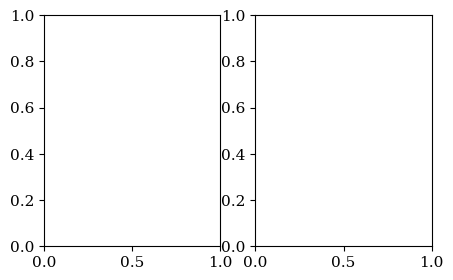

In [33]:
# --- Histogram: Lens vs Satellite Magnitudes (contaminated targets in FOV) ---
import matplotlib.pyplot as plt
import numpy as np

def plot_lens_vs_satellite_magnitudes(matched_df, save=True, by_filter=False):
    """
    Compare lens magnitudes vs satellite magnitudes for targets inside LSST FOV.
    Creates:
      1. Overlaid histogram of lens vs satellite magnitudes
      2. Histogram of (satellite - lens) magnitude differences
    """
    if matched_df is None or len(matched_df) == 0:
        print("No matched data provided.")
        return

    required_cols = {'inside_lsst_fov','lens_magnitude','satellite_magnitude_ab'}
    if not required_cols.issubset(matched_df.columns):
        print(f"Missing required columns: {required_cols - set(matched_df.columns)}")
        return

    # Filter to FOV + valid magnitudes
    df = matched_df[
        (matched_df['inside_lsst_fov'] == True) &
        matched_df['lens_magnitude'].notna() &
        matched_df['satellite_magnitude_ab'].notna()
    ].copy()

    if len(df) == 0:
        print("No rows with both lens and satellite magnitudes inside FOV.")
        return

    print(f"Rows used: {len(df)}")

    lens_mags = df['lens_magnitude'].astype(float)
    sat_mags  = df['satellite_magnitude_ab'].astype(float)
    mag_diff  = sat_mags - lens_mags  # positive => satellite fainter

    # Common binning (magnitudes often ~ 15–30)
    all_vals = np.concatenate([lens_mags.values, sat_mags.values])
    bins = np.linspace(np.nanmin(all_vals), np.nanmax(all_vals), 20)

    set_plot_style()
    fig, axes = plt.subplots(1, 2, figsize=(5,3))
    # fig.subplots_adjust(wspace=0.3, left=0.08, right=0.98, top=0.9, bottom=0.15)

    # Panel 1: Overlaid distributions
    axes[0].hist(lens_mags, bins=bins, alpha=0.6, color=viridis_colors['contaminations'],
                 label='Lens', edgecolor='black', linewidth=0.4)
    axes[0].hist(sat_mags, bins=bins, alpha=0.6, color=viridis_colors['satellites'],
                 label='Satellite', edgecolor='black', linewidth=0.4)

    axes[0].set_xlabel(r'M$_{AB}$ [mag]')
    axes[0].set_ylabel('Number of Contaminations')
    # axes[0].set_title('Contaminated Lens vs Satellite Mag.')
    axes[0].invert_xaxis()  # brighter (smaller) to the left
    axes[0].legend(fontsize=8, loc='upper left')

    # # Stats box
    # stats_text = (
    #     f"Lens: N={len(lens_mags)}\n"
    #     f"  μ={lens_mags.mean():.2f} \n"
    #     f"Satellite: N={len(sat_mags)}\n"
    #     f"  μ={sat_mags.mean():.2f} "
    # )
    # axes[0].text(0.02, 0.98, stats_text, transform=axes[0].transAxes,
    #              va='top', ha='left', fontsize=8,
    #              bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

    # Panel 2: Difference histogram
    diff_bins = np.linspace(mag_diff.min(), mag_diff.max(), 15)
    axes[1].hist(mag_diff, bins=diff_bins, color=viridis_colors['satellites'],
                 alpha=0.75, edgecolor='black', linewidth=0.4)
    # axes[1].axvline(mag_diff.mean(), color='red', linestyle='--', linewidth=1, label= f"μ \={mag_diff.mean():.2f}")
    # axes[1].axvline(mag_diff.median(), color='black', linestyle=':', linewidth=1, label='Median')
    axes[1].set_xlabel(r'$\Delta$ M$_{(satellite-lens)}$ [mag]')
    # axes[1].set_ylabel('Count')
    # axes[1].set_title(r'$\Delta$m = m$_{satellite}$ - m$_{lens}$')
    axes[1].legend(fontsize=8, loc='upper left')

    fig.subplots_adjust(wspace=0.12, left=0.08, right=0.98, top=0.9, bottom=0.15)

    # diff_stats = (
    #     f"N={len(mag_diff)}\n"
    #     f"μ={mag_diff.mean():.2f}\n"
    #     f"σ={mag_diff.std():.2f}\n"
    #     f"med={np.median(mag_diff):.2f}\n"
    #     f"min={mag_diff.min():.2f}\n"
    #     f"max={mag_diff.max():.2f}"
    # )
    # axes[1].text(0.5, 0.98, f"mean ={mag_diff.mean():.2f}" , transform=axes[1].transAxes,
    #              va='top', ha='right', fontsize=8,
    #              bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

    if save:
        out_path = os.path.join(pathToPlots, 'lens_vs_satellite_magnitude_hist.png')
        plt.savefig(out_path, dpi=300, bbox_inches='tight')
        print(f"Saved plot: {out_path}")

    plt.show()

    # Optional per-filter summary
    if by_filter and 'filter_band' in df.columns:
        print("\nPer-filter magnitude difference stats:")
        for filt, sub in df.groupby('filter_band'):
            d = sub['satellite_magnitude_ab'] - sub['lens_magnitude']
            print(f"  {filt}: N={len(d)} μ={d.mean():.2f} σ={d.std():.2f} med={d.median():.2f}")

    return fig, df

# Run (choose matched_targets_df or matched_df depending on variable name)
if 'matched_targets_df' in locals():
    plot_lens_vs_satellite_magnitudes(matched_targets_df, save=True, by_filter=True)
elif 'matched_df' in locals():
    plot_lens_vs_satellite_magnitudes(matched_df, save=True, by_filter=True)
else:
    print("No matched DataFrame with lens magnitudes found.")

Processing separations for month: may25
  Found SEPARATIONS in exposure 2189
1
  Found 1 separations in exposure 2189
  Found SEPARATIONS in exposure 2236
2
  Found 2 separations in exposure 2236
  Found SEPARATIONS in exposure 2239
1
  Found 1 separations in exposure 2239
  Found SEPARATIONS in exposure 2349
1
  Found 1 separations in exposure 2349
  Found SEPARATIONS in exposure 2368
4
  Found 4 separations in exposure 2368
  Found SEPARATIONS in exposure 2377
4
  Found 4 separations in exposure 2377
  Found SEPARATIONS in exposure 2398
33
  Found 33 separations in exposure 2398
  Found SEPARATIONS in exposure 2401
53
  Found 53 separations in exposure 2401
  Found SEPARATIONS in exposure 2413
1
  Found 1 separations in exposure 2413
  Found SEPARATIONS in exposure 2420
1
  Found 1 separations in exposure 2420
  Found SEPARATIONS in exposure 2425
1
  Found 1 separations in exposure 2425
  Found SEPARATIONS in exposure 2426
1
  Found 1 separations in exposure 2426
  Found SEPARATIONS 

NameError: name 'viridis_colors' is not defined

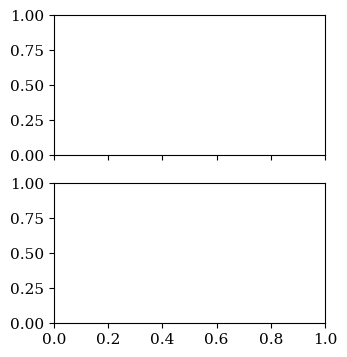

In [34]:
# Extract all separations from monthly exposure data and create histogram
import matplotlib.pyplot as plt
import numpy as np

# Collect all separations from the monthly data


for month in monthly_exposures_data:
    all_separations = []
    separation_info = []
    print(f"Processing separations for month: {month}")
    
    for day in monthly_exposures_data[month]:
        for exp_id in monthly_exposures_data[month][day]:
            exp_data = monthly_exposures_data[month][day][exp_id]
            # print(f"  Checking exposure {exp_data} for separations")
            # Check if separations data exists
            if 'SEPARATIONS' in exp_data:
                sep_data = exp_data['SEPARATIONS']['data']
                print(f"  Found SEPARATIONS in exposure {exp_id}")
                if sep_data is not None and len(sep_data) > 0:
                    # Extract separations if available
                    print(len(sep_data))
                    if 'Separation_arcsec' in sep_data.dtype.names:
                        separations = sep_data['Separation_arcsec']
                        all_separations.extend(separations)
                        
                        # Store additional info for each separation
                        for sep in separations:
                            separation_info.append({
                                'month': month,
                                'day': day,
                                'exp_id': exp_id,
                                'separation': sep
                            })
                        
                        print(f"  Found {len(separations)} separations in exposure {exp_id}")
            
            # Alternative: Check if satellite data has separation information
            elif 'SATELLITE_DATA' in exp_data:
                sat_data = exp_data['SATELLITE_DATA']['data']
                
                if sat_data is not None and len(sat_data) > 0:
                    # Check if separation data exists in satellite data
                    if 'Separation' in sat_data.dtype.names:
                        separations = sat_data['Separation']
                        # Filter out invalid separations (e.g., NaN, negative, or very large values)
                        valid_separations = separations[~np.isnan(separations) & (separations > 0) & (separations < 180)]
                        all_separations.extend(valid_separations)
                        
                        for sep in valid_separations:
                            separation_info.append({
                                'month': month,
                                'day': day,
                                'exp_id': exp_id,
                                'separation': sep
                            })

    print(f"\nTotal separations collected: {len(all_separations)}")

    if len(all_separations) > 0:
        # Convert to numpy array for easier handling
        all_separations = np.array(all_separations)

        # Create separation histogram
        set_plot_style()
        fig, axes = plt.subplots(2, 1, figsize=(3.5, 4), sharex=True)
        
        # Main histogram
        n_bins = 2000
        counts, bins, patches = axes[0].hist(all_separations, bins=n_bins, 
                                            color=viridis_colors['contaminations'], 
                                            alpha=0.7, edgecolor='black', linewidth=0.5)
        
        # axes[0].set_xlabel('Separation [arcseconds]')
        axes[0].set_ylabel('Count')
        # axes[0].set_title(f'Distribution of Separations - Month {month} ({len(all_separations)} total)')
        # axes[0].grid(True, alpha=0.3)
        
        # Add statistics text
        stats_text = f"""Statistics:
        Mean: {np.mean(all_separations):.0f} arcsec
        Median: {np.median(all_separations):.0f} arcsec
        Std: {np.std(all_separations):.0f} arcsec
        Min: {np.min(all_separations):.0f} arcsec
        Max: {np.max(all_separations):.0f} arcsec"""

        axes[0].text(0.1, 1.05, stats_text, transform=axes[0].transAxes,
                    verticalalignment='bottom', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
        
        # Cumulative distribution
        sorted_separations = np.sort(all_separations)
        cumulative = np.arange(1, len(sorted_separations) + 1) / len(sorted_separations)
        axes[1].plot(sorted_separations, cumulative, color=viridis_colors['trails'], linewidth=2)
        axes[1].set_xlabel('Separation [arcseconds]')
        axes[1].set_ylabel('Cumulative Probability')

        # axes[1].set_title('Cumulative Distribution of Separations')
        # axes[1].grid(True, alpha=0.3)
        
        # plt.tight_layout()
        # Add percentile lines
        percentiles = [0.5, 5, 25]
        for p in percentiles:
            value = np.percentile(all_separations, p)
            axes[1].axvline(value, color='red', linestyle='--', alpha=0.5)
            axes[1].text(value+50, 2 * (p + 3) / 100, f'{p}%\n{value:.0f}°',
                        ha='center', va='bottom', bbox=dict(boxstyle='round', edgecolor='none', facecolor='white', alpha=0.8))
        axes[0].set_xlim(np.min(all_separations), np.percentile(all_separations, percentiles[-1])+100)
        axes[1].set_xlim(np.min(all_separations), np.percentile(all_separations, percentiles[-1])+100)
        plt.subplots_adjust(hspace=0.07)
        plt.savefig(os.path.join(pathToPlots, f'separation_histogram_month_{month}.png'), 
                    dpi=300, bbox_inches='tight')
        plt.show()
        
        # Create separation DataFrame for further analysis
        sep_df = pd.DataFrame(separation_info)
        print(f"\nSeparation DataFrame created with {len(sep_df)} records")
        print(sep_df.head())
        
        # Daily separation statistics
        if len(sep_df) > 0:
            daily_sep_stats = sep_df.groupby(['month', 'day']).agg({
                'separation': ['count', 'mean', 'median', 'std', 'min', 'max']
            }).reset_index()
            
            daily_sep_stats.columns = ['month', 'day', 'count', 'mean_sep', 'median_sep', 'std_sep', 'min_sep', 'max_sep']
            print("\nDaily separation statistics:")
            print(daily_sep_stats)
            
    else:
        print("No separation data found in the exposure files.")
        print("Available data columns in CONTAMINATED_TARGETS:")
        
        # Debug: Check what columns are actually available
        for month in monthly_exposures_data:
            for day in monthly_exposures_data[month]:
                for exp_id in monthly_exposures_data[month][day]:
                    exp_data = monthly_exposures_data[month][day][exp_id]
                    if 'CONTAMINATED_TARGETS' in exp_data:
                        cont_data = exp_data['CONTAMINATED_TARGETS']['data']
                        if cont_data is not None and len(cont_data) > 0:
                            print(f"  Available columns: {cont_data.dtype.names}")
                            break
                    elif 'SATELLITE_DATA' in exp_data:
                        sat_data = exp_data['SATELLITE_DATA']['data']
                        if sat_data is not None and len(sat_data) > 0:
                            print(f"  Available columns in SATELLITE_DATA: {sat_data.dtype.names}")
                            break

    year        month  total_visits  total_events  fov_total_targets_observed  \
0   2025        may25          2835           564                       70672   
1   2025       june25          1988           390                       37134   
2   2025       july25          3296           683                       26713   
3   2025     august25          3090           692                       42685   
4   2025  september25          3012           622                       36716   
5   2025    october25          5381          1182                       80228   
6   2025   november25          4225          1111                       48324   
7   2025   december25          5106          1381                       69581   
8   2026    january26          3778           987                       63260   
9   2026   february26          2936           737                       39355   
10  2026      march26          3775           921                       32299   
11  2026      april26       

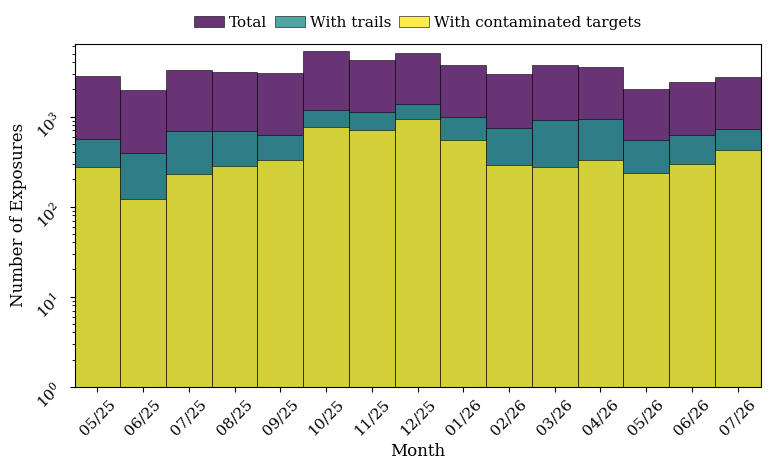

In [35]:
#Create a summary table of contamination statistics per month
import pandas as pd
csv_file = os.path.join(pathToFiles, 'monthly_summary.csv')
csv_file_contamination = os.path.join(pathToFiles, 'monthly_contamination_summary_df_0.csv')
summary_data = pd.read_csv(csv_file)
contamination_summary_data = pd.read_csv(csv_file_contamination)
# sort contamination summary by month and year
contamination_summary_data['month'] = contamination_summary_data['month'].str.capitalize()
contamination_summary_data['month'] = pd.Categorical(contamination_summary_data['month'],
                                                    categories=['May25', 'June25', 'July25', 'August25', 'September25', 'October25', 'November25', 'December25', 'January26', 'February26', 'March26', 'April26', 'May26', 'June26', 'July26'],)
contamination_summary_data = contamination_summary_data.sort_values(['month'])
print(summary_data)
print(contamination_summary_data)
viridis_colors = {
    'trails': '#440154',        # Dark purple
    'satellites': '#21918c',    # Teal
    'events': '#fde725',        # Yellow
    'contaminations': '#482878'  # Deep purple
}
print(viridis_colors )

fig, ax = plt.subplots(figsize=(7,3.5))
fig.subplots_adjust(top=0.99, right=0.99, left=0.01 ,bottom=0.01)
set_plot_style()
plt.rcParams['font.size'] = 12
plt.rcParams['axes.labelsize'] = 12
print(summary_data.columns)
# Create month array with capitalized month names and years
# summary_data['month'] = summary_data['month'].str.capitalize() + '\n ' + summary_data['year'].astype(str)
summary_data['month'] = ['05/25', '06/25', '07/25', '08/25', '09/25', '10/25', '11/25', '12/25', '01/26', '02/26', '03/26', '04/26', '05/26', '06/26', '07/26']
ax.bar(summary_data['month'], summary_data['total_visits'], 
       color=viridis_colors['trails'], alpha=0.8, label='Total', width=1.0, edgecolor='black', linewidth=0.5)
ax.bar(summary_data['month'], summary_data['total_events'], 
       color=viridis_colors['satellites'], alpha=0.8, label='With trails', width=1.0, edgecolor='black', linewidth=0.5)
ax.bar(summary_data['month'], contamination_summary_data['total_contaminations'], 
       color=viridis_colors['events'], alpha=0.8, label='With contaminated targets', width=1.0, edgecolor='black', linewidth=0.5)
# ax.bar(summary_data['month'], summary_data['fov_contaminated_targets'], facecolor='none', hatch='//',
#        edgecolor=viridis_colors['contaminations'], alpha=0.8, label='Contaminations \nin LSST FOV', width=1.0)
ax.set_xlabel('Month')
ax.set_xlim(-0.5, 14.5)
ax.set_ylim(1, summary_data['total_visits'].max()*1.2)
ax.tick_params(rotation=45)
ax.set_ylabel('Number of Exposures')
ax.set_yscale('log')
ax.legend(bbox_to_anchor=(0.5, 1.), loc='lower center', ncol=4, fontsize=11, handletextpad=0.3, columnspacing=0.5)
# plt.tight_layout()
plt.show()
fig.savefig(os.path.join(pathToPlots, 'monthly_summary_bar_chart_events.png'), dpi=300, bbox_inches='tight')

Index(['year', 'month', 'total_visits', 'total_events',
       'fov_total_targets_observed', 'fov_unique_targets_observed',
       'total_contaminated_targets', 'fov_contaminated_targets'],
      dtype='object')


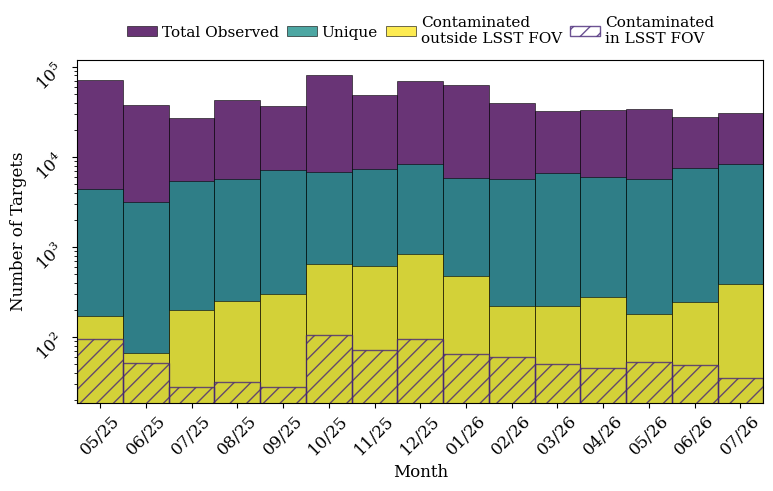

In [36]:
#Create a summary table of contamination statistics per month
# import pandas as pd
# csv_file = os.path.join(pathToFiles, 'monthly_summary.csv')
# csv_file_contamination = os.path.join(pathToFiles, 'monthly_contamination_summary_df_0.csv')
# summary_data = pd.read_csv(csv_file)
# contamination_summary_data = pd.read_csv(csv_file_contamination)
# print(summary_data)
# print(contamination_summary_data)
# viridis_colors = {
#     'trails': '#440154',        # Dark purple
#     'satellites': '#21918c',    # Teal
#     'events': '#fde725',        # Yellow
#     'contaminations': '#482878'  # Deep purple
# }
# print(viridis_colors )

fig, ax = plt.subplots(figsize=(7,3.5))
fig.subplots_adjust(top=0.99, right=0.99, left=0.01 ,bottom=0.01)
set_plot_style()
plt.rcParams['font.size'] = 12
plt.rcParams['axes.labelsize'] = 12
print(summary_data.columns)
# Create month array with capitalized month names and years
# summary_data['month'] = summary_data['month'].str.capitalize() + '\n ' + summary_data['year'].astype(str)
ax.bar(summary_data['month'], summary_data['fov_total_targets_observed'], 
       color=viridis_colors['trails'], alpha=0.8, label='Total Observed', width=1.0, edgecolor='black', linewidth=0.5)
ax.bar(summary_data['month'], summary_data['fov_unique_targets_observed'], 
       color=viridis_colors['satellites'], alpha=0.8, label='Unique', width=1.0, edgecolor='black', linewidth=0.5)
ax.bar(summary_data['month'], contamination_summary_data['non_fov_contaminations'], 
       color=viridis_colors['events'], alpha=0.8, label='Contaminated\noutside LSST FOV', width=1.0, edgecolor='black', linewidth=0.5)
ax.bar(summary_data['month'], contamination_summary_data['fov_contaminations'], facecolor='none', hatch='//',
       edgecolor=viridis_colors['contaminations'], alpha=0.8, label='Contaminated\nin LSST FOV', width=1.0)
ax.set_xlabel('Month')
ax.set_xlim(-0.5, 14.5)
#ax.set_ylim(1, summary_data['total_visits'].max()*1.2)
ax.tick_params(rotation=45)
ax.set_ylabel('Number of Targets')
ax.set_yscale('log')
ax.legend(bbox_to_anchor=(0.5, 1.), loc='lower center', ncol=4, fontsize=11, handletextpad=0.3, columnspacing=0.5)
# plt.tight_layout()
plt.show()
fig.savefig(os.path.join(pathToPlots, 'monthly_summary_bar_chart_targets.png'), dpi=300, bbox_inches='tight')

## PLANCK vs SLED

In [32]:
def load_important_clusters_csv_fixed(csv_path):
    """
    Load and validate the important clusters CSV file with endianness fix
    """
    print(f"Loading important clusters from: {csv_path}")

    try:
        if csv_path.endswith('.fits') or csv_path.endswith('.fit'):
            with fits.open(csv_path) as hdu_list:
                hdu_list.info()
                print(f"Data is a FITS BinTableHDU with columns: {hdu_list[1].columns.names}")
                data = hdu_list[2].data if len(hdu_list) > 2 and hdu_list[2].data is not None else hdu_list[1].data
                print(f"Extracted {len(data)} lens records from FITS data")
                
                # FIXED: Convert to DataFrame and fix endianness
                df = pd.DataFrame(data) if len(data) > 0 else pd.DataFrame()
                
                # Convert numeric columns to native byte order
                for col in df.select_dtypes(include=[np.number]).columns:
                    df[col] = df[col].astype(df[col].dtype.newbyteorder('='))
                
                return df

        df = pd.read_csv(csv_path)
        data = df.to_dict(orient='records')

        print(f"Successfully loaded CSV data")
        print(f"Data type: {type(data)}")
        
        return data
        
    except Exception as e:
        print(f"Error loading file: {e}")
        return None

def match_important_clusters_with_name_validation(planck_data, sled_df, tolerance_arcsec=1.0):
    """
    Match FOV contaminated targets with important clusters based on RA/Dec coordinates
    and validate with name matching
    """
    print(f"=== MATCHING TARGETS WITH IMPORTANT CLUSTERS (WITH NAME VALIDATION) ===")
    print(f"PLANCK targets: {len(planck_data)}")
    print(f"SLED targets: {len(sled_df)}")
    print(f"Matching tolerance: {tolerance_arcsec} arcsec")
    
    # Convert to native byte order to avoid endianness issues
    planck_df = planck_data.copy()
    

    print(f"Targets in PLANCK: {len(planck_df)}")
       # Convert to native byte order to avoid endianness issues
    sled_df = sled_data.copy()
    
    # Convert all numeric columns to native byte order
    for col in sled_df.select_dtypes(include=[np.number]).columns:
        sled_df[col] = sled_df[col].astype(sled_df[col].dtype.newbyteorder('='))
    
    print(f"Targets in SLED: {len(sled_df)}")

    # Create coordinate objects and name mapping for clusters
    sled_coords = []
    
    for i in range(len(sled_df)):
        ra_t = float(sled_df['RA'].iloc[i])
        dec_t = float(sled_df['DEC'].iloc[i])
        name_t = sled_df['SLEDName'].iloc[i] if 'SLEDName' in sled_df.columns else ''
        
        sled_coords.append(SkyCoord(
            ra=ra_t * u.deg,
            dec=dec_t * u.deg,
            frame='icrs'
        ))
    
    sled_coords = SkyCoord(sled_coords)
    
    # Create coordinate objects and name list for SLED targets
    coords = []

    for cluster in planck_data:
        ra_l = float(cluster['RA1deg'])
        dec_l = float(cluster['DE1deg'])
        coords.append(SkyCoord(
            ra=ra_l * u.deg,
            dec=dec_l * u.deg,
            frame='icrs'
        ))
    
    planck_coords = SkyCoord(coords)
    
    print(f"Created coordinate objects for matching")
    
    # Use the filtered DataFrame directly
    matched_df_planck = sled_df.copy()

    # Initialize columns properly
    matched_df_planck['planck_match_separation_arcsec'] = np.nan
    matched_df_planck['PLANCKName'] = None
    matched_df_planck['planck_id'] = None
 
    
    # Perform coordinate matching for clusters
    print(f'Size of planck coords: {len(planck_coords)}, size of sled coords: {len(sled_coords)}')
    tolerance = tolerance_arcsec * u.arcsec
    idx_lens_cluster, idx_cluster, d2d_cluster, d3d_cluster = sled_coords.search_around_sky(planck_coords, tolerance)
    print(f"Found {len(idx_cluster)} coordinate matches within {tolerance_arcsec} arcsec tolerance")

    # Track matching statistics
    coordinate_matches = 0
    coordinate_only = 0


    if len(idx_cluster) > 0:    
        # Fill in the matched data using correct indices
        for i, (target_idx, cluster_idx) in enumerate(zip(idx_lens_cluster, idx_cluster)):
            separation_arcsec = d2d_cluster[i].to(u.arcsec).value

            # Get cluster data
            cluster_entry = planck_data[target_idx]



            # Fill in basic matching info using iloc for position-based indexing
            matched_df_planck.iloc[cluster_idx, matched_df_planck.columns.get_loc('planck_match_separation_arcsec')] = separation_arcsec
            matched_df_planck.iloc[cluster_idx, matched_df_planck.columns.get_loc('PLANCKName')] = cluster_entry['PSZ2Name'] if 'PSZ2Name' in cluster_entry else None
            matched_df_planck.iloc[cluster_idx, matched_df_planck.columns.get_loc('planck_id')] = cluster_entry['ID'] if 'ID' in cluster_entry else None
            # Categorize match type


        print(f"\nMatching Results:")
        print(f"  Total coordinate matches: {coordinate_matches}")
        print(f"  Coordinate-only matches (name mismatch): {coordinate_only}")
     
        if coordinate_matches > 0:
            # Statistics for all matches
            sep_values = matched_df_planck.loc[matched_df_planck['PLANCKName'].notna(), 'planck_match_separation_arcsec']
            if len(sep_values) > 0:
                print(f"  Mean separation: {sep_values.mean():.3f} arcsec")
                print(f"  Max separation: {sep_values.max():.3f} arcsec")

            
            # Statistics for name-validated matches only
            name_validated_mask = (matched_df_planck['PLANCKName'].notna()) & (matched_df_planck['name_match'] == True)
            if name_validated_mask.sum() > 0:
                validated_sep_values = matched_df_planck.loc[name_validated_mask, 'planck_match_separation_arcsec']
                print(f"  Mean separation (name-validated): {validated_sep_values.mean():.3f} arcsec")
                print(f"  Max separation (name-validated): {validated_sep_values.max():.3f} arcsec")

    return matched_df_planck

# Also create a function to analyze potential name matches without coordinate constraints

# Usage example:
if os.path.exists('/data/a.saricaoglu/repo/RubinsForge/Skyfield/planck-z2s_brightest_galaxies.csv'):
    planck_data = load_important_clusters_csv_fixed('/data/a.saricaoglu/repo/RubinsForge/Skyfield/planck-z2s_brightest_galaxies.csv')
    sled_data = load_important_clusters_csv_fixed('/data/a.saricaoglu/repo/RubinsForge/in_LSST_footprint_coordinates.fits')

    if planck_data is not None and sled_data is not None and len(sled_data) > 0:
        # Run matching with name validation
        matched_important_df = match_important_clusters_with_name_validation(
            planck_data, sled_data, tolerance_arcsec=1)

        # Run name-only analysis

        # Save results with additional name validation columns
        planck_matches = matched_important_df['PLANCKName'].notna()
        n_matches = int(planck_matches.sum())

        if n_matches > 0:
            important_matches_path = os.path.join(pathToFiles, 'important_PLANCK_brightest_SLED_matches_with_names.csv')
            important_only = matched_important_df.loc[planck_matches].copy()
            important_only.to_csv(important_matches_path, index=False)
            print(f"Important cluster matches saved to: {important_matches_path}")

        else:
            print("No matches found with important clusters")

Loading important clusters from: /data/a.saricaoglu/repo/RubinsForge/Skyfield/planck-z2s_brightest_galaxies.csv
Successfully loaded CSV data
Data type: <class 'list'>
Loading important clusters from: /data/a.saricaoglu/repo/RubinsForge/in_LSST_footprint_coordinates.fits
Filename: /data/a.saricaoglu/repo/RubinsForge/in_LSST_footprint_coordinates.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       4   ()      
  1  In_LSST_Footprint    1 BinTableHDU     21   13740R x 4C   [12A, 28A, D, D]   
  2  In_Euclid_Lowdust_Region    1 BinTableHDU     21   13019R x 4C   [12A, 28A, D, D]   
Data is a FITS BinTableHDU with columns: ['Target_no', 'SLEDName', 'RA', 'DEC']
Extracted 13019 lens records from FITS data
=== MATCHING TARGETS WITH IMPORTANT CLUSTERS (WITH NAME VALIDATION) ===
PLANCK targets: 306
SLED targets: 13019
Matching tolerance: 1 arcsec
Targets in PLANCK: 306
Targets in SLED: 13019
Created coordinate objects for matching
Size of pla

### Contaminated in FOV target matching with the 'The Brightest Galaxies in Massive Galaxy Clusters from Planck-SZ2' 
Brightest cluster galaxies (BCGs) in 306 massive clusters in the Southern skies at redshifts of z > 0.1 by Smith, Joshua C., Ryczanowski, Dan ...
https://ui.adsabs.harvard.edu/link_gateway/2023RNAAS...7...51S/arxiv:2304.06624
csv: planck-sz2-brightest_galaxies.csv

In [33]:
def load_important_clusters_csv(csv_path):
    """
    Load and validate the important clusters CSV file
    """
    print(f"Loading important clusters from: {csv_path}")

    try:
        df = pd.read_csv(csv_path)
        data = df.to_dict(orient='records')

        print(f"Successfully loaded CSV data")
        print(f"Data type: {type(data)}")
        
        if isinstance(data, list):
            print(f"CSV contains {len(data)} lens records")
            # Show structure of first record
            if len(data) > 0:
                print(f"First record keys: {data[0].keys()}")
                print(f"First record: {data[0]}")
        elif isinstance(data, dict):
            print(f"JSON is a dictionary with keys: {data.keys()}")
            metadata = data['metadata'] if 'metadata' in data else {}
            print(f"Metadata: {metadata if metadata else 'N/A'}")
            data = data['data'] if 'data' in data else []
            print(f"Extracted {len(data)} lens records from 'data' entry")

        return data
        
    except FileNotFoundError:
        print(f"CSV file not found at: {csv_path}")
        return None
    except pd.errors.EmptyDataError:
        print(f"CSV file is empty: {csv_path}")
        return None
    except Exception as e:
        print(f"Error loading CSV: {e}")
        return None

# Load the data with debugging
# important_clusters_data = load_important_clusters_csv('/data/a.saricaoglu/repo/RubinsForge/Skyfield/planck-sz2-brightest_galaxies.csv')

def match_important_clusters(fov_targets_df, important_clusters_data, tolerance_arcsec=1.0):
    """
    Match FOV contaminated targets with important clusters based on RA/Dec coordinates
    """
    print(f"=== MATCHING TARGETS WITH IMPORTANT CLUSTERS ===")
    print(f"FOV targets: {len(fov_targets_df)}")
    print(f"Important clusters: {len(important_clusters_data)}")
    print(f"Matching tolerance: {tolerance_arcsec} arcsec")
    
    # Filter for FOV targets and reset index to avoid misalignment
    fov_only_df = fov_targets_df[fov_targets_df['inside_lsst_fov']==True].copy().reset_index(drop=True)
    print(f"Targets inside FOV: {len(fov_only_df)}")
    
    # Create coordinate objects for matching
    cluster_coords = []
    brightest_coords = []
    second_brightest_coords = []
    
    for cluster in important_clusters_data:
        ra_l = float(cluster['RAJ2000'])
        dec_l = float(cluster['DEJ2000'])
        cluster_coords.append(SkyCoord(
            ra=ra_l * u.deg,
            dec=dec_l * u.deg,
            frame='icrs'
        ))
        
        if 'RA1deg' in cluster and 'DE1deg' in cluster:
            ra_g = float(cluster['RA1deg'])
            dec_g = float(cluster['DE1deg'])
            brightest_coords.append(SkyCoord(
                ra=ra_g * u.deg,
                dec=dec_g * u.deg,
                frame='icrs'
            ))
        
        if 'RA2deg' in cluster and 'DE2deg' in cluster:
            ra_g2 = float(cluster['RA2deg'])
            dec_g2 = float(cluster['DE2deg'])
            second_brightest_coords.append(SkyCoord(
                ra=ra_g2 * u.deg,
                dec=dec_g2 * u.deg,
                frame='icrs'
            ))
    
    cluster_coords = SkyCoord(cluster_coords)
    brightest_coords = SkyCoord(brightest_coords) if len(brightest_coords) == len(important_clusters_data) else None
    second_brightest_coords = SkyCoord(second_brightest_coords) if len(second_brightest_coords) == len(important_clusters_data) else None

    coords = []
    for i in range(len(fov_only_df)):
        ra_t = float(fov_only_df['cont_target_ra_deg'].iloc[i])
        dec_t = float(fov_only_df['cont_target_dec_deg'].iloc[i])
        coords.append(SkyCoord(
            ra=ra_t * u.deg,
            dec=dec_t * u.deg,
            frame='icrs'
        ))
    target_coords = SkyCoord(coords)
    
    print(f"Created coordinate objects for matching")
    
    # Use the filtered DataFrame directly
    matched_df_cluster = fov_only_df.copy()
    
    # FIXED: Initialize ALL columns properly
    matched_df_cluster['cluster_match_separation_arcsec'] = np.nan
    matched_df_cluster['PSZ2Name'] = None
    matched_df_cluster['PSZ2Index'] = None  # FIXED: Add this missing column
    matched_df_cluster['brightest_match_separation_arcsec'] = np.nan
    matched_df_cluster['ID1'] = None
    matched_df_cluster['second_brightest_match_separation_arcsec'] = np.nan
    matched_df_cluster['ID2'] = None

    # Perform coordinate matching for clusters
    tolerance = tolerance_arcsec * u.arcsec
    idx_lens_cluster, idx_cluster, d2d_cluster, d3d_cluster = target_coords.search_around_sky(cluster_coords, tolerance)
    print(f"Found {len(idx_cluster)} cluster matches within {tolerance_arcsec} arcsec tolerance")

    if len(idx_cluster) > 0:    
        # Fill in the matched data using correct indices
        for i, (lens_idx, target_idx) in enumerate(zip(idx_lens_cluster, idx_cluster)):
            separation_arcsec = d2d_cluster[i].to(u.arcsec).value

            # Get cluster data
            cluster_entry = important_clusters_data[lens_idx]

            # Fill in basic matching info using iloc for position-based indexing
            matched_df_cluster.iloc[target_idx, matched_df_cluster.columns.get_loc('cluster_match_separation_arcsec')] = separation_arcsec
            matched_df_cluster.iloc[target_idx, matched_df_cluster.columns.get_loc('PSZ2Index')] = cluster_entry['PSZ2Index'] if 'PSZ2Index' in cluster_entry else None
            matched_df_cluster.iloc[target_idx, matched_df_cluster.columns.get_loc('PSZ2Name')] = cluster_entry['PSZ2Name'] if 'PSZ2Name' in cluster_entry else None

        # Count matches and provide statistics
        n_matched = matched_df_cluster['PSZ2Name'].notna().sum()
        match_rate = n_matched / len(matched_df_cluster) * 100 if len(matched_df_cluster) > 0 else 0

        print(f"\nCluster Matching Results:")
        print(f"  Targets matched to important clusters: {n_matched}")
        print(f"  Match rate: {match_rate:.1f}%")
        
        if n_matched > 0:
            print(f"  Mean separation: {matched_df_cluster['cluster_match_separation_arcsec'].mean():.3f} arcsec")
            print(f"  Max separation: {matched_df_cluster['cluster_match_separation_arcsec'].max():.3f} arcsec")

            # Show matched cluster names
            matched_clusters = matched_df_cluster[matched_df_cluster['PSZ2Name'].notna()]['PSZ2Name'].unique()
            print(f"  Matched important clusters: {list(matched_clusters)}")

    # Brightest galaxy matching
    if brightest_coords is not None:
        idx_lens_bright, idx_brightest, d2d_bright, d3d_bright = target_coords.search_around_sky(brightest_coords, tolerance)
        print(f"Found {len(idx_brightest)} brightest galaxy matches within {tolerance_arcsec} arcsec tolerance")

        if len(idx_brightest) > 0:    
            # Fill in the matched data using correct indices
            for i, (lens_idx, target_idx) in enumerate(zip(idx_lens_bright, idx_brightest)):
                separation_arcsec = d2d_bright[i].to(u.arcsec).value

                # Get cluster data
                brightest_entry = important_clusters_data[lens_idx]

                # Fill in basic matching info using iloc for position-based indexing
                matched_df_cluster.iloc[target_idx, matched_df_cluster.columns.get_loc('brightest_match_separation_arcsec')] = separation_arcsec
                matched_df_cluster.iloc[target_idx, matched_df_cluster.columns.get_loc('ID1')] = brightest_entry['ID1'] if 'ID1' in brightest_entry else None
                matched_df_cluster.iloc[target_idx, matched_df_cluster.columns.get_loc('PSZ2Name')] = brightest_entry['PSZ2Name'] if 'PSZ2Name' in brightest_entry else None

            # Count matches and provide statistics
            n_matched = matched_df_cluster['ID1'].notna().sum()
            match_rate = n_matched / len(matched_df_cluster) * 100 if len(matched_df_cluster) > 0 else 0

            print(f"\nBrightest Galaxy Matching Results:")
            print(f"  Targets matched to brightest galaxies: {n_matched}")
            print(f"  Match rate: {match_rate:.1f}%")
            
            if n_matched > 0:
                print(f"  Mean separation: {matched_df_cluster['brightest_match_separation_arcsec'].mean():.3f} arcsec")
                print(f"  Max separation: {matched_df_cluster['brightest_match_separation_arcsec'].max():.3f} arcsec")

                # Show matched cluster names
                matched_clusters = matched_df_cluster[matched_df_cluster['ID1'].notna()]['ID1'].unique()
                print(f"  Matched brightest galaxies: {list(matched_clusters)}")

    # Second brightest galaxy matching
    if second_brightest_coords is not None:
        idx_lens_second, idx_second, d2d_second, d3d_second = target_coords.search_around_sky(second_brightest_coords, tolerance)
        print(f"Found {len(idx_second)} second brightest galaxy matches within {tolerance_arcsec} arcsec tolerance")

        if len(idx_second) > 0:    
            # Fill in the matched data using correct indices
            for i, (lens_idx, target_idx) in enumerate(zip(idx_lens_second, idx_second)):
                separation_arcsec = d2d_second[i].to(u.arcsec).value

                # Get cluster data
                cluster_entry = important_clusters_data[lens_idx]

                # Fill in basic matching info using iloc for position-based indexing
                matched_df_cluster.iloc[target_idx, matched_df_cluster.columns.get_loc('second_brightest_match_separation_arcsec')] = separation_arcsec
                matched_df_cluster.iloc[target_idx, matched_df_cluster.columns.get_loc('ID2')] = cluster_entry['ID2'] if 'ID2' in cluster_entry else None
                matched_df_cluster.iloc[target_idx, matched_df_cluster.columns.get_loc('PSZ2Name')] = cluster_entry['PSZ2Name'] if 'PSZ2Name' in cluster_entry else None
           
            # Count matches and provide statistics
            n_matched = matched_df_cluster['ID2'].notna().sum()
            match_rate = n_matched / len(matched_df_cluster) * 100 if len(matched_df_cluster) > 0 else 0

            print(f"\nSecond Brightest Galaxy Matching Results:")
            print(f"  Targets matched to second brightest galaxies: {n_matched}")
            print(f"  Match rate: {match_rate:.1f}%")
            
            if n_matched > 0:
                print(f"  Mean separation: {matched_df_cluster['second_brightest_match_separation_arcsec'].mean():.3f} arcsec")
                print(f"  Max separation: {matched_df_cluster['second_brightest_match_separation_arcsec'].max():.3f} arcsec")

                # FIXED: Use correct column name
                matched_clusters = matched_df_cluster[matched_df_cluster['ID2'].notna()]['ID2'].unique()
                print(f"  Matched second brightest galaxies: {list(matched_clusters)}")

    return matched_df_cluster

csv_path = '/data/a.saricaoglu/repo/RubinsForge/Skyfield/planck-z2s_brightest_galaxies.csv'
# Now run the matching with proper error handling
if os.path.exists(csv_path):
    important_clusters_data = load_important_clusters_csv(csv_path)

    if important_clusters_data is not None and 'fov_targets_df' in locals() and len(fov_targets_df) > 0:
        matched_important_df = match_important_clusters(fov_targets_df, important_clusters_data, tolerance_arcsec=1.0)

        # Save results if matches found
        if matched_important_df['PSZ2Name'].notna().sum() > 0:
            important_matches_path = os.path.join(pathToFiles, 'planck-sz2_cluster_matches.csv')
            important_only = matched_important_df[matched_important_df['PSZ2Index'].notna()]
            important_only.to_csv(important_matches_path, index=False)
            print(f"Important cluster matches saved to: {important_matches_path}")
        else:
            print("No matches found with important clusters")
        if matched_important_df['ID1'].notna().sum() > 0:
            brightest_matches_path = os.path.join(pathToFiles, 'planck-sz2_brightest_galaxy_matches.csv')
            brightest_only = matched_important_df[matched_important_df['ID1'].notna()]
            brightest_only.to_csv(brightest_matches_path, index=False)
            print(f"Brightest galaxy matches saved to: {brightest_matches_path}")
        else:
            print("No matches found with brightest galaxies")
        if matched_important_df['ID2'].notna().sum() > 0:
            second_brightest_matches_path = os.path.join(pathToFiles, 'planck-sz2_second_brightest_galaxy_matches.csv')
            second_brightest_only = matched_important_df[matched_important_df['ID2'].notna()]
            second_brightest_only.to_csv(second_brightest_matches_path, index=False)
            print(f"Second brightest galaxy matches saved to: {second_brightest_matches_path}")
        else:
            print("No matches found with second brightest galaxies")
    else:
        print("Failed to load important clusters data or no FOV targets available")
    
else:
    print(f"csv file not found at: {csv_path}")

Loading important clusters from: /data/a.saricaoglu/repo/RubinsForge/Skyfield/planck-z2s_brightest_galaxies.csv
Successfully loaded CSV data
Data type: <class 'list'>
CSV contains 306 lens records
First record keys: dict_keys(['Index', 'PSZ2Index', 'PSZ2Name', 'RAJ2000', 'DEJ2000', 'ePos', 'z', 'Altz', 'MassEst', 'SNR', 'ID1', 'RA1deg', 'DE1deg', 'Jmag1', 'Ksmag1', 'J-Ks1', 'ID2', 'RA2deg', 'DE2deg', 'Jmag2', 'Ksmag2', 'J-Ks2', 'Com'])
First record: {'Index': 1, 'PSZ2Index': 3, 'PSZ2Name': 'PSZ2 G000.40-41.86', 'RAJ2000': 316.0844846, 'DEJ2000': -41.3541688, 'ePos': 2.427383, 'z': 0.1651, 'Altz': nan, 'MassEst': 5.297053, 'SNR': 9.70428, 'ID1': 473188797243, 'RA1deg': 316.019546392006, 'DE1deg': -41.3749079019024, 'Jmag1': 14.5462379455566, 'Ksmag1': 13.3828229904175, 'J-Ks1': 1.19786892086267, 'ID2': 472848649348, 'RA2deg': 316.077866135868, 'DE2deg': -41.3461637896512, 'Jmag2': 14.5465469360352, 'Ksmag2': 13.4433660507202, 'J-Ks2': 1.17239045724273, 'Com': 0}
=== MATCHING TARGETS WIT

## DES vs SLED

In [34]:
def load_important_clusters_csv_fixed(csv_path):
    """
    Load and validate the important clusters CSV file with endianness fix
    """
    print(f"Loading important clusters from: {csv_path}")

    try:
        if csv_path.endswith('.fits') or csv_path.endswith('.fit'):
            with fits.open(csv_path) as hdu_list:
                hdu_list.info()
                print(f"Data is a FITS BinTableHDU with columns: {hdu_list[1].columns.names}")
                data = hdu_list[2].data if len(hdu_list) > 2 and hdu_list[2].data is not None else hdu_list[1].data
                print(f"Extracted {len(data)} lens records from FITS data")
                
                # FIXED: Convert to DataFrame and fix endianness
                df = pd.DataFrame(data) if len(data) > 0 else pd.DataFrame()
                
                # Convert numeric columns to native byte order
                for col in df.select_dtypes(include=[np.number]).columns:
                    df[col] = df[col].astype(df[col].dtype.newbyteorder('='))
                
                return df

        df = pd.read_csv(csv_path)
        data = df.to_dict(orient='records')

        print(f"Successfully loaded CSV data")
        print(f"Data type: {type(data)}")
        
        return data
        
    except Exception as e:
        print(f"Error loading file: {e}")
        return None

def match_important_clusters_with_name_validation(sled_data, important_clusters_data, tolerance_arcsec=1.0):
    """
    Match FOV contaminated targets with important clusters based on RA/Dec coordinates
    and validate with name matching
    """
    print(f"=== MATCHING TARGETS WITH IMPORTANT CLUSTERS (WITH NAME VALIDATION) ===")
    print(f"SLED targets: {len(sled_data)}")
    print(f"Important clusters: {len(important_clusters_data)}")
    print(f"Matching tolerance: {tolerance_arcsec} arcsec")
    
    # Convert to native byte order to avoid endianness issues
    sled_df = sled_data.copy()
    
    # Convert all numeric columns to native byte order
    for col in sled_df.select_dtypes(include=[np.number]).columns:
        sled_df[col] = sled_df[col].astype(sled_df[col].dtype.newbyteorder('='))
    
    print(f"Targets in SLED: {len(sled_df)}")
    
    # Create coordinate objects and name mapping for clusters
    cluster_coords = []
    cluster_names = []
    
    for cluster in important_clusters_data:
        ra_l = float(cluster['RAdeg'])
        dec_l = float(cluster['DEdeg'])
        name_l = cluster.get('Name', '').strip() if cluster.get('Name') else ''
        
        cluster_coords.append(SkyCoord(
            ra=ra_l * u.deg,
            dec=dec_l * u.deg,
            frame='icrs'
        ))
        cluster_names.append(name_l)
    
    cluster_coords = SkyCoord(cluster_coords)
    
    # Create coordinate objects and name list for SLED targets
    coords = []
    sled_names = []
    
    for i in range(len(sled_df)):
        ra_t = float(sled_df['RA'].iloc[i])
        dec_t = float(sled_df['DEC'].iloc[i])
        name_t = sled_df['SLEDName'].iloc[i] if 'SLEDName' in sled_df.columns else ''
        
        coords.append(SkyCoord(
            ra=ra_t * u.deg,
            dec=dec_t * u.deg,
            frame='icrs'
        ))
        sled_names.append(str(name_t).strip() if name_t else '')
    
    target_coords = SkyCoord(coords)
    
    print(f"Created coordinate objects for matching")
    
    # Use the filtered DataFrame directly
    matched_df_des = sled_df.copy()
    
    # Initialize columns properly
    matched_df_des['des_match_separation_arcsec'] = np.nan
    matched_df_des['DESName'] = None
    matched_df_des['des_id'] = None
    matched_df_des['name_match'] = False  # New column to track name matches
    matched_df_des['match_type'] = None   # Track type of match
    
    # Helper function to check if names match
    def names_match(sled_name, des_name):
        """Check if SLED and DES names correspond"""
        if not sled_name or not des_name:
            return False
        
        # Remove spaces and convert to upper case for comparison
        sled_clean = sled_name.replace(' ', '').upper()
        des_clean = des_name.replace(' ', '').upper()
        
        # Check if DES name is "DES" + SLED name
        if des_clean == f"DES{sled_clean}":
            return True
        
        # Also check without the "J" prefix if SLED name starts with "J"
        if sled_clean.startswith('J'):
            sled_without_j = sled_clean[1:]
            if des_clean == f"DES{sled_without_j}" or des_clean == f"DESJ{sled_without_j}":
                return True
        
        return False
    
    # Perform coordinate matching for clusters
    print(f'Size of target coords: {len(target_coords)}, size of des coords: {len(cluster_coords)}')
    tolerance = tolerance_arcsec * u.arcsec
    idx_lens_cluster, idx_cluster, d2d_cluster, d3d_cluster = target_coords.search_around_sky(cluster_coords, tolerance)
    print(f"Found {len(idx_cluster)} coordinate matches within {tolerance_arcsec} arcsec tolerance")

    # Track matching statistics
    coordinate_matches = 0
    name_matches = 0
    both_matches = 0
    coordinate_only = 0
    name_mismatch = 0

    if len(idx_cluster) > 0:    
        # Fill in the matched data using correct indices
        for i, (target_idx, cluster_idx) in enumerate(zip(idx_lens_cluster, idx_cluster)):
            separation_arcsec = d2d_cluster[i].to(u.arcsec).value

            # Get cluster data
            cluster_entry = important_clusters_data[target_idx]
            cluster_name = cluster_names[target_idx]
            sled_name = sled_names[cluster_idx]

            # Check if names match
            name_match = names_match(sled_name, cluster_name)

            # Fill in basic matching info using iloc for position-based indexing
            matched_df_des.iloc[cluster_idx, matched_df_des.columns.get_loc('des_match_separation_arcsec')] = separation_arcsec
            matched_df_des.iloc[cluster_idx, matched_df_des.columns.get_loc('DESName')] = cluster_name
            matched_df_des.iloc[cluster_idx, matched_df_des.columns.get_loc('name_match')] = name_match
            matched_df_des.iloc[cluster_idx, matched_df_des.columns.get_loc('des_id')] = cluster_entry['ID'] if 'ID' in cluster_entry else None
            # Categorize match type
            if name_match:
                matched_df_des.iloc[cluster_idx, matched_df_des.columns.get_loc('match_type')] = 'coordinate_and_name'
                both_matches += 1
            else:
                matched_df_des.iloc[cluster_idx, matched_df_des.columns.get_loc('match_type')] = 'coordinate_only'
                coordinate_only += 1
                print(f"  WARNING: Coordinate match but name mismatch - SLED: '{sled_name}' vs DES: '{cluster_name}' (sep: {separation_arcsec:.3f}\")")

            coordinate_matches += 1
            if name_match:
                name_matches += 1
            else:
                name_mismatch += 1

        print(f"\nMatching Results:")
        print(f"  Total coordinate matches: {coordinate_matches}")
        print(f"  Matches with name validation: {both_matches}")
        print(f"  Coordinate-only matches (name mismatch): {coordinate_only}")
        print(f"  Name match rate: {(name_matches/coordinate_matches*100) if coordinate_matches > 0 else 0:.1f}%")
        
        if coordinate_matches > 0:
            # Statistics for all matches
            sep_values = matched_df_des.loc[matched_df_des['DESName'].notna(), 'des_match_separation_arcsec']
            if len(sep_values) > 0:
                print(f"  Mean separation: {sep_values.mean():.3f} arcsec")
                print(f"  Max separation: {sep_values.max():.3f} arcsec")

            
            # Statistics for name-validated matches only
            name_validated_mask = (matched_df_des['DESName'].notna()) & (matched_df_des['name_match'] == True)
            if name_validated_mask.sum() > 0:
                validated_sep_values = matched_df_des.loc[name_validated_mask, 'des_match_separation_arcsec']
                print(f"  Mean separation (name-validated): {validated_sep_values.mean():.3f} arcsec")
                print(f"  Max separation (name-validated): {validated_sep_values.max():.3f} arcsec")

    return matched_df_des

# Also create a function to analyze potential name matches without coordinate constraints
def find_name_matches_only(sled_data, important_clusters_data):
    """Find matches based purely on name similarity"""
    print(f"\n=== NAME-ONLY MATCHING ANALYSIS ===")
    
    sled_df = sled_data.copy()
    sled_names = [str(sled_df['SLEDName'].iloc[i]).strip() if 'SLEDName' in sled_df.columns else '' 
                  for i in range(len(sled_df))]
    
    cluster_names = [cluster.get('Name', '').strip() if cluster.get('Name') else '' 
                     for cluster in important_clusters_data]
    
    def names_match(sled_name, des_name):
        if not sled_name or not des_name:
            return False
        sled_clean = sled_name.replace(' ', '').upper()
        des_clean = des_name.replace(' ', '').upper()
        return (des_clean == f"DES{sled_clean}" or 
                (sled_clean.startswith('J') and des_clean == f"DESJ{sled_clean[1:]}"))
    
    name_matches = []
    for i, sled_name in enumerate(sled_names):
        for j, des_name in enumerate(cluster_names):
            if names_match(sled_name, des_name):
                name_matches.append({
                    'sled_idx': i,
                    'des_idx': j,
                    'sled_name': sled_name,
                    'des_name': des_name,
                    'des_id': important_clusters_data[j]['ID'],
                    'sled_ra': sled_df['RA'].iloc[i],
                    'sled_dec': sled_df['DEC'].iloc[i],
                    'des_ra': important_clusters_data[j]['RAdeg'],
                    'des_dec': important_clusters_data[j]['DEdeg']
                })
    
    print(f"Found {len(name_matches)} pure name matches")
    
    # Calculate separations for name matches
    if name_matches:
        print("Name matches with coordinate separations:")
        for match in name_matches[:10]:  # Show first 10
            sled_coord = SkyCoord(ra=match['sled_ra']*u.deg, dec=match['sled_dec']*u.deg)
            des_coord = SkyCoord(ra=match['des_ra']*u.deg, dec=match['des_dec']*u.deg)
            sep = sled_coord.separation(des_coord).to(u.arcsec)
            print(f"  {match['sled_name']} <-> {match['des_name']}: {sep.value:.3f} arcsec")
    
    return name_matches

# Usage example:
if os.path.exists('/data/a.saricaoglu/repo/RubinsForge/Skyfield/DES_bright_arcs_survey.csv'):
    important_clusters_data = load_important_clusters_csv('/data/a.saricaoglu/repo/RubinsForge/Skyfield/DES_bright_arcs_survey.csv')
    sled_data = load_important_clusters_csv_fixed('/data/a.saricaoglu/repo/RubinsForge/in_LSST_footprint_coordinates.fits')

    if important_clusters_data is not None and sled_data is not None and len(sled_data) > 0:
        # Run matching with name validation
        matched_important_df = match_important_clusters_with_name_validation(
            sled_data, important_clusters_data, tolerance_arcsec=1)

        # Run name-only analysis
        name_only_matches = find_name_matches_only(sled_data, important_clusters_data)

        # Save results with additional name validation columns
        des_matches = matched_important_df['DESName'].notna()
        n_matches = int(des_matches.sum())
        
        if n_matches > 0:
            important_matches_path = os.path.join(pathToFiles, 'important_DES_SLED_matches_with_names.csv')
            important_only = matched_important_df.loc[des_matches].copy()
            important_only.to_csv(important_matches_path, index=False)
            print(f"Important cluster matches saved to: {important_matches_path}")
            
            # Also save only the name-validated matches
            name_validated = matched_important_df.loc[matched_important_df['name_match'] == True].copy()
            if len(name_validated) > 0:
                validated_path = os.path.join(pathToFiles, 'name_validated_DES_SLED_matches.csv')
                name_validated.to_csv(validated_path, index=False)
                print(f"Name-validated matches saved to: {validated_path}")
        else:
            print("No matches found with important clusters")

Loading important clusters from: /data/a.saricaoglu/repo/RubinsForge/Skyfield/DES_bright_arcs_survey.csv
Successfully loaded CSV data
Data type: <class 'list'>
CSV contains 946 lens records
First record keys: dict_keys(['Name', 'ID', 'RAdeg', 'DEdeg', 'gmag', 'e_gmag', 'rmag', 'e_rmag', 'imag', 'e_imag', 'zmag', 'e_zmag', 'Ymag', 'e_Ymag', 'photo_z', 'e_photo_z'])
First record: {'Name': 'DESJ0142-5032', 'ID': '(A)', 'RAdeg': 25.540109, 'DEdeg': -50.541013, 'gmag': 21.36, 'e_gmag': 0.06, 'rmag': 19.8, 'e_rmag': 0.02, 'imag': 18.83, 'e_imag': 0.01, 'zmag': 18.29, 'e_zmag': 0.02, 'Ymag': 18.04, 'e_Ymag': 0.05, 'photo_z': 0.68, 'e_photo_z': 0.04}
Loading important clusters from: /data/a.saricaoglu/repo/RubinsForge/in_LSST_footprint_coordinates.fits
Filename: /data/a.saricaoglu/repo/RubinsForge/in_LSST_footprint_coordinates.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       4   ()      
  1  In_LSST_Footprint    1 BinTableHDU     21   13

### Contaminated in FOV target matching with The DES Bright Arcs Survey: Hundreds of Candidate Strongly Lensed Galaxy Systems from the Dark Energy Survey Science Verification and Year 1 Observations
'... we present 374 candidate strong lens systems, ...'
H. T. Diehl, E. J. Buckley-Geer, https://iopscience.iop.org/article/10.3847/1538-4365/aa8667#apjsaa8667t3

DES_bright_arcs_survey.csv

In [35]:
 
def load_important_clusters_csv_fixed(csv_path):
    """
    Load and validate the important clusters CSV file with endianness fix
    """
    print(f"Loading important clusters from: {csv_path}")

    try:
        if csv_path.endswith('.fits') or csv_path.endswith('.fit'):
            with fits.open(csv_path) as hdu_list:
                hdu_list.info()
                print(f"Data is a FITS BinTableHDU with columns: {hdu_list[1].columns.names}")
                data = hdu_list[2].data if len(hdu_list) > 2 and hdu_list[2].data is not None else hdu_list[1].data
                print(f"Extracted {len(data)} lens records from FITS data")
                
                # FIXED: Convert to DataFrame and fix endianness
                df = pd.DataFrame(data) if len(data) > 0 else pd.DataFrame()
                
                # Convert numeric columns to native byte order
                for col in df.select_dtypes(include=[np.number]).columns:
                    df[col] = df[col].astype(df[col].dtype.newbyteorder('='))
                
                return df

        df = pd.read_csv(csv_path)
        data = df.to_dict(orient='records')

        print(f"Successfully loaded CSV data")
        print(f"Data type: {type(data)}")
        
        return data
        
    except Exception as e:
        print(f"Error loading file: {e}")
        return None
def match_important_clusters(fov_targets_df, important_clusters_data, tolerance_arcsec=1.0):
    """
    Match FOV contaminated targets with important clusters based on RA/Dec coordinates
    """
    print(f"=== MATCHING TARGETS WITH IMPORTANT CLUSTERS ===")
    print(f"FOV targets: {len(fov_targets_df)}")
    print(f"Important clusters: {len(important_clusters_data)}")
    print(f"Matching tolerance: {tolerance_arcsec} arcsec")
    
    # Filter for FOV targets and reset index to avoid misalignment
    fov_only_df = fov_targets_df[fov_targets_df['inside_lsst_fov']==True].copy().reset_index(drop=True)
    print(f"Targets inside FOV: {len(fov_only_df)}")
    
    # Create coordinate objects for matching
    cluster_coords = []
    
    for cluster in important_clusters_data:
        ra_l = float(cluster['RAdeg'])
        dec_l = float(cluster['DEdeg'])
        cluster_coords.append(SkyCoord(
            ra=ra_l * u.deg,
            dec=dec_l * u.deg,
            frame='icrs'
        ))
    
    des_coords = SkyCoord(cluster_coords)

    coords = []
    for i in range(len(fov_only_df)):
        # FIXED: Use target coordinates instead of field coordinates
        ra_t = float(fov_only_df['cont_target_ra_deg'].iloc[i])
        dec_t = float(fov_only_df['cont_target_dec_deg'].iloc[i])
        coords.append(SkyCoord(
            ra=ra_t * u.deg,
            dec=dec_t * u.deg,
            frame='icrs'
        ))
    target_coords = SkyCoord(coords)
    
    print(f"Created coordinate objects for matching")
    
    # Use the filtered DataFrame directly
    matched_df_des = fov_only_df.copy()
    
    # Initialize columns properly
    matched_df_des['des_match_separation_arcsec'] = np.nan
    matched_df_des['Name'] = None
    matched_df_des['des_id'] = None  # Add this to store the ID

    # Perform coordinate matching for clusters
    print(f'Size of target coords: {len(target_coords)}, size of des coords: {len(des_coords)}')
    tolerance = tolerance_arcsec * u.arcsec
    idx_target, idx_des, d2d_cluster, d3d_cluster = target_coords.search_around_sky(des_coords, tolerance)
    print(f"Found {len(idx_des)} des matches within {tolerance_arcsec} arcsec tolerance")

    if len(idx_des) > 0:    
        # Fill in the matched data using correct indices
        for i, (target_idx, des_idx) in enumerate(zip(idx_target, idx_des)):
            separation_arcsec = d2d_cluster[i].to(u.arcsec).value

            # Get cluster data
            cluster_entry = important_clusters_data[des_idx]

            # Fill in basic matching info using iloc for position-based indexing
            matched_df_des.iloc[target_idx, matched_df_des.columns.get_loc('des_match_separation_arcsec')] = separation_arcsec
            matched_df_des.iloc[target_idx, matched_df_des.columns.get_loc('Name')] = cluster_entry['Name'] if 'Name' in cluster_entry else None
            matched_df_des.iloc[target_idx, matched_df_des.columns.get_loc('des_id')] = cluster_entry['ID'] if 'ID' in cluster_entry else None

        # Count matches and provide statistics
        n_matched = matched_df_des['Name'].notna().sum()
        match_rate = n_matched / len(matched_df_des) * 100 if len(matched_df_des) > 0 else 0

        print(f"\nCluster Matching Results:")
        print(f"  Targets matched to important clusters: {n_matched}")
        print(f"  Match rate: {match_rate:.1f}%")
        
        if n_matched > 0:
            print(f"  Mean separation: {matched_df_des['des_match_separation_arcsec'].mean():.3f} arcsec")
            print(f"  Max separation: {matched_df_des['des_match_separation_arcsec'].max():.3f} arcsec")

            # Show matched cluster names
            matched_clusters = matched_df_des[matched_df_des['Name'].notna()]['Name'].unique()
            print(f"  Matched important clusters: {list(matched_clusters)}")

    return matched_df_des

# Updated function call with correct input
if os.path.exists('/data/a.saricaoglu/repo/RubinsForge/Skyfield/DES_bright_arcs_survey.csv'):
    important_clusters_data = load_important_clusters_csv_fixed('/data/a.saricaoglu/repo/RubinsForge/Skyfield/DES_bright_arcs_survey.csv')

    # FIXED: Use fov_targets_df instead of contamination_df, and use a reasonable tolerance
    if important_clusters_data is not None and 'fov_targets_df' in locals() and len(fov_targets_df) > 0:
        matched_important_df = match_important_clusters(fov_targets_df, important_clusters_data, tolerance_arcsec=10.0)

        # Save results if matches found
        if matched_important_df['Name'].notna().sum() > 0:
            important_matches_path = os.path.join(pathToFiles, 'important_cluster_matches.csv')
            important_only = matched_important_df[matched_important_df['Name'].notna()]
            important_only.to_csv(important_matches_path, index=False)
            print(f"Important cluster matches saved to: {important_matches_path}")
        else:
            print("No matches found with important clusters")

    else:
        print("Failed to load important clusters data or no FOV targets available")
    
else:
    print(f"CSV file not found")

Loading important clusters from: /data/a.saricaoglu/repo/RubinsForge/Skyfield/DES_bright_arcs_survey.csv
Successfully loaded CSV data
Data type: <class 'list'>
=== MATCHING TARGETS WITH IMPORTANT CLUSTERS ===
FOV targets: 85
Important clusters: 946
Matching tolerance: 10.0 arcsec
Targets inside FOV: 85
Created coordinate objects for matching
Size of target coords: 85, size of des coords: 946
Found 2 des matches within 10.0 arcsec tolerance

Cluster Matching Results:
  Targets matched to important clusters: 2
  Match rate: 2.4%
  Mean separation: 1.817 arcsec
  Max separation: 3.618 arcsec
  Matched important clusters: ['DESJ0142-5032']
Important cluster matches saved to: /data/a.saricaoglu/repo/RubinsForge/Skyfield/scripts/../../Skyfield/files/new/fixed/important_cluster_matches.csv


In [36]:
def identify_lens_source_pairs(matched_df):
    """
    Identify lens-source pairs in the DES data based on ID patterns
    Letters indicate lenses, numbers indicate sources in the same system
    
    Parameters:
    -----------
    matched_df : pandas.DataFrame
        DataFrame with DES matches containing 'des_id' column
    
    Returns:
    --------
    enhanced_df : pandas.DataFrame
        Enhanced DataFrame with lens/source classification and pairing info
    """
    print(f"=== IDENTIFYING LENS-SOURCE PAIRS ===")
    
    # Create a copy to work with
    enhanced_df = matched_df.copy()
    
    # Initialize new columns
    enhanced_df['object_type'] = None  # 'lens' or 'source'
    enhanced_df['system_base_name'] = None  # Base name without the ID suffix
    enhanced_df['component_id'] = None  # The letter/number part
    enhanced_df['system_group'] = None  # Group identifier for the system
    enhanced_df['has_pair'] = False  # Whether this object has a corresponding lens/source
    enhanced_df['pair_count'] = 0  # Number of components in this system
    
    # Only process rows with DES matches
    des_matched = enhanced_df['DESName'].notna()
    if not des_matched.any():
        print("No DES matches found to process")
        return enhanced_df
    
    print(f"Processing {des_matched.sum()} DES-matched objects")
    
    # Process each DES match
    for idx in enhanced_df[des_matched].index:
        des_name = enhanced_df.loc[idx, 'DESName']
        des_id = enhanced_df.loc[idx, 'des_id']
        
        if pd.isna(des_id) or des_id is None:
            continue
            
        des_id_str = str(des_id).strip()
        
        # Extract the component identifier (last character or characters)
        if len(des_id_str) > 0:
            # Check if the ID ends with letters or numbers in parentheses like (A), (B), (1), (2)
            import re
            
            # Pattern for IDs like (A), (B), (1), (2), etc.
            parenthesis_match = re.search(r'\(([A-Za-z0-9]+)\)$', des_id_str)
            
            if parenthesis_match:
                component_id = parenthesis_match.group(1)
                base_name = des_id_str[:parenthesis_match.start()].strip()
                
                # Classify as lens (letters) or source (numbers)
                if component_id.isalpha():
                    object_type = 'lens'
                elif component_id.isdigit():
                    object_type = 'source'
                else:
                    object_type = 'unknown'
                    
            else:
                # Check if ID ends with a letter or number directly
                last_char = des_id_str[-1]
                if last_char.isalpha():
                    object_type = 'lens'
                    component_id = last_char
                    base_name = des_id_str[:-1].strip()
                elif last_char.isdigit():
                    object_type = 'source' 
                    component_id = last_char
                    base_name = des_id_str[:-1].strip()
                else:
                    object_type = 'single'
                    component_id = None
                    base_name = des_id_str
            
            # Store the results
            enhanced_df.loc[idx, 'object_type'] = object_type
            enhanced_df.loc[idx, 'system_base_name'] = base_name
            enhanced_df.loc[idx, 'component_id'] = component_id
            enhanced_df.loc[idx, 'system_group'] = f"{des_name}_{base_name}" if base_name else des_name
    
    # Now find pairs and count components per system
    system_groups = enhanced_df[enhanced_df['system_group'].notna()]['system_group'].unique()
    
    print(f"Found {len(system_groups)} unique systems")
    
    for system_group in system_groups:
        system_mask = enhanced_df['system_group'] == system_group
        system_objects = enhanced_df[system_mask]
        
        # Count components in this system
        n_components = len(system_objects)
        enhanced_df.loc[system_mask, 'pair_count'] = n_components
        
        # Check if system has both lens and source components
        object_types = system_objects['object_type'].unique()
        has_lens = 'lens' in object_types
        has_source = 'source' in object_types
        
        if has_lens and has_source:
            enhanced_df.loc[system_mask, 'has_pair'] = True
        elif n_components > 1:
            # Multiple components of same type (e.g., multiple lenses)
            enhanced_df.loc[system_mask, 'has_pair'] = True
    
    # Print summary statistics
    print(f"\nClassification Summary:")
    if 'object_type' in enhanced_df.columns:
        type_counts = enhanced_df['object_type'].value_counts()
        for obj_type, count in type_counts.items():
            if obj_type:  # Skip None values
                print(f"  {obj_type}: {count}")
    
    # Systems with pairs
    paired_systems = enhanced_df[enhanced_df['has_pair'] == True]['system_group'].nunique()
    total_systems = enhanced_df[enhanced_df['system_group'].notna()]['system_group'].nunique()
    
    print(f"\nSystem Pairing Summary:")
    print(f"  Total systems: {total_systems}")
    print(f"  Lenses: {type_counts.get('lens', 0)}")
    print(f"  Sources: {type_counts.get('source', 0)}")
    print(f"  Systems with multiple components: {paired_systems}")
    print(f"  Single-component systems: {total_systems - paired_systems}")
    
    # Show examples of paired systems
    if paired_systems > 0:
        print(f"\nExamples of multi-component systems:")
        paired_systems_data = enhanced_df[enhanced_df['has_pair'] == True].groupby('system_group').agg({
            'DESName': 'first',
            'object_type': lambda x: list(x),
            'component_id': lambda x: list(x),
            'pair_count': 'first'
        }).head(10)
        
        for system_group, row in paired_systems_data.iterrows():
            print(f"  {row['DESName']}: {row['pair_count']} components")
            for obj_type, comp_id in zip(row['object_type'], row['component_id']):
                print(f"    - {obj_type}: {comp_id}")
    
    return enhanced_df

def analyze_lens_source_systems(enhanced_df):
    """
    Analyze the lens-source systems in detail
    """
    print(f"\n=== DETAILED LENS-SOURCE SYSTEM ANALYSIS ===")
    
    # Filter for systems with pairs
    paired_systems = enhanced_df[enhanced_df['has_pair'] == True]
    
    if len(paired_systems) == 0:
        print("No paired systems found")
        return
    
    # Group by system and analyze
    system_analysis = []
    
    for system_group in paired_systems['system_group'].unique():
        system_data = enhanced_df[enhanced_df['system_group'] == system_group]
        
        lenses = system_data[system_data['object_type'] == 'lens']
        sources = system_data[system_data['object_type'] == 'source']
        
        analysis = {
            'system_name': system_data['DESName'].iloc[0],
            'system_group': system_group,
            'total_components': len(system_data),
            'n_lenses': len(lenses),
            'n_sources': len(sources),
            'lens_ids': list(lenses['component_id']) if len(lenses) > 0 else [],
            'source_ids': list(sources['component_id']) if len(sources) > 0 else [],
            'has_both_types': len(lenses) > 0 and len(sources) > 0
        }
        
        # Add coordinate information
        if len(system_data) > 0:
            analysis['ra_range'] = f"{system_data['RA'].min():.4f} - {system_data['RA'].max():.4f}"
            analysis['dec_range'] = f"{system_data['DEC'].min():.4f} - {system_data['DEC'].max():.4f}"
        
        system_analysis.append(analysis)
    
    # Convert to DataFrame for easier analysis
    systems_df = pd.DataFrame(system_analysis)
    
    print(f"Multi-component systems breakdown:")
    print(f"  Systems with both lenses and sources: {systems_df['has_both_types'].sum()}")
    print(f"  Systems with only lenses: {((systems_df['n_lenses'] > 0) & (systems_df['n_sources'] == 0)).sum()}")
    print(f"  Systems with only sources: {((systems_df['n_sources'] > 0) & (systems_df['n_lenses'] == 0)).sum()}")
    
    # Show detailed examples
    print(f"\nDetailed examples:")
    for _, system in systems_df.head(5).iterrows():
        print(f"\nSystem: {system['system_name']}")
        print(f"  Total components: {system['total_components']}")
        print(f"  Lenses ({system['n_lenses']}): {system['lens_ids']}")
        print(f"  Sources ({system['n_sources']}): {system['source_ids']}")
        print(f"  RA range: {system['ra_range']}")
        print(f"  Dec range: {system['dec_range']}")
    
    return systems_df

# Apply the lens-source identification to your matched data
if 'matched_important_df' in locals() and len(important_only) > 0:
    print("Identifying lens-source pairs in DES matches...")
    
    # Identify lens-source pairs
    enhanced_matched_df = identify_lens_source_pairs(matched_important_df)
    
    # Analyze the systems
    systems_df = analyze_lens_source_systems(enhanced_matched_df)
    
    # Save the enhanced results
    try:
        enhanced_path = os.path.join(pathToFiles, 'DES_SLED_matches_with_lens_source_pairs.csv')
        enhanced_matched_df.to_csv(enhanced_path, index=False)
        print(f"\nEnhanced matches with lens-source pairs saved to: {enhanced_path}")
        
        # Save only the paired systems
        paired_only = enhanced_matched_df[enhanced_matched_df['has_pair'] == True]
        if len(paired_only) > 0:
            paired_path = os.path.join(pathToFiles, 'DES_paired_lens_source_systems.csv')
            paired_only.to_csv(paired_path, index=False)
            print(f"Paired lens-source systems saved to: {paired_path}")
        
        # Save system analysis
        if 'systems_df' in locals() and len(systems_df) > 0:
            systems_path = os.path.join(pathToFiles, 'DES_system_analysis.csv')
            systems_df.to_csv(systems_path, index=False)
            print(f"System analysis saved to: {systems_path}")
            
    except Exception as e:
        print(f"Error saving enhanced results: {e}")

else:
    print("No matched_important_df found. Please run the DES matching first.")

print("\n=== LENS-SOURCE PAIR IDENTIFICATION COMPLETE ===")

Identifying lens-source pairs in DES matches...
=== IDENTIFYING LENS-SOURCE PAIRS ===


KeyError: 'DESName'

Starting dataset targets comparison...
=== COMPARING DATASET TARGETS IN OPSIM VISITS ===
Loading datasets...
Loading important clusters from: /data/a.saricaoglu/repo/RubinsForge/in_LSST_footprint_coordinates.fits
Filename: /data/a.saricaoglu/repo/RubinsForge/in_LSST_footprint_coordinates.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       4   ()      
  1  In_LSST_Footprint    1 BinTableHDU     21   13740R x 4C   [12A, 28A, D, D]   
  2  In_Euclid_Lowdust_Region    1 BinTableHDU     21   13019R x 4C   [12A, 28A, D, D]   
Data is a FITS BinTableHDU with columns: ['Target_no', 'SLEDName', 'RA', 'DEC']
Extracted 13019 lens records from FITS data
SLED dataset: 13019 targets
Loading important clusters from: /data/a.saricaoglu/repo/RubinsForge/Skyfield/DES_bright_arcs_survey.csv
Successfully loaded CSV data
Data type: <class 'list'>
CSV contains 946 lens records
First record keys: dict_keys(['Name', 'ID', 'RAdeg', 'DEdeg', 'gmag', 'e_gmag'

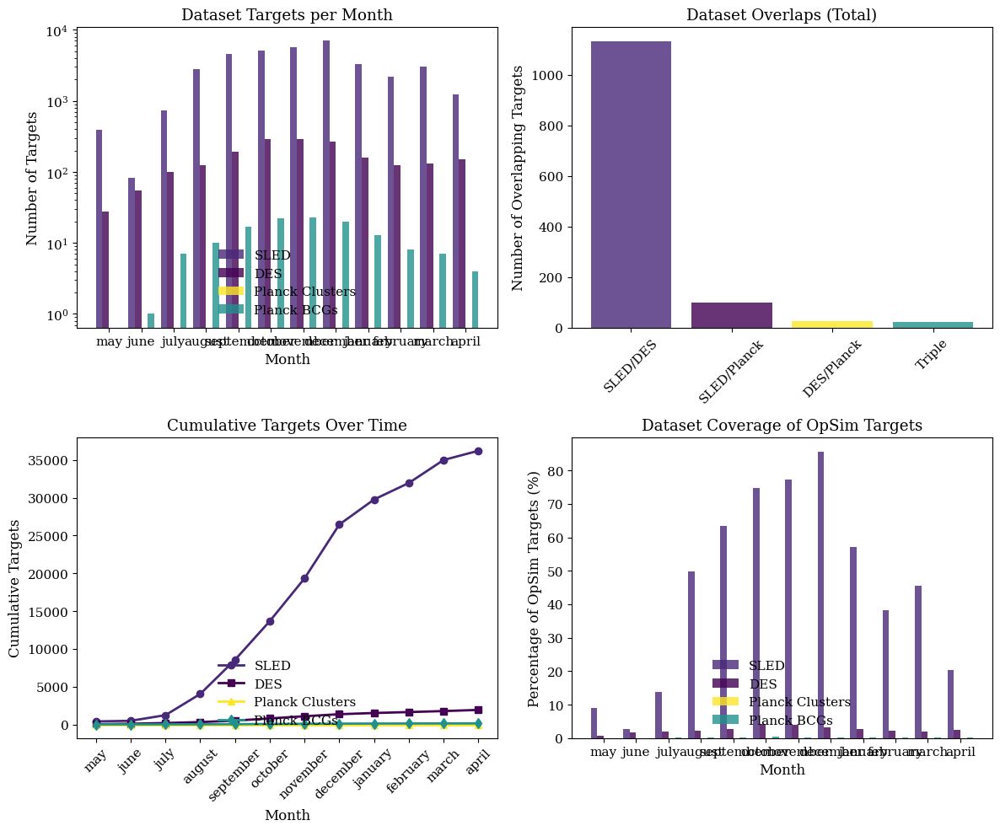

Dataset comparison visualization created

=== DATASET TARGETS COMPARISON COMPLETE ===


In [37]:
def compare_dataset_targets_in_opsim_visits(monthly_exposures_data, opsim_months=['may', 'june', 'july', 'august', 'september', 'october', 'november']):
    """
    Compare number of targets from SLED, DES, and Planck SZ2 datasets across OpSim visits
    """
    print("=== COMPARING DATASET TARGETS IN OPSIM VISITS ===")
    
    comparison_results = {
        'month': [],
        'total_visits': [],
        'total_targets_in_visits': [],
        'sled_targets': [],
        'des_matches': [],
        'planck_sz2_cluster_matches': [],
        'planck_sz2_bcg_matches': [],
        'overlap_sled_des': [],
        'overlap_sled_planck': [],
        'overlap_des_planck': [],
        'triple_overlap': []
    }
    
    print("Loading datasets...")
    
    sled_data = load_important_clusters_csv_fixed('/data/a.saricaoglu/repo/RubinsForge/in_LSST_footprint_coordinates.fits')
    sled_targets_total = len(sled_data) if sled_data is not None else 0
    print(f"SLED dataset: {sled_targets_total} targets")
    
    des_data = load_important_clusters_csv('/data/a.saricaoglu/repo/RubinsForge/Skyfield/DES_bright_arcs_survey.csv')
    des_targets_total = len(des_data) if des_data is not None else 0
    print(f"DES dataset: {des_targets_total} targets")
    
    planck_data = load_important_clusters_csv('/data/a.saricaoglu/repo/RubinsForge/Skyfield/planck-z2s_brightest_galaxies.csv')
    planck_targets_total = len(planck_data) if planck_data is not None else 0
    print(f"Planck SZ2 dataset: {planck_targets_total} targets")
    
    months_to_process = ['may', 'june', 'july', 'august', 'september', 'october', 'november', 'december', 'january', 'february', 'march', 'april']
    
    for month in months_to_process:
        print(f"\nProcessing month: {month}")
        year = '2025' if month in ['may', 'june', 'july', 'august', 'september', 'october', 'november', 'december'] else '2026'
        opsim_path = f'/data/a.saricaoglu/repo/RubinsForge/OpSim/scripts/twilight_visits_{month}{year}.fits'
        
        try:
            with fits.open(opsim_path) as hdul:
                opsim_data = hdul[1].data
                print(f"  Loaded {len(opsim_data)} OpSim visits")
                
                unique_visits = np.unique(opsim_data['visit_id'])
                unique_targets = np.unique(opsim_data['target_id'])
                
                print(f"  Unique visits: {len(unique_visits)}")
                print(f"  Unique targets in visits: {len(unique_targets)}")
                
                target_coords_dict = {}
                for record in opsim_data:
                    target_id = record['target_id']
                    if isinstance(target_id, (bytes, bytearray)):
                        target_id = target_id.decode(errors='ignore').strip()
                    else:
                        target_id = str(target_id).strip()
                    target_coords_dict[target_id] = {
                        'ra': float(record['target_ra']),
                        'dec': float(record['target_dec'])
                    }
                
                opsim_coords = []
                opsim_target_ids = []
                for target_id, coords in target_coords_dict.items():
                    ra_val = coords['ra']
                    dec_val = coords['dec']
                    if not (np.isfinite(ra_val) and np.isfinite(dec_val)):
                        continue
                    opsim_coords.append(SkyCoord(ra=ra_val * u.deg, dec=dec_val * u.deg, frame='icrs'))
                    opsim_target_ids.append(target_id)
                
                if len(opsim_coords) == 0:
                    print("  No valid OpSim coordinates for this month; skipping")
                    continue
                
                opsim_skycoords = SkyCoord(opsim_coords)
                print(f"  Created coordinates for {len(opsim_skycoords)} unique targets")
                
                tolerance = 1.0 * u.arcsec
                
                # SLED matches
                sled_matches = 0
                sled_matched_targets = set()
                if sled_data is not None and len(sled_data) > 0:
                    sled_coords = []
                    for i in range(len(sled_data)):
                        ra_val = float(sled_data['RA'].iloc[i])
                        dec_val = float(sled_data['DEC'].iloc[i])
                        if np.isfinite(ra_val) and np.isfinite(dec_val):
                            sled_coords.append(SkyCoord(ra=ra_val * u.deg, dec=dec_val * u.deg, frame='icrs'))
                    
                    if len(sled_coords) > 0:
                        sled_skycoords = SkyCoord(sled_coords)
                        # IMPORTANT: search_around_sky returns indices as (self_idx, other_idx, ...).
                        idx_sled, idx_opsim, d2d, d3d = sled_skycoords.search_around_sky(opsim_skycoords, tolerance)
                        valid_opsim_idx = [int(i) for i in idx_opsim if 0 <= int(i) < len(opsim_target_ids)]
                        sled_matches = len(valid_opsim_idx)
                        sled_matched_targets = set(opsim_target_ids[i] for i in valid_opsim_idx)
                
                print(f"  SLED matches: {sled_matches}")
                
                # DES matches
                des_matches = 0
                des_matched_targets = set()
                if des_data is not None and len(des_data) > 0:
                    des_coords = []
                    for cluster in des_data:
                        ra_val = float(cluster['RAdeg'])
                        dec_val = float(cluster['DEdeg'])
                        if np.isfinite(ra_val) and np.isfinite(dec_val):
                            des_coords.append(SkyCoord(ra=ra_val * u.deg, dec=dec_val * u.deg, frame='icrs'))
                    
                    if len(des_coords) > 0:
                        des_skycoords = SkyCoord(des_coords)
                        idx_des, idx_opsim, d2d, d3d = des_skycoords.search_around_sky(opsim_skycoords, tolerance)
                        valid_opsim_idx = [int(i) for i in idx_opsim if 0 <= int(i) < len(opsim_target_ids)]
                        des_matches = len(valid_opsim_idx)
                        des_matched_targets = set(opsim_target_ids[i] for i in valid_opsim_idx)
                
                print(f"  DES matches: {des_matches}")
                
                # Planck SZ2 matches
                planck_cluster_matches = 0
                planck_bcg_matches = 0
                planck_cluster_matched_targets = set()
                planck_bcg_matched_targets = set()
                
                if planck_data is not None and len(planck_data) > 0:
                    cluster_coords = []
                    bcg_coords = []
                    
                    for cluster in planck_data:
                        ra_c = float(cluster['RAJ2000'])
                        dec_c = float(cluster['DEJ2000'])
                        if np.isfinite(ra_c) and np.isfinite(dec_c):
                            cluster_coords.append(SkyCoord(ra=ra_c * u.deg, dec=dec_c * u.deg, frame='icrs'))
                        
                        if 'RA1deg' in cluster and 'DE1deg' in cluster:
                            ra_b = float(cluster['RA1deg'])
                            dec_b = float(cluster['DE1deg'])
                            if np.isfinite(ra_b) and np.isfinite(dec_b):
                                bcg_coords.append(SkyCoord(ra=ra_b * u.deg, dec=dec_b * u.deg, frame='icrs'))
                    
                    if len(cluster_coords) > 0:
                        cluster_skycoords = SkyCoord(cluster_coords)
                        idx_cluster, idx_opsim, d2d, d3d = cluster_skycoords.search_around_sky(opsim_skycoords, tolerance)
                        valid_opsim_idx = [int(i) for i in idx_opsim if 0 <= int(i) < len(opsim_target_ids)]
                        planck_cluster_matches = len(valid_opsim_idx)
                        planck_cluster_matched_targets = set(opsim_target_ids[i] for i in valid_opsim_idx)
                    
                    if len(bcg_coords) > 0:
                        bcg_skycoords = SkyCoord(bcg_coords)
                        idx_bcg, idx_opsim, d2d, d3d = bcg_skycoords.search_around_sky(opsim_skycoords, tolerance)
                        valid_opsim_idx = [int(i) for i in idx_opsim if 0 <= int(i) < len(opsim_target_ids)]
                        planck_bcg_matches = len(valid_opsim_idx)
                        planck_bcg_matched_targets = set(opsim_target_ids[i] for i in valid_opsim_idx)
                
                print(f"  Planck SZ2 cluster matches: {planck_cluster_matches}")
                print(f"  Planck SZ2 BCG matches: {planck_bcg_matches}")
                
                planck_union = planck_cluster_matched_targets.union(planck_bcg_matched_targets)
                overlap_sled_des = len(sled_matched_targets.intersection(des_matched_targets))
                overlap_sled_planck = len(sled_matched_targets.intersection(planck_union))
                overlap_des_planck = len(des_matched_targets.intersection(planck_union))
                triple_overlap = len(sled_matched_targets.intersection(des_matched_targets).intersection(planck_union))
                
                print(f"  Overlaps - SLED/DES: {overlap_sled_des}, SLED/Planck: {overlap_sled_planck}, DES/Planck: {overlap_des_planck}")
                print(f"  Triple overlap: {triple_overlap}")
                
                comparison_results['month'].append(month)
                comparison_results['total_visits'].append(len(unique_visits))
                comparison_results['total_targets_in_visits'].append(len(unique_targets))
                comparison_results['sled_targets'].append(sled_matches)
                comparison_results['des_matches'].append(des_matches)
                comparison_results['planck_sz2_cluster_matches'].append(planck_cluster_matches)
                comparison_results['planck_sz2_bcg_matches'].append(planck_bcg_matches)
                comparison_results['overlap_sled_des'].append(overlap_sled_des)
                comparison_results['overlap_sled_planck'].append(overlap_sled_planck)
                comparison_results['overlap_des_planck'].append(overlap_des_planck)
                comparison_results['triple_overlap'].append(triple_overlap)
                
        except Exception as e:
            print(f"  Error processing {month}: {e}")
            continue
    
    results_df = pd.DataFrame(comparison_results)
    
    print(f"\n=== DATASET COMPARISON SUMMARY ===")
    if len(results_df) > 0:
        print(results_df.to_string(index=False))
    else:
        print("No monthly results produced.")
    
    print(f"\n=== TOTALS ACROSS ALL MONTHS ===")
    print(f"Total visits: {results_df['total_visits'].sum() if 'total_visits' in results_df.columns else 0}")
    print(f"Total targets in visits: {results_df['total_targets_in_visits'].sum() if 'total_targets_in_visits' in results_df.columns else 0}")
    print(f"SLED targets found: {results_df['sled_targets'].sum() if 'sled_targets' in results_df.columns else 0}")
    print(f"DES targets found: {results_df['des_matches'].sum() if 'des_matches' in results_df.columns else 0}")
    print(f"Planck SZ2 cluster centers found: {results_df['planck_sz2_cluster_matches'].sum() if 'planck_sz2_cluster_matches' in results_df.columns else 0}")
    print(f"Planck SZ2 BCGs found: {results_df['planck_sz2_bcg_matches'].sum() if 'planck_sz2_bcg_matches' in results_df.columns else 0}")
    
    return results_df

def plot_dataset_comparison(results_df):
    """
    Create visualization of dataset comparison
    """
    set_plot_style()
    
    fig, axes = plt.subplots(2, 2, figsize=(12, 10))
    
    x_pos = np.arange(len(results_df))
    width = 0.2
    
    axes[0,0].bar(x_pos - width*1.5, results_df['sled_targets'], width, 
                  label='SLED', color=viridis_colors['contaminations'], alpha=0.8)
    axes[0,0].bar(x_pos - width*0.5, results_df['des_matches'], width, 
                  label='DES', color=viridis_colors['trails'], alpha=0.8)
    axes[0,0].bar(x_pos + width*0.5, results_df['planck_sz2_cluster_matches'], width, 
                  label='Planck Clusters', color=viridis_colors['events'], alpha=0.8)
    axes[0,0].bar(x_pos + width*1.5, results_df['planck_sz2_bcg_matches'], width, 
                  label='Planck BCGs', color=viridis_colors['satellites'], alpha=0.8)
    
    axes[0,0].set_xlabel('Month')
    axes[0,0].set_ylabel('Number of Targets')
    axes[0,0].set_title('Dataset Targets per Month')
    axes[0,0].set_xticks(x_pos)
    axes[0,0].set_xticklabels(results_df['month'])
    axes[0,0].legend()
    axes[0,0].set_yscale('log')
    
    overlap_data = {
        'SLED/DES': results_df['overlap_sled_des'].sum(),
        'SLED/Planck': results_df['overlap_sled_planck'].sum(),
        'DES/Planck': results_df['overlap_des_planck'].sum(),
        'Triple': results_df['triple_overlap'].sum()
    }
    
    axes[0,1].bar(overlap_data.keys(), overlap_data.values(), 
                  color=[viridis_colors['contaminations'], viridis_colors['trails'], 
                         viridis_colors['events'], viridis_colors['satellites']], alpha=0.8)
    axes[0,1].set_ylabel('Number of Overlapping Targets')
    axes[0,1].set_title('Dataset Overlaps (Total)')
    axes[0,1].tick_params(axis='x', rotation=45)
    
    cumulative_sled = np.cumsum(results_df['sled_targets'])
    cumulative_des = np.cumsum(results_df['des_matches'])
    cumulative_planck_cluster = np.cumsum(results_df['planck_sz2_cluster_matches'])
    cumulative_planck_bcg = np.cumsum(results_df['planck_sz2_bcg_matches'])
    
    axes[1,0].plot(results_df['month'], cumulative_sled, 'o-', 
                   label='SLED', color=viridis_colors['contaminations'], linewidth=2)
    axes[1,0].plot(results_df['month'], cumulative_des, 's-', 
                   label='DES', color=viridis_colors['trails'], linewidth=2)
    axes[1,0].plot(results_df['month'], cumulative_planck_cluster, '^-', 
                   label='Planck Clusters', color=viridis_colors['events'], linewidth=2)
    axes[1,0].plot(results_df['month'], cumulative_planck_bcg, 'd-', 
                   label='Planck BCGs', color=viridis_colors['satellites'], linewidth=2)
    
    axes[1,0].set_xlabel('Month')
    axes[1,0].set_ylabel('Cumulative Targets')
    axes[1,0].set_title('Cumulative Targets Over Time')
    axes[1,0].legend()
    axes[1,0].tick_params(axis='x', rotation=45)
    
    total_targets = results_df['total_targets_in_visits']
    sled_percent = (results_df['sled_targets'] / total_targets * 100).fillna(0)
    des_percent = (results_df['des_matches'] / total_targets * 100).fillna(0)
    planck_cluster_percent = (results_df['planck_sz2_cluster_matches'] / total_targets * 100).fillna(0)
    planck_bcg_percent = (results_df['planck_sz2_bcg_matches'] / total_targets * 100).fillna(0)
    
    axes[1,1].bar(x_pos - width*1.5, sled_percent, width, 
                  label='SLED', color=viridis_colors['contaminations'], alpha=0.8)
    axes[1,1].bar(x_pos - width*0.5, des_percent, width, 
                  label='DES', color=viridis_colors['trails'], alpha=0.8)
    axes[1,1].bar(x_pos + width*0.5, planck_cluster_percent, width, 
                  label='Planck Clusters', color=viridis_colors['events'], alpha=0.8)
    axes[1,1].bar(x_pos + width*1.5, planck_bcg_percent, width, 
                  label='Planck BCGs', color=viridis_colors['satellites'], alpha=0.8)
    
    axes[1,1].set_xlabel('Month')
    axes[1,1].set_ylabel('Percentage of OpSim Targets (%)')
    axes[1,1].set_title('Dataset Coverage of OpSim Targets')
    axes[1,1].set_xticks(x_pos)
    axes[1,1].set_xticklabels(results_df['month'])
    axes[1,1].legend()
    
    plt.tight_layout()
    plt.savefig(os.path.join(pathToPlots, 'dataset_targets_comparison.png'), dpi=300, bbox_inches='tight')
    plt.show()
    
    return fig

print("Starting dataset targets comparison...")
results_df = compare_dataset_targets_in_opsim_visits(monthly_exposures_data)

try:
    comparison_csv_path = os.path.join(pathToFiles, 'dataset_targets_comparison.csv')
    results_df.to_csv(comparison_csv_path, index=False)
    print(f"\nComparison results saved to: {comparison_csv_path}")
except Exception as e:
    print(f"Error saving comparison results: {e}")

if len(results_df) > 0:
    fig = plot_dataset_comparison(results_df)
    print("Dataset comparison visualization created")

print("\n=== DATASET TARGETS COMPARISON COMPLETE ===")

## DESI vs SLED
A New Way to Discover Strong Gravitational Lenses: Pair-wise Spectroscopic Search from DESI DR1
'...We report the discovery of 318 of these “dimple-lens” candidates. We suspect that these represent dwarf galaxy lensing. 
https://arxiv.org/pdf/2509.16033v1
DESI_DR1.mrt

In [ ]:
from astropy.io import ascii
def load_important_clusters_csv_fixed(csv_path):
    """
    Load and validate the important clusters CSV file with endianness fix
    """
    print(f"Loading important clusters from: {csv_path}")

    try:
        if csv_path.endswith('.fits') or csv_path.endswith('.fit'):
            with fits.open(csv_path) as hdu_list:
                hdu_list.info()
                print(f"Data is a FITS BinTableHDU with columns: {hdu_list[1].columns.names}")
                data = hdu_list[2].data if len(hdu_list) > 2 and hdu_list[2].data is not None else hdu_list[1].data
                print(f"Extracted {len(data)} lens records from FITS data")
                
                # FIXED: Convert to DataFrame and fix endianness
                df = pd.DataFrame(data) if len(data) > 0 else pd.DataFrame()
                
                # Convert numeric columns to native byte order
                for col in df.select_dtypes(include=[np.number]).columns:
                    df[col] = df[col].astype(df[col].dtype.newbyteorder('='))
                
                return df
            
        if csv_path.endswith('.mrt'):
            df = ascii.read(csv_path, format='mrt')
            print(f"Data is a mrt with columns: {df.colnames}")

            # Convert to DataFrame and fix endianness
            df = df.to_pandas()

            return df


        df = pd.read_csv(csv_path)
        data = df.to_dict(orient='records')

        print(f"Successfully loaded CSV data")
        print(f"Data type: {type(data)}")
        
        return data
        
    except Exception as e:
        print(f"Error loading file: {e}")
        return None

def match_important_clusters_with_name_validation(sled_data, desi_data, tolerance_arcsec=1.0):
    """
    Match FOV contaminated targets with important clusters based on RA/Dec coordinates
    and validate with name matching
    """
    print(f"=== MATCHING TARGETS WITH IMPORTANT CLUSTERS (WITH NAME VALIDATION) ===")
    print(f"DESI targets: {len(desi_data)}")
    print(f"SLED targets: {len(sled_data)}")
    print(f"Matching tolerance: {tolerance_arcsec} arcsec")
    
    # Convert to native byte order to avoid endianness issues
    desi_df = desi_data.copy()
    sled_df = sled_data.copy()
    
    # Convert all numeric columns to native byte order
    for col in sled_df.select_dtypes(include=[np.number]).columns:
        sled_df[col] = sled_df[col].astype(sled_df[col].dtype.newbyteorder('='))
    
    print(f"Targets in DESI: {len(desi_df)}")
    print(f"Targets in SLED: {len(sled_df)}")

    # Create coordinate objects for SLED targets
    sled_coords = []
    for i in range(len(sled_df)):
        ra_t = float(sled_df['RA'].iloc[i])
        dec_t = float(sled_df['DEC'].iloc[i])
        sled_coords.append(SkyCoord(
            ra=ra_t * u.deg,
            dec=dec_t * u.deg,
            frame='icrs'
        ))
    sled_coords = SkyCoord(sled_coords)
    
    # Create coordinate objects for DESI targets
    desi_coords = []
    for i in range(len(desi_df)):
        ra_d = float(desi_df['RAdeg'].iloc[i])
        dec_d = float(desi_df['DEdeg'].iloc[i])
        desi_coords.append(SkyCoord(
            ra=ra_d * u.deg,
            dec=dec_d * u.deg,
            frame='icrs'
        ))
    desi_coords = SkyCoord(desi_coords)
    
    print(f"Created coordinate objects for matching")
    
    # Use the SLED DataFrame as base
    matched_df_desi = sled_df.copy()
    
    # Initialize columns properly
    matched_df_desi['desi_ra_deg'] = None
    matched_df_desi['desi_dec_deg'] = None
    matched_df_desi['desi_match_separation_arcsec'] = np.nan
    matched_df_desi['DESIName'] = None
    matched_df_desi['desi_id'] = None
    
    matched_df_desi['name_match'] = False
    matched_df_desi['match_type'] = None
    
    # Helper function to check if names match
    def names_match(sled_name, desi_name):
        """Check if SLED and DESI names correspond"""
        if not sled_name or not desi_name:
            return False
        
        # Remove spaces and convert to upper case for comparison
        sled_clean = sled_name.replace(' ', '').upper()
        desi_clean = desi_name.replace(' ', '').upper()
        
        # Check if DESI name is "DESI" + SLED name
        if desi_clean == f"DESI{sled_clean}":
            return True
        
        # Also check without the "J" prefix if SLED name starts with "J"
        if sled_clean.startswith('J'):
            sled_without_j = sled_clean[1:]
            if desi_clean == f"DESI{sled_without_j}" or desi_clean == f"DESIJ{sled_without_j}":
                return True
        
        return False
    
    # Perform coordinate matching for clusters
    print(f'Size of sled coords: {len(sled_coords)}, size of desi coords: {len(desi_coords)}')
    tolerance = tolerance_arcsec * u.arcsec
    idx_sled, idx_desi, d2d_cluster, d3d_cluster = sled_coords.search_around_sky(desi_coords, tolerance)
    print(f"Found {len(idx_desi)} coordinate matches within {tolerance_arcsec} arcsec tolerance")

    # Track matching statistics
    coordinate_matches = 0
    name_matches = 0
    both_matches = 0
    coordinate_only = 0
    name_mismatch = 0

    if len(idx_desi) > 0:    
        # Fill in the matched data using correct indices
        for i, (sled_idx, desi_idx) in enumerate(zip(idx_sled, idx_desi)):
            separation_arcsec = d2d_cluster[i].to(u.arcsec).value

            # Get cluster data using iloc to access rows by position
            desi_name = desi_df.iloc[sled_idx]['Name'] if 'Name' in desi_df.columns else ''
            sled_name = sled_df.iloc[desi_idx]['SLEDName'] if 'SLEDName' in sled_df.columns else ''

            # Check if names match
            name_match = names_match(sled_name, desi_name)

            # Fill in basic matching info using iloc for position-based indexing
            matched_df_desi.iloc[desi_idx, matched_df_desi.columns.get_loc('desi_match_separation_arcsec')] = separation_arcsec
            matched_df_desi.iloc[desi_idx, matched_df_desi.columns.get_loc('DESIName')] = desi_name
            matched_df_desi.iloc[desi_idx, matched_df_desi.columns.get_loc('name_match')] = name_match
            matched_df_desi.iloc[desi_idx, matched_df_desi.columns.get_loc('desi_ra_deg')] = desi_df.iloc[sled_idx]['RAdeg']
            matched_df_desi.iloc[desi_idx, matched_df_desi.columns.get_loc('desi_dec_deg')] = desi_df.iloc[sled_idx]['DEdeg']
            
            # Categorize match type
            if name_match:
                matched_df_desi.iloc[desi_idx, matched_df_desi.columns.get_loc('match_type')] = 'coordinate_and_name'
                both_matches += 1
            else:
                matched_df_desi.iloc[desi_idx, matched_df_desi.columns.get_loc('match_type')] = 'coordinate_only'
                coordinate_only += 1
                print(f"  WARNING: Coordinate match but name mismatch - SLED: '{sled_name}' vs DESI: '{desi_name}' (sep: {separation_arcsec:.3f}\")")

            coordinate_matches += 1
            if name_match:
                name_matches += 1
            else:
                name_mismatch += 1

        print(f"\nMatching Results:")
        print(f"  Total coordinate matches: {coordinate_matches}")
        print(f"  Matches with name validation: {both_matches}")
        print(f"  Coordinate-only matches (name mismatch): {coordinate_only}")
        print(f"  Name match rate: {(name_matches/coordinate_matches*100) if coordinate_matches > 0 else 0:.1f}%")
        
        if coordinate_matches > 0:
            # Statistics for all matches
            sep_values = matched_df_desi.loc[matched_df_desi['DESIName'].notna(), 'desi_match_separation_arcsec']
            if len(sep_values) > 0:
                print(f"  Mean separation: {sep_values.mean():.3f} arcsec")
                print(f"  Max separation: {sep_values.max():.3f} arcsec")

            # Statistics for name-validated matches only
            name_validated_mask = (matched_df_desi['DESIName'].notna()) & (matched_df_desi['name_match'] == True)
            if name_validated_mask.sum() > 0:
                validated_sep_values = matched_df_desi.loc[name_validated_mask, 'desi_match_separation_arcsec']
                print(f"  Mean separation (name-validated): {validated_sep_values.mean():.3f} arcsec")
                print(f"  Max separation (name-validated): {validated_sep_values.max():.3f} arcsec")

    return matched_df_desi

def find_name_matches_only(sled_data, important_clusters_data):
    """Find matches based purely on name similarity"""
    print(f"\n=== NAME-ONLY MATCHING ANALYSIS ===")
    
    sled_df = sled_data.copy()
    sled_names = [str(sled_df['SLEDName'].iloc[i]).strip() if 'SLEDName' in sled_df.columns else '' 
                  for i in range(len(sled_df))]
    
    # FIXED: Handle DataFrame instead of list of dictionaries
    if isinstance(important_clusters_data, pd.DataFrame):
        cluster_names = [str(important_clusters_data['Name'].iloc[i]).strip() if 'Name' in important_clusters_data.columns else '' 
                         for i in range(len(important_clusters_data))]
    else:
        # Fallback for list of dictionaries
        cluster_names = [cluster.get('Name', '').strip() if cluster.get('Name') else '' 
                         for cluster in important_clusters_data]
    
    def names_match(sled_name, desi_name):
        if not sled_name or not desi_name:
            return False
        sled_clean = sled_name.replace(' ', '').upper()
        desi_clean = desi_name.replace(' ', '').upper()
        return (desi_clean == f"DESI{sled_clean}" or 
                (sled_clean.startswith('J') and desi_clean == f"DESIJ{sled_clean[1:]}"))
    
    name_matches = []
    for i, sled_name in enumerate(sled_names):
        for j, desi_name in enumerate(cluster_names):
            if names_match(sled_name, desi_name):
                # FIXED: Handle DataFrame access
                if isinstance(important_clusters_data, pd.DataFrame):
                    desi_id = important_clusters_data.iloc[j]['ID'] if 'ID' in important_clusters_data.columns else f'desi_{j}'
                    desi_ra = important_clusters_data.iloc[j]['RAdeg'] if 'RAdeg' in important_clusters_data.columns else np.nan
                    desi_dec = important_clusters_data.iloc[j]['DEdeg'] if 'DEdeg' in important_clusters_data.columns else np.nan
                else:
                    # Fallback for list of dictionaries
                    desi_id = important_clusters_data[j]['ID']
                    desi_ra = important_clusters_data[j]['RAdeg']
                    desi_dec = important_clusters_data[j]['DEdeg']
                
                name_matches.append({
                    'sled_idx': i,
                    'desi_idx': j,
                    'sled_name': sled_name,
                    'desi_name': desi_name,
                    'desi_id': desi_id,
                    'sled_ra': sled_df['RA'].iloc[i],
                    'sled_dec': sled_df['DEC'].iloc[i],
                    'desi_ra': desi_ra,
                    'desi_dec': desi_dec
                })
    
    print(f"Found {len(name_matches)} pure name matches")
    
    # Calculate separations for name matches
    if name_matches:
        print("Name matches with coordinate separations:")
        for match in name_matches[:10]:  # Show first 10
            if not (np.isnan(match['sled_ra']) or np.isnan(match['sled_dec']) or 
                    np.isnan(match['desi_ra']) or np.isnan(match['desi_dec'])):
                sled_coord = SkyCoord(ra=match['sled_ra']*u.deg, dec=match['sled_dec']*u.deg)
                desi_coord = SkyCoord(ra=match['desi_ra']*u.deg, dec=match['desi_dec']*u.deg)
                sep = sled_coord.separation(desi_coord).to(u.arcsec)
                print(f"  {match['sled_name']} <-> {match['desi_name']}: {sep.value:.3f} arcsec")
    
    return name_matches

# Usage example:
if os.path.exists('/data/a.saricaoglu/repo/RubinsForge/Skyfield/DESI_DR1.mrt'):
    desi_data = load_important_clusters_csv_fixed('/data/a.saricaoglu/repo/RubinsForge/Skyfield/DESI_DR1.mrt')
    sled_data = load_important_clusters_csv_fixed('/data/a.saricaoglu/repo/RubinsForge/in_LSST_footprint_coordinates.fits')

    if desi_data is not None and sled_data is not None and len(sled_data) > 0:
        # Run matching with name validation
        matched_important_df = match_important_clusters_with_name_validation(
            sled_data, desi_data, tolerance_arcsec=1)

        # Run name-only analysis
        name_only_matches = find_name_matches_only(sled_data, desi_data)

        # Save results with additional name validation columns
        desi_matches = matched_important_df['DESIName'].notna()
        n_matches = int(desi_matches.sum())
        
        if n_matches > 0:
            important_matches_path = os.path.join(pathToFiles, 'important_DESI_SLED_matches_with_names.csv')
            important_only = matched_important_df.loc[desi_matches].copy()
            important_only.to_csv(important_matches_path, index=False)
            print(f"Important cluster matches saved to: {important_matches_path}")
            
            # Also save only the name-validated matches
            name_validated = matched_important_df.loc[matched_important_df['name_match'] == True].copy()
            if len(name_validated) > 0:
                validated_path = os.path.join(pathToFiles, 'name_validated_DESI_SLED_matches.csv')
                name_validated.to_csv(validated_path, index=False)
                print(f"Name-validated matches saved to: {validated_path}")
        else:
            print("No matches found with important clusters")

### Contaminated in FOV target matching with DESI

In [ ]:
# --- DESI vs SLED (clean fixed version) ---
from astropy.io import ascii

def load_desi(path):
    if path.endswith('.mrt'):
        t = ascii.read(path, format='mrt')
        df = t.to_pandas()
        return df
    if path.endswith('.fits') or path.endswith('.fit'):
        with fits.open(path) as hdul:
            data = hdul[1].data
            df = pd.DataFrame(data)
        return df
    return pd.read_csv(path)

def match_fov_with_desi(fov_df, desi_df, tolerance_arcsec=1.0):
    print(f"=== DESI MATCHING (FOV targets vs DESI) ===")
    print(f"FOV targets: {len(fov_df)}, DESI objects: {len(desi_df)}")

    # Require RA/Dec columns
    if not {'cont_target_ra_deg','cont_target_dec_deg'}.issubset(fov_df.columns):
        print("Missing cont_target_ra_deg/cont_target_dec_deg in FOV table.")
        return pd.DataFrame()

    # Build SkyCoord arrays
    fov_coords = SkyCoord(fov_df['cont_target_ra_deg'].astype(float).values * u.deg,
                          fov_df['cont_target_dec_deg'].astype(float).values * u.deg)
    desi_coords = SkyCoord(desi_df['RAdeg'].astype(float).values * u.deg,
                           desi_df['DEdeg'].astype(float).values * u.deg)

    tol = tolerance_arcsec * u.arcsec

    # search_around_sky: call on DESI (catalog) around FOV (targets)
    # Returns indices: desi_idx, fov_idx
    desi_idx, fov_idx, sep2d, _ = desi_coords.search_around_sky(fov_coords, tol)
    print(f"Coordinate matches within {tolerance_arcsec} arcsec: {len(desi_idx)}")

    out = fov_df.copy()
    out['DESIName'] = None
    out['desi_id'] = None
    out['desi_ra_deg'] = np.nan
    out['desi_dec_deg'] = np.nan
    out['desi_match_separation_arcsec'] = np.nan

    for i, (d_i, f_i) in enumerate(zip(desi_idx, fov_idx)):
        sep_arcsec = sep2d[i].to(u.arcsec).value
        out.loc[f_i, 'desi_match_separation_arcsec'] = sep_arcsec
        if 'Name' in desi_df.columns:
            out.loc[f_i, 'DESIName'] = desi_df.iloc[d_i]['Name']
        out.loc[f_i, 'desi_id'] = desi_df.iloc[d_i].get('ID', d_i)
        out.loc[f_i, 'desi_ra_deg'] = desi_df.iloc[d_i]['RAdeg']
        out.loc[f_i, 'desi_dec_deg'] = desi_df.iloc[d_i]['DEdeg']

    matched = out[out['DESIName'].notna()]
    n = len(matched)
    if n > 0:
        print("Matching Results:")
        print(f"  Total coordinate matches: {n}")
        print(f"  Mean separation: {matched['desi_match_separation_arcsec'].mean():.3f} arcsec")
        print(f"  Max separation: {matched['desi_match_separation_arcsec'].max():.3f} arcsec")
    else:
        print("No matches found with important clusters")

    return out

# Usage
desi_path = "/data/a.saricaoglu/repo/RubinsForge/Skyfield/DESI_DR1.mrt"
if os.path.exists(desi_path) and 'fov_targets_df' in locals() and len(fov_targets_df) > 0:
    desi_df = load_desi(desi_path)
    desi_matched_df = match_fov_with_desi(fov_targets_df, desi_df, tolerance_arcsec=1.0)

    if 'desi_matched_df' in locals() and len(desi_matched_df[desi_matched_df['DESIName'].notna()]) > 0:
        save_path = os.path.join(pathToFiles, "DESI_matches_with_names.csv")
        desi_matched_df[desi_matched_df['DESIName'].notna()].to_csv(save_path, index=False)
        print(f"Saved: {save_path}")

## Time delay cosmo lenses
5 targets match, none of them in fov

In [ ]:
import json

# Load time-delay lenses
time_delay_lenses_path = "/grad/a.saricaoglu/Downloads/time_delay_lenses.json"

print(f"Loading time-delay lenses from: {time_delay_lenses_path}")
try:
    with open(time_delay_lenses_path, 'r') as f:
        tdl_data = json.load(f)
    
    # Convert to DataFrame if it's a list of objects
    if isinstance(tdl_data, list):
        tdl_df = pd.DataFrame(tdl_data)
    else:
        tdl_df = pd.DataFrame([tdl_data])
    
    print(f"Successfully loaded {len(tdl_df)} time-delay lens records")
    print(f"Columns: {list(tdl_df.columns)}")
    print(f"\nFirst few records:\n{tdl_df.head()}")
except Exception as e:
    print(f"Error loading time-delay lenses: {e}")
    tdl_df = None


# Verify FOV targets dataset
print(f"FOV targets in-field dataset shape: {fov_targets_df.shape}")
print(f"FOV targets columns: {list(fov_targets_df.columns)}")
print(f"\nFirst few FOV targets:\n{fov_targets_df[['cont_target_id', 'cont_target_ra_deg', 'cont_target_dec_deg']].head()}")

if tdl_df is not None:
    print(f"\nTime-delay lenses shape: {tdl_df.shape}")
    print(f"Time-delay lenses columns: {list(tdl_df.columns)}")
    print(f"\nFirst few time-delay lenses:\n{tdl_df.head()}")

# Match time-delay lenses with in-FOV targets
def match_time_delay_lenses_with_fov_targets(tdl_df, fov_df, tolerance_arcsec=1.0):
    """
    Match time-delay lenses with in-FOV targets based on RA/Dec coordinates
    """
    print(f"=== MATCHING TIME-DELAY LENSES WITH FOV TARGETS ===")
    print(f"Time-delay lenses: {len(tdl_df)}")
    print(f"FOV targets: {len(fov_df)}")
    print(f"Matching tolerance: {tolerance_arcsec} arcsec\n")
    
    # Identify RA/Dec columns in both datasets
    tdl_ra_col = None
    tdl_dec_col = None
    fov_ra_col = 'cont_target_ra_deg'
    fov_dec_col = 'cont_target_dec_deg'
    
    # Try to find RA/Dec columns in time-delay lenses
    for col in tdl_df.columns:
        if col.lower() in ['ra', 'ra_deg', 'right_ascension']:
            tdl_ra_col = col
        elif col.lower() in ['dec', 'dec_deg', 'declination']:
            tdl_dec_col = col
    
    if tdl_ra_col is None or tdl_dec_col is None:
        print("Warning: Could not identify RA/Dec columns in time-delay lenses")
        print(f"Available columns: {list(tdl_df.columns)}")
        return None
    
    print(f"Using columns - TDL RA: {tdl_ra_col}, TDL Dec: {tdl_dec_col}")
    print(f"Using columns - FOV RA: {fov_ra_col}, FOV Dec: {fov_dec_col}\n")
    
    # Create coordinate objects for time-delay lenses
    tdl_coords = []
    for idx, row in tdl_df.iterrows():
        try:
            ra = float(row[tdl_ra_col])
            dec = float(row[tdl_dec_col])
            tdl_coords.append(SkyCoord(ra=ra*u.deg, dec=dec*u.deg, frame='icrs'))
        except (ValueError, TypeError) as e:
            print(f"Skipping TDL record {idx}: {e}")
            continue
    
    tdl_coords = SkyCoord(tdl_coords)
    print(f"Created {len(tdl_coords)} valid TDL coordinates")
    
    # Create coordinate objects for FOV targets
    fov_coords = []
    for idx, row in fov_df.iterrows():
        try:
            ra = float(row[fov_ra_col])
            dec = float(row[fov_dec_col])
            fov_coords.append(SkyCoord(ra=ra*u.deg, dec=dec*u.deg, frame='icrs'))
        except (ValueError, TypeError) as e:
            print(f"Skipping FOV record {idx}: {e}")
            continue
    
    fov_coords = SkyCoord(fov_coords)
    print(f"Created {len(fov_coords)} valid FOV coordinates\n")
    
    # Search for matches
    tolerance = tolerance_arcsec * u.arcsec
    idx_fov, idx_tdl, d2d, d3d = fov_coords.search_around_sky(tdl_coords, tolerance)
    
    print(f"Found {len(idx_tdl)} matches within {tolerance_arcsec} arcsec\n")
    
    # Create result DataFrame
    if len(idx_tdl) > 0:
        matches_list = []
        for fov_idx, tdl_idx, separation in zip(idx_fov, idx_tdl, d2d):
            fov_target = fov_df.iloc[fov_idx]
            tdl_target = tdl_df.iloc[tdl_idx]
            
            match_dict = {
                'fov_target_id': fov_target.get('cont_target_id', f'target_{fov_idx}'),
                'fov_ra': float(fov_target[fov_ra_col]),
                'fov_dec': float(fov_target[fov_dec_col]),
                'tdl_name': tdl_target.get('name', tdl_target.get('source_name', f'source_{tdl_idx}')),
                'tdl_ra': float(tdl_target[tdl_ra_col]),
                'tdl_dec': float(tdl_target[tdl_dec_col]),
                'separation_arcsec': separation.to(u.arcsec).value,
            }
            matches_list.append(match_dict)
        
        matches_df = pd.DataFrame(matches_list)
        matches_df = matches_df.sort_values('separation_arcsec')
        
        print("=== MATCHES FOUND ===")
        print(matches_df.to_string(index=False))
        print(f"\nMatch statistics:")
        print(f"  Mean separation: {matches_df['separation_arcsec'].mean():.3f} arcsec")
        print(f"  Median separation: {matches_df['separation_arcsec'].median():.3f} arcsec")
        print(f"  Max separation: {matches_df['separation_arcsec'].max():.3f} arcsec")
        
        return matches_df
    else:
        print("No matches found!")
        return pd.DataFrame()

# Run the matching
if tdl_df is not None and fov_targets_df is not None and len(fov_targets_df) > 0:
    time_delay_matches = match_time_delay_lenses_with_fov_targets(
        tdl_df, fov_summary_df, tolerance_arcsec=1.0
    )
    
    # Save results if matches found
    if len(time_delay_matches) > 0:
        tdl_matches_path = os.path.join(pathToFiles, 'time_delay_lenses_FOV_matches.csv')
        time_delay_matches.to_csv(tdl_matches_path, index=False)
        print(f"\nMatches saved to: {tdl_matches_path}")
else:
    print("Cannot run matching: missing data")



In [ ]:
# Normalize both ID columns to the same format
matched_ids = matched_tdc_df['Target_no'].astype(str)
fov_ids = fov_targets_df['cont_target_id'].astype(str)

# If your IDs look like "abc_123", keep only the numeric/last part
matched_ids = matched_ids.str.split('_').str[-1]
fov_ids = fov_ids.str.split('_').str[-1]

# IDs present in both tables
targets_in_fov = sorted(set(matched_ids) & set(fov_ids))

print(f"Number of matched important targets in FOV: {len(targets_in_fov)}")
print(targets_in_fov)
matched_in_fov_df = matched_tdc_df[
    matched_tdc_df['Target_no'].astype(str).str.split('_').str[-1].isin(fov_ids)
]

print(matched_in_fov_df)
matched_in_fov_df = matched_tdc_df[
    matched_tdc_df['Target_no'].astype(str).str.split('_').str[-1].isin(fov_ids)
]

print(matched_in_fov_df)

In [ ]:
def great_circle_altaz_boundary(alt0_deg, az0_deg, radius_deg, n=240):
    """Return az, alt arrays for the locus of points at angular distance radius_deg
    from (alt0_deg, az0_deg) on the sphere (great circle distance)."""
    a0 = np.deg2rad(alt0_deg)
    A0 = np.deg2rad(az0_deg)
    d = np.deg2rad(radius_deg)
    thetas = np.linspace(0, 2*np.pi, n)

    sin_a = np.sin(a0)*np.cos(d) + np.cos(a0)*np.sin(d)*np.cos(thetas)
    a = np.arcsin(sin_a)

    delta_A = np.arctan2(np.sin(thetas)*np.sin(d)*np.cos(a0),
                         np.cos(d) - np.sin(a0)*np.sin(a))

    A = A0 + delta_A
    alt_boundary = np.rad2deg(a)
    az_boundary = (np.rad2deg(A) + 360.0) % 360.0
    return az_boundary, alt_boundary

def plot_visit_fov_and_targets_altaz(exp_data, targets, fov_radius_deg=1.75):
    """
    Plot visit field of view and targets on Alt/Az Cartesian coordinates.
    """
    fig, ax = plt.subplots(figsize=(3.5, 7))

    if 'SATELLITE_DATA' not in exp_data:
        print("No SATELLITE_DATA found in exposure")
        return None, None

    if 'VISIT_INFO' not in exp_data:
        print("No VISIT_INFO found in exposure")
        return None, None

    sat_header = exp_data['SATELLITE_DATA']['header']
    visit_data = exp_data['VISIT_INFO']['data']

    if visit_data is None or len(visit_data) == 0:
        print("No visit data available")
        return None, None

    obs_time = Time(datetime.fromisoformat(sat_header['EXPSTART']))
    rubin_location = EarthLocation.of_site('rubin')
    altaz_frame = AltAz(obstime=obs_time, location=rubin_location)

    field_coord = SkyCoord(ra=visit_data['FIELD_RA'][0]*u.deg,
                           dec=visit_data['FIELD_DEC'][0]*u.deg, frame='icrs')
    field_altaz = field_coord.transform_to(altaz_frame)

    field_alt = field_altaz.alt.deg
    field_az = field_altaz.az.deg

    if field_alt < 30:
        print(f"WARNING: Field altitude ({field_alt:.1f}°) is below LSST minimum (30°)!")

    if targets is not None and len(targets) > 0:
        ti = ts.from_datetime(datetime.fromisoformat(sat_header['EXPSTART']))

        target_coords = []
        for target_star in targets:
            astrometric = rubinobs_astr.at(ti).observe(target_star)
            apparent = astrometric.apparent()
            alt, az, distance = apparent.altaz()

            if alt.degrees > 0:
                coord = SkyCoord(ra=target_star.ra._degrees*u.deg,
                                 dec=target_star.dec.degrees*u.deg, frame='icrs')
                target_coords.append(coord)

        if target_coords:
            target_coords = SkyCoord(target_coords)
            target_altaz = target_coords.transform_to(altaz_frame)

            margin = fov_radius_deg * 3
            separations_deg = field_altaz.separation(target_altaz).deg
            visible = target_altaz.alt.deg > 30
            nearby_mask = (separations_deg <= margin) & visible
            fov_mask = (separations_deg <= fov_radius_deg) & visible

            if np.any(nearby_mask):
                ax.scatter(target_altaz.az.deg[nearby_mask],
                           target_altaz.alt.deg[nearby_mask],
                           c='black', s=30, alpha=0.6, marker='*')

            if np.any(fov_mask):
                ax.scatter(target_altaz.az.deg[fov_mask],
                           target_altaz.alt.deg[fov_mask],
                           c='green', s=30, alpha=0.6, marker='*',
                           label=f'Targets ({np.sum(fov_mask)})')

    if 'CONTAMINATED_TARGETS' in exp_data:
        cont_data = exp_data['CONTAMINATED_TARGETS']['data']
        if cont_data is not None and len(cont_data) > 0:
            if 'Target_Alt' in cont_data.dtype.names and 'Target_Az' in cont_data.dtype.names:
                cont_altitudes = cont_data['Target_Alt']
                cont_azimuths = cont_data['Target_Az']

                unique_targets = np.unique(cont_data['Target_Name'])
                colors = plt.cm.Set1(np.linspace(0, 1, len(unique_targets)))

                for i, target_name in enumerate(unique_targets):
                    target_indices = np.where(cont_data['Target_Name'] == target_name)[0]
                    if len(target_indices) > 0:
                        target_name_str = target_name.split()[1].split('_')[1]
                        ax.scatter(cont_azimuths[target_indices], cont_altitudes[target_indices],
                                   c=[colors[i]], s=100, marker='X', edgecolors='black',
                                   alpha=0.9, label=f'Cont. ID: {target_name_str}', zorder=4)

    sat_data = exp_data['SATELLITE_DATA']['data']
    if sat_data is not None and len(sat_data) > 0:
        sat_altitudes = sat_data['Altitude']
        sat_azimuths = sat_data['Azimuth']

        if 'AB_Magnitude' in sat_data.dtype.names:
            ab_magnitudes = sat_data['AB_Magnitude']
            sc = ax.scatter(sat_azimuths, sat_altitudes, c=ab_magnitudes,
                            cmap='plasma', s=40, alpha=0.7, label='Satellite Path')
            plt.colorbar(sc, ax=ax, label=r'M$_{AB}$ [mag]', shrink=0.8, orientation='horizontal', pad=0.1)
        else:
            ax.scatter(sat_azimuths, sat_altitudes, c='red', s=40, alpha=0.7,
                       label='Satellite Path')

    az_b, alt_b = great_circle_altaz_boundary(field_alt, field_az, fov_radius_deg)
    ax.plot(az_b, alt_b, color='blue', linewidth=2,
            label=f'LSST FOV ({fov_radius_deg*2:.1f}°)')

    ax.set_xlabel('Azimuth [deg]')
    ax.set_ylabel('Altitude [deg]')

    visit_id = visit_data['VISIT_ID'][0] if 'VISIT_ID' in visit_data.dtype.names else 'Unknown'
    filter_name = visit_data['FILTER'][0] if 'FILTER' in visit_data.dtype.names else 'Unknown'
    if isinstance(filter_name, bytes):
        filter_name = filter_name.decode()

    ti = ts.from_datetime(datetime.fromisoformat(sat_header['EXPSTART']))
    title = f'Visit {visit_id} - {ti.astimezone(zone)} UTC ({filter_name}-band)'

    ax.legend(bbox_to_anchor=(0.4, 1.01), loc='lower center',
              ncol=2, fontsize=9, columnspacing=0.1)

    margin = fov_radius_deg * 4
    ax.set_xlim(field_az - margin, field_az + margin)
    ax.set_ylim(max(0, field_alt - margin), min(90, field_alt + margin))

    ax.axhline(y=0, color='brown', linestyle='--', alpha=0.5, label='Horizon')
    ax.set_aspect('equal')
    plt.tight_layout()

    print(f"Field center: RA={visit_data['FIELD_RA'][0]:.3f}°, Dec={visit_data['FIELD_DEC'][0]:.3f}°")
    print(f"Field alt/az: Alt={field_alt:.3f}°, Az={field_az:.3f}°")
    print(title)
    return fig, ax

def plot_contaminated_exposures_from_fov_df(monthly_exposures_data, fov_contamination_df, targets):
    """
    Plot only exposures listed in fov_contamination_df (faster than scanning all monthly exposures).
    Expected columns in fov_contamination_df: month, day, exposure_id
    """
    required = {'month', 'day', 'visit_id'}
    missing = required - set(fov_contamination_df.columns)
    if missing:
        print(f"Missing required columns in fov_contamination_df: {missing}")
        return

    exposure_rows = fov_contamination_df[list(required)].dropna().drop_duplicates()
    print(f"Total unique contaminated exposures to plot: {len(exposure_rows)}")

    for _, row in exposure_rows.iterrows():
        month = str(row['month']).lower()
        day = str(row['day'])
        exp_id = row['visit_id']
        try:
            exp_id = int(exp_id)
        except Exception:
            pass

        if month not in monthly_exposures_data:
            print(f"Month not found in monthly_exposures_data: {month}")
            continue
        if day not in monthly_exposures_data[month]:
            print(f"Day not found: {month}/{day}")
            continue
        if exp_id not in monthly_exposures_data[month][day]:
            print(f"Exposure not found: {month}/{day}/{exp_id}")
            continue

        exp_data = monthly_exposures_data[month][day][exp_id]
        print(f"Plotting {month} / {day} / exposure {exp_id}")
        fig, ax = plot_visit_fov_and_targets_altaz(exp_data, targets)

        if fig is not None:
            save_dir = '/data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures'
            os.makedirs(save_dir, exist_ok=True)
            save_path = f"{save_dir}/{month}_exposure_{exp_id}_fov_targets.png"
            fig.savefig(save_path, dpi=300)
            plt.show()
            plt.close(fig)
        else:
            print("Failed to create plot")

# Use fov_contamination_df if available, otherwise fallback to fov_targets_df
fov_df_source = None
if 'fov_contamination_df' in locals() and isinstance(fov_contamination_df, pd.DataFrame) and len(fov_contamination_df) > 0:
    fov_df_source = fov_contamination_df
    print("Using fov_contamination_df for plotting exposure selection")
elif 'fov_targets_df' in locals() and isinstance(fov_targets_df, pd.DataFrame) and len(fov_targets_df) > 0:
    fov_df_source = fov_targets_df
    print("fov_contamination_df not found; using fov_targets_df as fallback")

if fov_df_source is not None:
    plot_contaminated_exposures_from_fov_df(monthly_exposures_data, fov_df_source, targets_)
else:
    print("No fov contamination dataframe found (expected fov_contamination_df or fov_targets_df)")

In [ ]:
# Similar plotting with aitoff projection
def plot_visit_fov_and_targets_aitoff(exp_data, targets, fov_radius_deg=1.75):
    """
    Plot visit field of view and targets on an Aitoff projection (RA/Dec).
    """
    fig = plt.figure(figsize=(8, 5))
    ax = fig.add_subplot(111, projection='aitoff')

    if 'SATELLITE_DATA' not in exp_data:
        print("No SATELLITE_DATA found in exposure")
        return None, None

    if 'VISIT_INFO' not in exp_data:
        print("No VISIT_INFO found in exposure")
        return None, None

    sat_header = exp_data['SATELLITE_DATA']['header']
    visit_data = exp_data['VISIT_INFO']['data']

    if visit_data is None or len(visit_data) == 0:
        print("No visit data available")
        return None, None

    obs_time = Time(datetime.fromisoformat(sat_header['EXPSTART']))
    rubin_location = EarthLocation.of_site('rubin')
    altaz_frame = AltAz(obstime=obs_time, location=rubin_location)

    field_coord = SkyCoord(ra=visit_data['FIELD_RA'][0]*u.deg,
                           dec=visit_data['FIELD_DEC'][0]*u.deg, frame='icrs')
    
    field_altaz = field_coord.transform_to(altaz_frame)
    field_alt = field_altaz.alt.deg
    field_az = field_altaz.az.deg

    if targets is not None and len(targets) > 0:
        ti = ts.from_datetime(datetime.fromisoformat(sat_header['EXPSTART']))

        target_coords = []
        for target_star in targets:
            astrometric = rubinobs_astr.at(ti).observe(target_star)
            apparent = astrometric.apparent()
            alt, az, distance = apparent.altaz()

            if alt.degrees > 30:
                coord = SkyCoord(ra=target_star.ra._degrees*u.deg,
                                 dec=target_star.dec.degrees*u.deg, frame='icrs')
                target_coords.append(coord)

        if target_coords:
            target_coords = SkyCoord(target_coords)
            target_altaz = target_coords.transform_to(altaz_frame)
            margin = fov_radius_deg * 4
            separations_deg = field_altaz.separation(target_altaz).deg
            visible = target_altaz.alt.deg > 30
            nearby_mask = (separations_deg <= margin) & visible
            fov_mask = (separations_deg <= fov_radius_deg) & visible

            if np.any(nearby_mask):
                ax.scatter(target_altaz.az.wrap_at(180 * u.degree).radian,
                        target_altaz.alt.radian, c='black', s=30, alpha=0.6, marker='*',
                        label=f'Targets ({len(target_coords)})')

            if np.any(fov_mask):
                ax.scatter(target_altaz.az.wrap_at(180 * u.degree).radian,
                        target_altaz.alt.radian, c='green', s=30, alpha=0.6, marker='*',
                        label=f'Targets ({len(target_coords)})')

    if 'CONTAMINATED_TARGETS' in exp_data:
        cont_data = exp_data['CONTAMINATED_TARGETS']['data']
        if cont_data is not None and len(cont_data) > 0:
            if 'Target_RA' in cont_data.dtype.names and 'Target_Dec' in cont_data.dtype.names:
                cont_ra = cont_data['Target_RA']
                cont_dec = cont_data['Target_Dec']
                cont_altaz = SkyCoord(ra=cont_ra*u.deg, dec=cont_dec*u.deg, frame='icrs').transform_to(altaz_frame)

                unique_targets = np.unique(cont_data['Target_Name'])
                colors = plt.cm.Set1(np.linspace(0, 1, len(unique_targets)))

                for i, target_name in enumerate(unique_targets):
                    target_indices = np.where(cont_data['Target_Name'] == target_name)[0]
                    if len(target_indices) > 0:
                        target_name_str = target_name.split()[1].split('_')[1]
                        ax.scatter(cont_altaz.az.wrap_at(180 * u.degree).radian[target_indices],
                                   cont_altaz.alt.radian[target_indices],
                                   c=[colors[i]], s=100, marker='X', edgecolors='black',
                                   alpha=0.9, label=f'Cont. ID: {target_name_str}', zorder=4)
    sat_data = exp_data['SATELLITE_DATA']['data']
    if sat_data is not None and len(sat_data) > 0:
        sat_altitudes = sat_data['Altitude']
        sat_azimuths = sat_data['Azimuth']
        sat_altaz = SkyCoord(alt=sat_altitudes*u.deg, az=sat_azimuths*u.deg, frame=altaz_frame)

        if 'AB_Magnitude' in sat_data.dtype.names:
            ab_magnitudes = sat_data['AB_Magnitude']
            sc = ax.scatter(sat_altaz.az.wrap_at(180 * u.degree).radian,
                            sat_altaz.alt.radian,
                            c=ab_magnitudes, cmap='plasma', s=40, alpha=0.7, label='Satellite Path')
            plt.colorbar(sc, ax=ax, label=r'M$_{AB}$ [mag]', shrink=0.8, orientation='horizontal', pad=0.1)
        else:
            ax.scatter(sat_altaz.az.wrap_at(180 * u.degree).radian,
                       sat_altaz.alt.radian, c='red', s=40, alpha=0.7, label='Satellite Path')
    # Plot FOV boundary as a circle around the field center
    fov_boundary = field_coord.directional_offset_by(position_angle=np.linspace(0, 360, 100)*u.deg, separation=fov_radius_deg*u.deg)
    fov_boundary_altaz = fov_boundary.transform_to(altaz_frame)
    ax.plot(fov_boundary_altaz.az.wrap_at(180 * u.degree).radian,
            fov_boundary_altaz.alt.radian, color='blue', linewidth=2,
            label=f'LSST FOV ({fov_radius_deg*2:.1f}°)')
    ax.set_xlabel('Azimuth [rad]')
    ax.set_ylabel('Altitude [rad]')
    margin = fov_radius_deg * 4
    ax.set_xlim(field_az - margin, field_az + margin)
    ax.set_ylim(max(0, field_alt - margin), min(90, field_alt + margin))
    visit_id = visit_data['VISIT_ID'][0] if 'VISIT_ID' in visit_data.dtype.names else 'Unknown'
    filter_name = visit_data['FILTER'][0] if 'FILTER' in visit_data.dtype.names else 'Unknown'
    if isinstance(filter_name, bytes):
        filter_name = filter_name.decode()
    ti = ts.from_datetime(datetime.fromisoformat(sat_header['EXPSTART']))
    title = f'Visit {visit_id} - {ti.astimezone(zone)} UTC ({filter_name}-band)'
    ax.set_title(title, fontsize=10)
    ax.legend(loc='upper right', fontsize=8)
    plt.tight_layout()
    print(f"Field center: RA={visit_data['FIELD_RA'][0]:.3f}°, Dec={visit_data['FIELD_DEC'][0]:.3f}°")
    print(title)
    return fig, ax  

fig, ax = plot_visit_fov_and_targets_aitoff(exp_data, targets_, fov_radius_deg=1.75)
if fig is not None:
    save_path = os.path.join(pathToFiles, "DESI_matches_with_names_aitoff.png")
    fig.savefig(save_path, dpi=300)
    print(f"Saved: {save_path}")
    plt.show()

In [ ]:
print(EarthLocation.of_site('rubin'))
Time(datetime.now())
altaz_frame = AltAz(obstime=obs_time, location=rubin_location)
print(field_altaz.alt.deg, field_altaz.az.deg)

Total unique contaminated exposures to plot: 457
Plotting may / 2025-05-03 / exposure 2189
Field center: RA=221.433°, Dec=-40.441°
Field center (Alt/Az): Alt=43.566°, Az=241.052°
Visit 2189 - 2025-05-03 04:30:37-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/visit_2189_fov_cartopy_orthographic.png


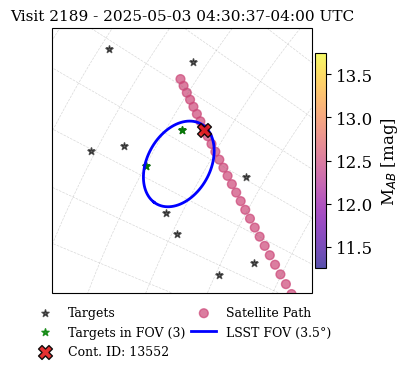

Plotting may / 2025-05-03 / exposure 2398
Field center: RA=150.027°, Dec=1.998°
Field center (Alt/Az): Alt=57.644°, Az=7.653°
Visit 2398 - 2025-05-03 19:39:35-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/visit_2398_fov_cartopy_orthographic.png


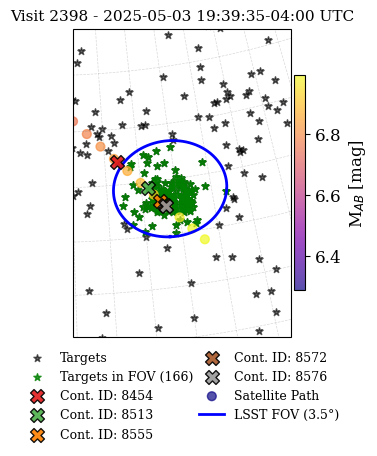

Plotting may / 2025-05-03 / exposure 2401
Field center: RA=150.027°, Dec=1.998°
Field center (Alt/Az): Alt=57.693°, Az=6.815°
Visit 2401 - 2025-05-03 19:41:23-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/visit_2401_fov_cartopy_orthographic.png


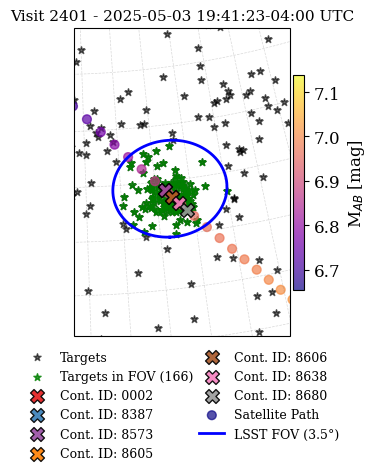

Plotting may / 2025-05-03 / exposure 2428
Field center: RA=179.545°, Dec=-0.434°
Field center (Alt/Az): Alt=49.965°, Az=47.476°
Visit 2428 - 2025-05-03 20:00:45-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/visit_2428_fov_cartopy_orthographic.png


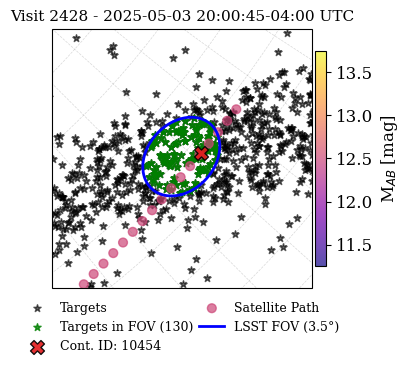

Plotting may / 2025-05-05 / exposure 4506
Field center: RA=190.900°, Dec=9.431°
Field center (Alt/Az): Alt=38.768°, Az=44.932°
Visit 4506 - 2025-05-05 20:15:46-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/visit_4506_fov_cartopy_orthographic.png


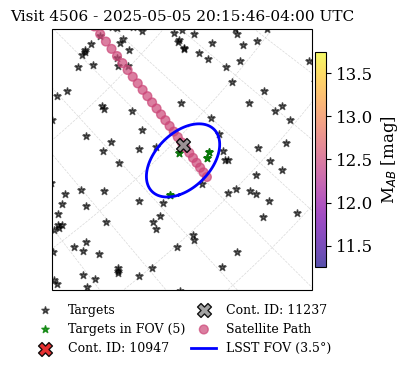

Plotting may / 2025-05-05 / exposure 4525
Field center: RA=183.699°, Dec=2.449°
Field center (Alt/Az): Alt=50.383°, Az=38.974°
Visit 4525 - 2025-05-05 20:27:57-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/visit_4525_fov_cartopy_orthographic.png


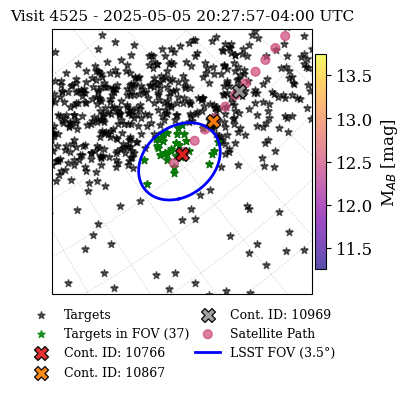

Plotting may / 2025-05-04 / exposure 3445
Field center: RA=198.858°, Dec=-1.084°
Field center (Alt/Az): Alt=35.459°, Az=67.356°
Visit 3445 - 2025-05-04 19:52:16-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/visit_3445_fov_cartopy_orthographic.png


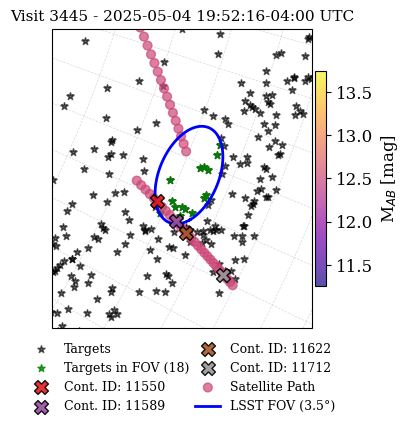

Plotting may / 2025-05-02 / exposure 1531
Field center: RA=176.253°, Dec=-2.122°
Field center (Alt/Az): Alt=49.583°, Az=52.112°
Visit 1531 - 2025-05-02 19:41:34-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/visit_1531_fov_cartopy_orthographic.png


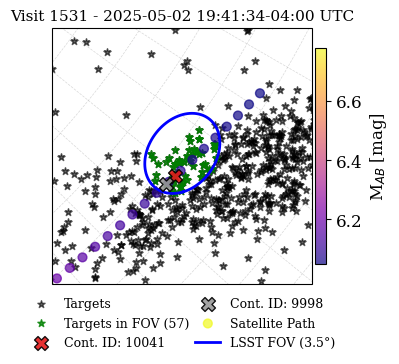

Plotting may / 2025-05-02 / exposure 1581
Field center: RA=178.789°, Dec=-4.095°
Field center (Alt/Az): Alt=55.557°, Az=45.660°
Visit 1581 - 2025-05-02 20:19:06-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/visit_1581_fov_cartopy_orthographic.png


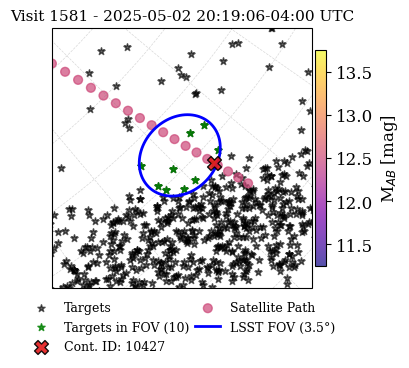

Plotting may / 2025-05-10 / exposure 8655
Field center: RA=182.061°, Dec=1.838°
Field center (Alt/Az): Alt=46.788°, Az=47.883°
Visit 8655 - 2025-05-10 19:34:20-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/visit_8655_fov_cartopy_orthographic.png


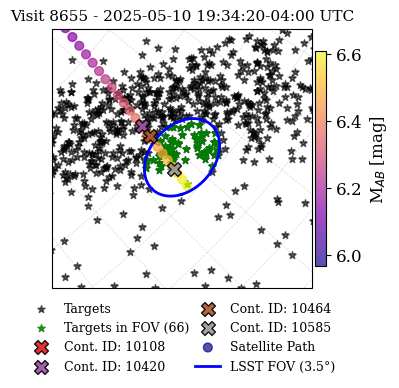

Plotting may / 2025-05-10 / exposure 8709
Field center: RA=177.043°, Dec=1.055°
Field center (Alt/Az): Alt=55.238°, Az=29.259°
Visit 8709 - 2025-05-10 20:11:35-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/visit_8709_fov_cartopy_orthographic.png


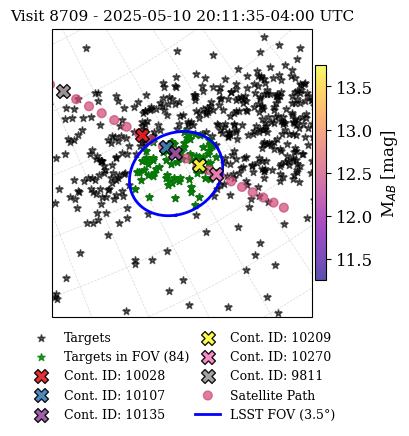

Plotting may / 2025-05-10 / exposure 8754
Field center: RA=161.429°, Dec=1.794°
Field center (Alt/Az): Alt=57.460°, Az=347.460°
Visit 8754 - 2025-05-10 20:40:37-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/visit_8754_fov_cartopy_orthographic.png


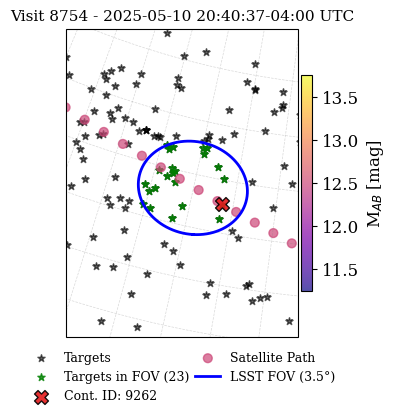

Plotting may / 2025-05-17 / exposure 12371
Field center: RA=152.141°, Dec=4.244°
Field center (Alt/Az): Alt=55.617°, Az=2.105°
Visit 12371 - 2025-05-17 19:04:32-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/visit_12371_fov_cartopy_orthographic.png


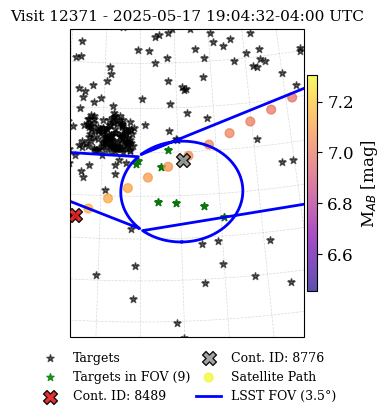

Plotting may / 2025-05-17 / exposure 12427
Field center: RA=150.513°, Dec=2.405°
Field center (Alt/Az): Alt=55.760°, Az=339.812°
Visit 12427 - 2025-05-17 19:47:29-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/visit_12427_fov_cartopy_orthographic.png


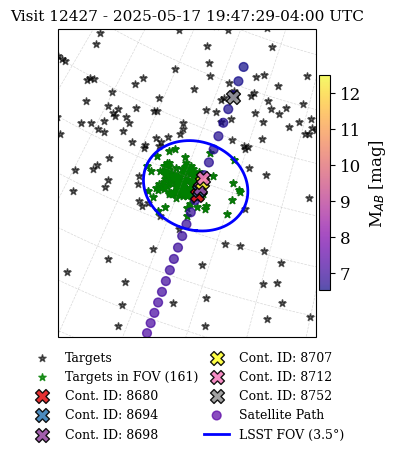

Plotting may / 2025-05-17 / exposure 12449
Field center: RA=150.513°, Dec=2.405°
Field center (Alt/Az): Alt=54.458°, Az=333.563°
Visit 12449 - 2025-05-17 20:02:40-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/visit_12449_fov_cartopy_orthographic.png


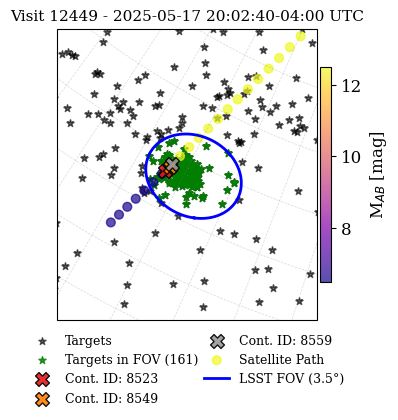

Plotting may / 2025-05-17 / exposure 12464
Field center: RA=150.513°, Dec=2.405°
Field center (Alt/Az): Alt=53.322°, Az=329.318°
Visit 12464 - 2025-05-17 20:13:38-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/visit_12464_fov_cartopy_orthographic.png


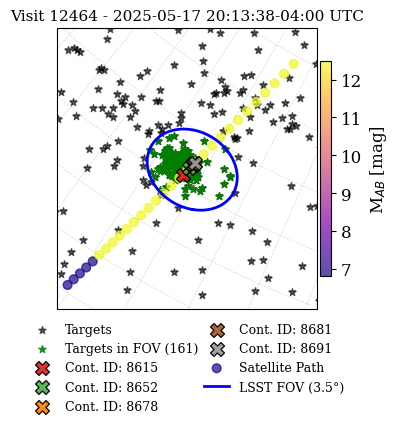

Plotting may / 2025-05-17 / exposure 12475
Field center: RA=150.513°, Dec=2.405°
Field center (Alt/Az): Alt=52.330°, Az=326.161°
Visit 12475 - 2025-05-17 20:22:13-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/visit_12475_fov_cartopy_orthographic.png


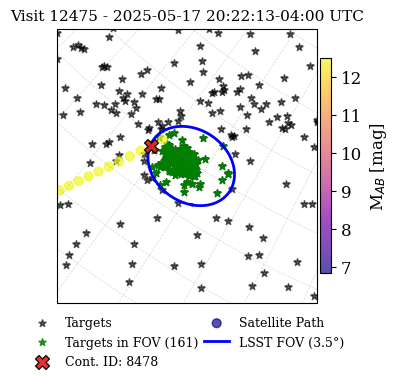

Plotting may / 2025-05-17 / exposure 12479
Field center: RA=150.513°, Dec=2.405°
Field center (Alt/Az): Alt=52.037°, Az=325.304°
Visit 12479 - 2025-05-17 20:24:37-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/visit_12479_fov_cartopy_orthographic.png


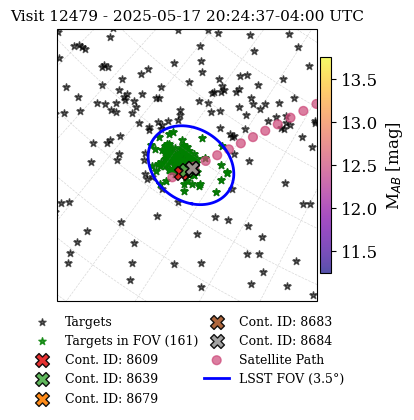

Plotting may / 2025-05-16 / exposure 11989
Field center: RA=149.982°, Dec=2.188°
Field center (Alt/Az): Alt=57.034°, Az=347.334°
Visit 11989 - 2025-05-16 19:31:57-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/visit_11989_fov_cartopy_orthographic.png


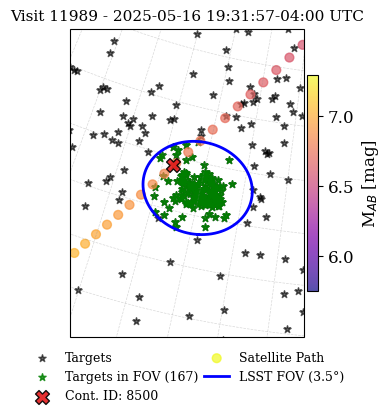

Plotting may / 2025-05-16 / exposure 11998
Field center: RA=149.982°, Dec=2.188°
Field center (Alt/Az): Alt=56.751°, Az=344.896°
Visit 11998 - 2025-05-16 19:37:23-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/visit_11998_fov_cartopy_orthographic.png


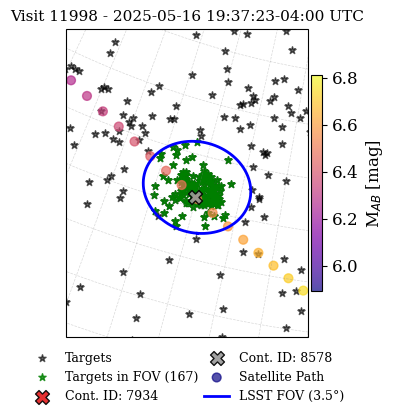

Plotting may / 2025-05-16 / exposure 11999
Field center: RA=149.982°, Dec=2.188°
Field center (Alt/Az): Alt=56.717°, Az=344.630°
Visit 11999 - 2025-05-16 19:37:59-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/visit_11999_fov_cartopy_orthographic.png


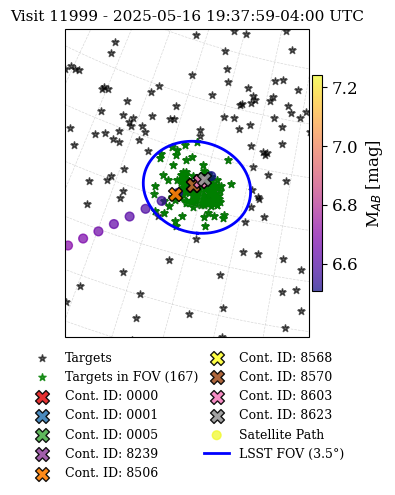

Plotting may / 2025-05-16 / exposure 12003
Field center: RA=149.982°, Dec=2.188°
Field center (Alt/Az): Alt=56.575°, Az=343.567°
Visit 12003 - 2025-05-16 19:40:23-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/visit_12003_fov_cartopy_orthographic.png


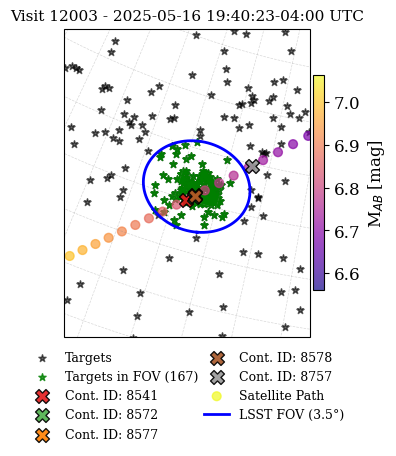

Plotting may / 2025-05-16 / exposure 12046
Field center: RA=149.982°, Dec=2.188°
Field center (Alt/Az): Alt=53.878°, Az=330.426°
Visit 12046 - 2025-05-16 20:12:07-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/visit_12046_fov_cartopy_orthographic.png


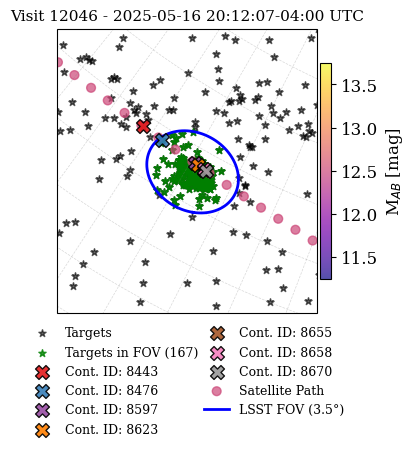

Plotting may / 2025-05-16 / exposure 12070
Field center: RA=149.982°, Dec=2.188°
Field center (Alt/Az): Alt=51.966°, Az=324.399°
Visit 12070 - 2025-05-16 20:28:30-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/visit_12070_fov_cartopy_orthographic.png


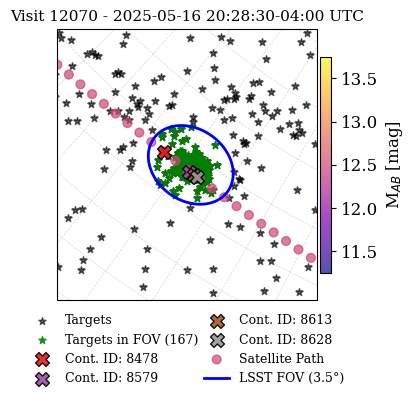

Plotting may / 2025-05-16 / exposure 12082
Field center: RA=149.982°, Dec=2.188°
Field center (Alt/Az): Alt=50.766°, Az=321.262°
Visit 12082 - 2025-05-16 20:37:40-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/visit_12082_fov_cartopy_orthographic.png


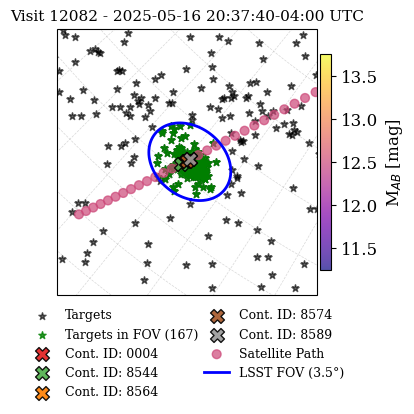

Plotting may / 2025-05-11 / exposure 9428
Field center: RA=184.238°, Dec=-9.192°
Field center (Alt/Az): Alt=53.554°, Az=61.742°
Visit 9428 - 2025-05-11 19:33:10-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/visit_9428_fov_cartopy_orthographic.png


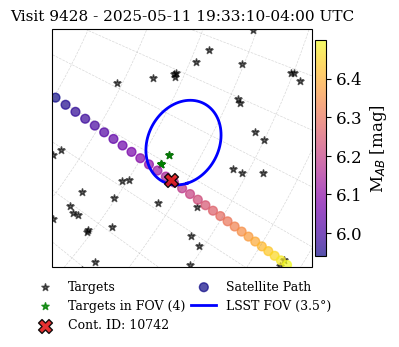

Plotting may / 2025-05-11 / exposure 9436
Field center: RA=184.606°, Dec=-0.935°
Field center (Alt/Az): Alt=48.506°, Az=51.222°
Visit 9436 - 2025-05-11 19:38:18-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/visit_9436_fov_cartopy_orthographic.png


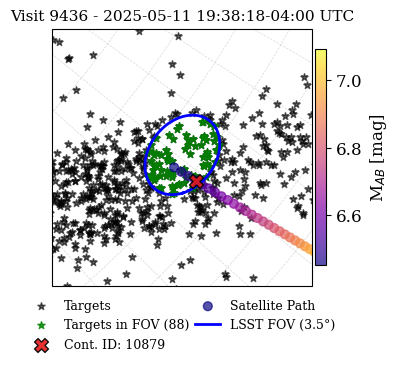

Plotting may / 2025-05-11 / exposure 9461
Field center: RA=177.808°, Dec=-4.955°
Field center (Alt/Az): Alt=58.418°, Az=41.234°
Visit 9461 - 2025-05-11 19:54:22-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/visit_9461_fov_cartopy_orthographic.png


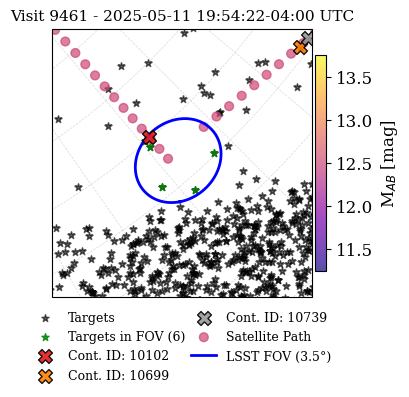

Plotting may / 2025-05-21 / exposure 14327
Field center: RA=180.352°, Dec=-0.862°
Field center (Alt/Az): Alt=53.807°, Az=40.318°
Visit 14327 - 2025-05-21 19:16:28-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/visit_14327_fov_cartopy_orthographic.png


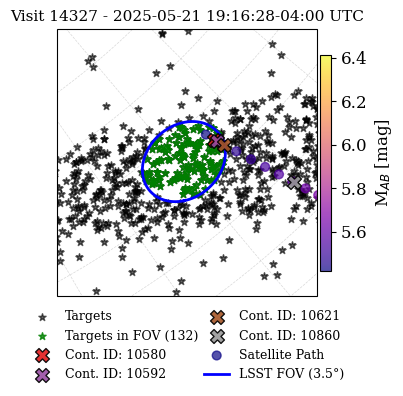

Plotting may / 2025-05-21 / exposure 14371
Field center: RA=149.687°, Dec=2.779°
Field center (Alt/Az): Alt=53.582°, Az=331.729°
Visit 14371 - 2025-05-21 19:48:59-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/visit_14371_fov_cartopy_orthographic.png


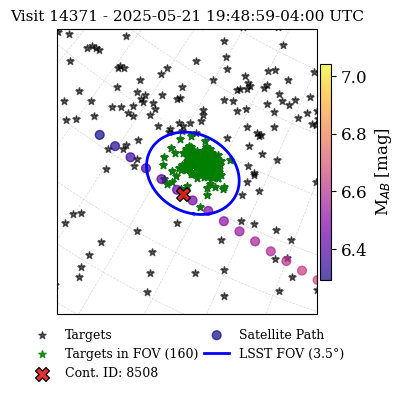

Plotting may / 2025-05-21 / exposure 14387
Field center: RA=149.687°, Dec=2.779°
Field center (Alt/Az): Alt=52.311°, Az=327.401°
Visit 14387 - 2025-05-21 20:00:34-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/visit_14387_fov_cartopy_orthographic.png


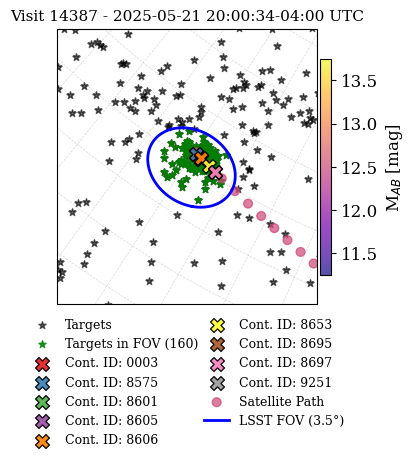

Plotting may / 2025-05-21 / exposure 14402
Field center: RA=149.687°, Dec=2.779°
Field center (Alt/Az): Alt=51.214°, Az=324.212°
Visit 14402 - 2025-05-21 20:09:35-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/visit_14402_fov_cartopy_orthographic.png


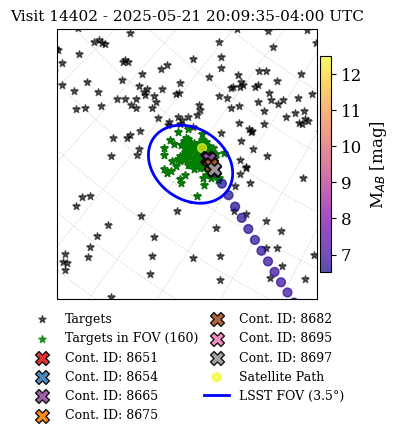

Plotting may / 2025-05-22 / exposure 15425
Field center: RA=191.494°, Dec=10.116°
Field center (Alt/Az): Alt=46.054°, Az=26.633°
Visit 15425 - 2025-05-22 20:13:08-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/visit_15425_fov_cartopy_orthographic.png


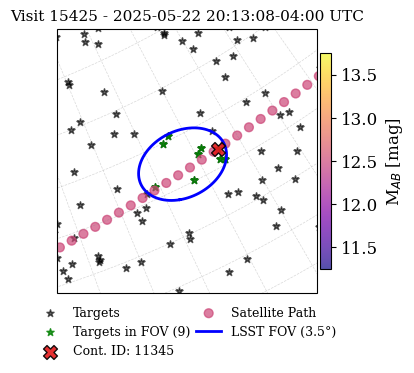

Plotting june / 2025-06-02 / exposure 16278
Field center: RA=195.934°, Dec=7.353°
Field center (Alt/Az): Alt=41.799°, Az=44.248°
Visit 16278 - 2025-06-02 18:54:54-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/visit_16278_fov_cartopy_orthographic.png


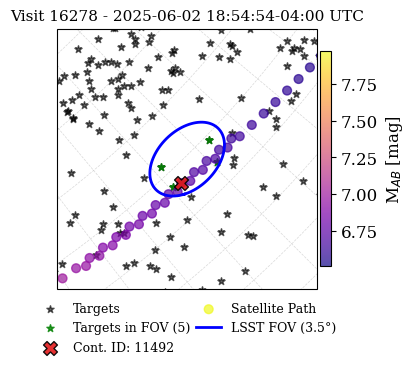

Plotting june / 2025-06-02 / exposure 16339
Field center: RA=211.858°, Dec=2.073°
Field center (Alt/Az): Alt=42.088°, Az=54.568°
Visit 16339 - 2025-06-02 19:36:04-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/visit_16339_fov_cartopy_orthographic.png


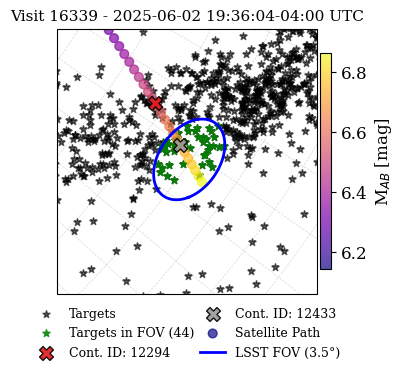

Plotting june / 2025-06-02 / exposure 16404
Field center: RA=200.932°, Dec=-1.156°
Field center (Alt/Az): Alt=57.594°, Az=29.555°
Visit 16404 - 2025-06-02 20:19:51-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/visit_16404_fov_cartopy_orthographic.png


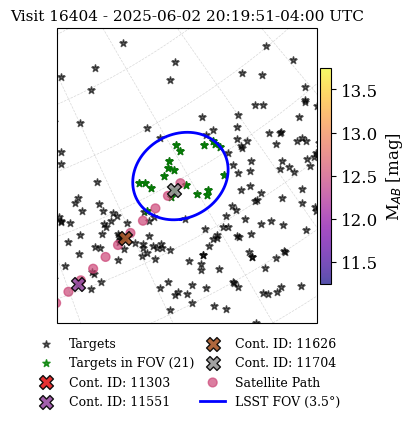

Plotting june / 2025-06-03 / exposure 16985
Field center: RA=225.391°, Dec=0.219°
Field center (Alt/Az): Alt=32.454°, Az=68.062°
Visit 16985 - 2025-06-03 19:29:10-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/visit_16985_fov_cartopy_orthographic.png


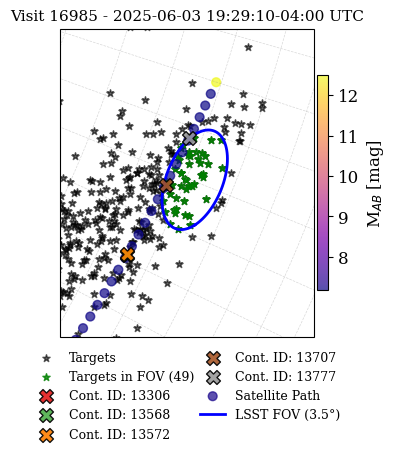

Plotting june / 2025-06-03 / exposure 17068
Field center: RA=203.303°, Dec=2.372°
Field center (Alt/Az): Alt=54.274°, Az=27.358°
Visit 17068 - 2025-06-03 20:24:23-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/visit_17068_fov_cartopy_orthographic.png


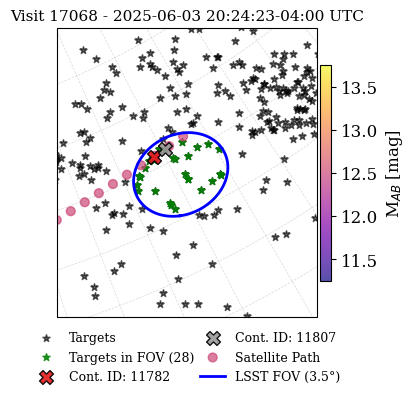

Plotting june / 2025-06-03 / exposure 17069
Field center: RA=205.000°, Dec=-0.004°
Field center (Alt/Az): Alt=55.772°, Az=31.544°
Visit 17069 - 2025-06-03 20:25:02-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/visit_17069_fov_cartopy_orthographic.png


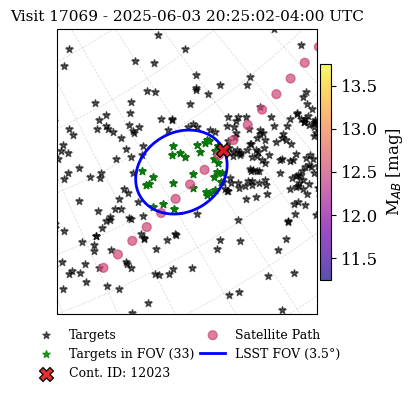

Plotting june / 2025-06-14 / exposure 19072
Field center: RA=150.154°, Dec=2.107°
Field center (Alt/Az): Alt=45.794°, Az=311.067°
Visit 19072 - 2025-06-14 19:17:51-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/visit_19072_fov_cartopy_orthographic.png


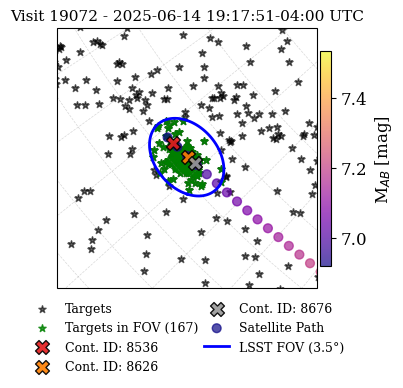

Plotting june / 2025-06-14 / exposure 19085
Field center: RA=150.154°, Dec=2.107°
Field center (Alt/Az): Alt=44.168°, Az=308.481°
Visit 19085 - 2025-06-14 19:27:37-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/visit_19085_fov_cartopy_orthographic.png


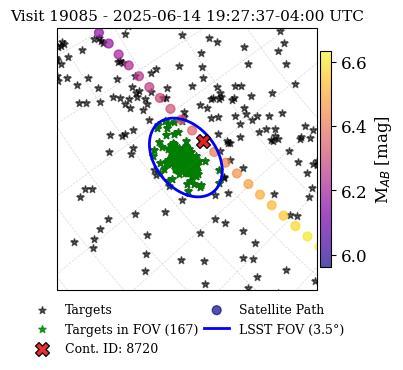

Plotting june / 2025-06-14 / exposure 19089
Field center: RA=150.154°, Dec=2.107°
Field center (Alt/Az): Alt=43.759°, Az=307.868°
Visit 19089 - 2025-06-14 19:30:01-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/visit_19089_fov_cartopy_orthographic.png


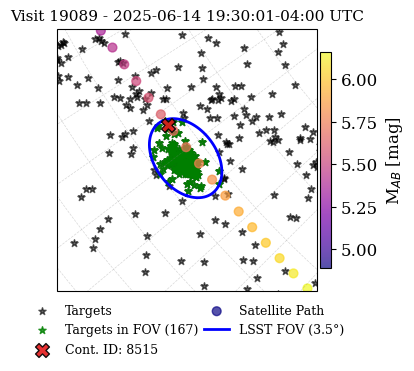

Plotting june / 2025-06-14 / exposure 19098
Field center: RA=150.154°, Dec=2.107°
Field center (Alt/Az): Alt=42.828°, Az=306.520°
Visit 19098 - 2025-06-14 19:35:25-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/visit_19098_fov_cartopy_orthographic.png


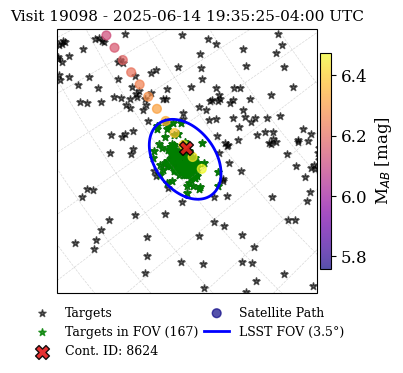

Plotting june / 2025-06-14 / exposure 19109
Field center: RA=150.154°, Dec=2.107°
Field center (Alt/Az): Alt=41.317°, Az=304.466°
Visit 19109 - 2025-06-14 19:43:59-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/visit_19109_fov_cartopy_orthographic.png


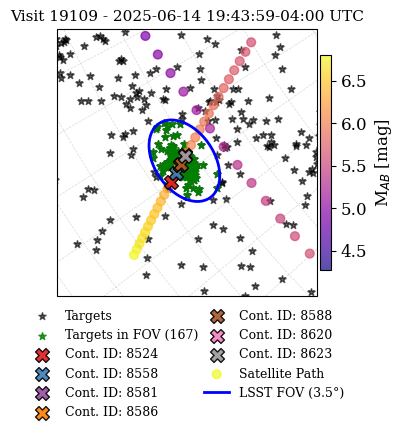

Plotting june / 2025-06-14 / exposure 19113
Field center: RA=150.154°, Dec=2.107°
Field center (Alt/Az): Alt=40.887°, Az=303.908°
Visit 19113 - 2025-06-14 19:46:23-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/visit_19113_fov_cartopy_orthographic.png


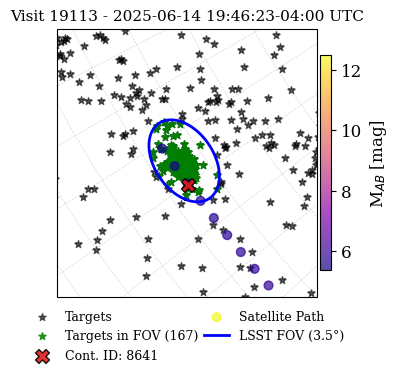

Plotting june / 2025-06-15 / exposure 19512
Field center: RA=149.897°, Dec=2.414°
Field center (Alt/Az): Alt=42.318°, Az=306.406°
Visit 19512 - 2025-06-15 19:32:07-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/visit_19512_fov_cartopy_orthographic.png


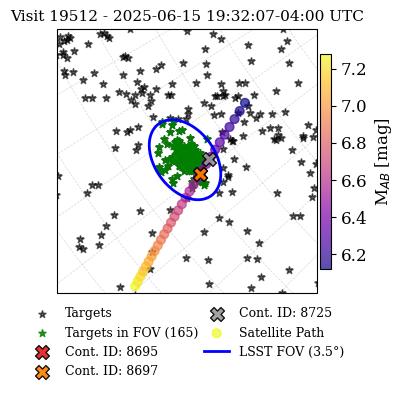

Plotting june / 2025-06-15 / exposure 19523
Field center: RA=149.897°, Dec=2.414°
Field center (Alt/Az): Alt=41.157°, Az=304.830°
Visit 19523 - 2025-06-15 19:38:43-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/visit_19523_fov_cartopy_orthographic.png


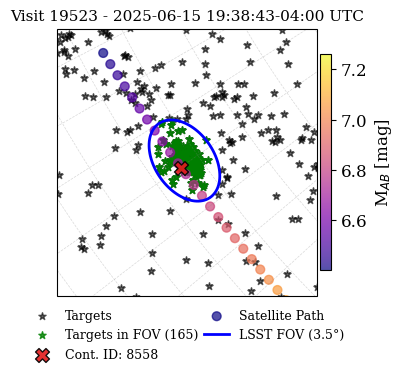

Plotting june / 2025-06-15 / exposure 19532


KeyboardInterrupt: 

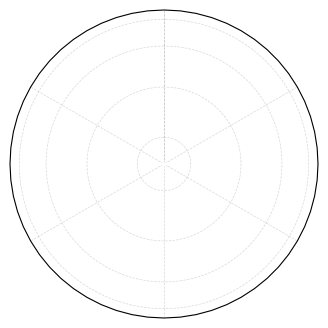

In [16]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature

def plot_visit_fov_and_targets_cartopy(exp_data, targets, fov_radius_deg=1.75):
    """
    Plot visit field of view and targets using Cartopy with Orthographic projection.
    Shows sky as viewed from Rubin Observatory in alt/az coordinates.
    """
    fig = plt.figure(figsize=(4, 4))
    # Create orthographic projection centered on zenith (alt=90)
    ax = fig.add_subplot(111, projection=ccrs.Orthographic(central_longitude=0, central_latitude=90))

    if 'SATELLITE_DATA' not in exp_data:
        print("No SATELLITE_DATA found in exposure")
        return None, None

    if 'VISIT_INFO' not in exp_data:
        print("No VISIT_INFO found in exposure")
        return None, None

    sat_header = exp_data['SATELLITE_DATA']['header']
    visit_data = exp_data['VISIT_INFO']['data']

    if visit_data is None or len(visit_data) == 0:
        print("No visit data available")
        return None, None

    obs_time = Time(datetime.fromisoformat(sat_header['EXPSTART']))
    rubin_location = EarthLocation.of_site('rubin')
    altaz_frame = AltAz(obstime=obs_time, location=rubin_location)

    field_coord = SkyCoord(ra=visit_data['FIELD_RA'][0]*u.deg,
                        dec=visit_data['FIELD_DEC'][0]*u.deg, frame='icrs')

    field_altaz = field_coord.transform_to(altaz_frame)
    field_alt = field_altaz.alt.deg
    field_az = field_altaz.az.deg

    # Add gridlines
    ax.gridlines(draw_labels=False, linewidth=0.5, color='gray', alpha=0.3, linestyle='--')

    if targets is not None and len(targets) > 0:
        ti = ts.from_datetime(datetime.fromisoformat(sat_header['EXPSTART']))

        target_coords = []
        target_altaz_list = []
        for target_star in targets:
            astrometric = rubinobs_astr.at(ti).observe(target_star)
            apparent = astrometric.apparent()
            alt, az, distance = apparent.altaz()

            if alt.degrees > 30:
                coord = SkyCoord(ra=target_star.ra._degrees*u.deg,
                                dec=target_star.dec.degrees*u.deg, frame='icrs')
                target_coords.append(coord)
                target_altaz_list.append((az.degrees, alt.degrees))

        if target_coords:
            target_coords = SkyCoord(target_coords)
            target_altaz = target_coords.transform_to(altaz_frame)
            margin = fov_radius_deg * 5
            separations_deg = field_altaz.separation(target_altaz).deg
            # visible = target_altaz.alt.deg > 30
            nearby_mask = (separations_deg <= margin) 
            fov_mask = (separations_deg <= fov_radius_deg)

            # Plot nearby targets
            if np.any(nearby_mask):
                ax.scatter(target_altaz.az.deg[nearby_mask],
                        target_altaz.alt.deg[nearby_mask], 
                        c='black', s=30, alpha=0.6, marker='*',
                        label=f'Targets',
                        transform=ccrs.PlateCarree())
            # ax.scatter(target_altaz.az.deg,
            #         target_altaz.alt.deg, 
            #         c='black', s=30, alpha=0.6, marker='*',
            #         label=f'Targets',
            #         transform=ccrs.PlateCarree())
            # Plot targets in FOV
            if np.any(fov_mask):
                ax.scatter(target_altaz.az.deg[fov_mask],
                        target_altaz.alt.deg[fov_mask], 
                        c='green', s=30, alpha=0.8, marker='*',
                        label=f'Targets in FOV ({fov_mask.sum()})',
                        transform=ccrs.PlateCarree())

    if 'CONTAMINATED_TARGETS' in exp_data:
        cont_data = exp_data['CONTAMINATED_TARGETS']['data']
        if cont_data is not None and len(cont_data) > 0:
            if 'Target_Alt' in cont_data.dtype.names and 'Target_Az' in cont_data.dtype.names:
                cont_altitudes = cont_data['Target_Alt']
                cont_azimuths = cont_data['Target_Az']
                cont_altaz = SkyCoord(az=cont_azimuths*u.deg, alt=cont_altitudes*u.deg, frame=altaz_frame)

                unique_targets = np.unique(cont_data['Target_Name'])
                colors = plt.cm.Set1(np.linspace(0, 1, len(unique_targets)))

                for i, target_name in enumerate(unique_targets):
                    target_indices = np.where(cont_data['Target_Name'] == target_name)[0]
                    if len(target_indices) > 0:
                        target_name_str = target_name.split()[1].split('_')[1]
                        ax.scatter(cont_altaz.az.deg[target_indices],
                                cont_altaz.alt.deg[target_indices],
                                c=[colors[i]], s=100, marker='X', edgecolors='black',
                                alpha=0.9, label=f'Cont. ID: {target_name_str}', 
                                zorder=4, transform=ccrs.PlateCarree())

    sat_data = exp_data['SATELLITE_DATA']['data']
    if sat_data is not None and len(sat_data) > 0:
        sat_altitudes = sat_data['Altitude']
        sat_azimuths = sat_data['Azimuth']

        if 'AB_Magnitude' in sat_data.dtype.names:
            ab_magnitudes = sat_data['AB_Magnitude']
            sc = ax.scatter(sat_azimuths, sat_altitudes,
                            c=ab_magnitudes, cmap='plasma', s=40, alpha=0.7, 
                            label='Satellite Path', transform=ccrs.PlateCarree())
            cbar = plt.colorbar(sc, ax=ax, label=r'M$_{AB}$ [mag]', 
                            shrink=0.7, pad=0.01)
        else:
            ax.scatter(sat_azimuths, sat_altitudes, 
                    c='red', s=40, alpha=0.7, label='Satellite Path',
                    transform=ccrs.PlateCarree())

    # Plot FOV boundary as a circle
    fov_boundary = field_coord.directional_offset_by(
        position_angle=np.linspace(0, 360, 100)*u.deg, 
        separation=fov_radius_deg*u.deg
    )
    fov_boundary_altaz = fov_boundary.transform_to(altaz_frame)
    ax.plot(fov_boundary_altaz.az.deg, fov_boundary_altaz.alt.deg, 
            color='blue', linewidth=2, transform=ccrs.PlateCarree(),
            label=f'LSST FOV ({fov_radius_deg*2:.1f}°)')

    # Set axis labels and appearance
    ax.set_xlabel('Azimuth (degrees)', fontsize=11)
    ax.set_ylabel('Altitude (degrees)', fontsize=11)

    # Set extent to show reasonable area around zenith
    extent_range = fov_radius_deg * 3
    ax.set_extent([field_az - extent_range, field_az + extent_range,
                max(0, field_alt - extent_range), min(90, field_alt + extent_range)],
                crs=ccrs.PlateCarree())

    visit_id = visit_data['VISIT_ID'][0] if 'VISIT_ID' in visit_data.dtype.names else 'Unknown'
    filter_name = visit_data['FILTER'][0] if 'FILTER' in visit_data.dtype.names else 'Unknown'
    if isinstance(filter_name, bytes):
        filter_name = filter_name.decode()

    ti = ts.from_datetime(datetime.fromisoformat(sat_header['EXPSTART']))
    title = f'Visit {visit_id} - {ti.astimezone(zone)} UTC'
    ax.set_title(title, fontsize=11)

    ax.legend(loc='upper center', fontsize=9, framealpha=0.95, ncol=2, columnspacing=0.5, bbox_to_anchor=(0.5, -0.01))
    plt.subplots_adjust(wspace=0.0, hspace=0.0)

    print(f"Field center: RA={visit_data['FIELD_RA'][0]:.3f}°, Dec={visit_data['FIELD_DEC'][0]:.3f}°")
    print(f"Field center (Alt/Az): Alt={field_alt:.3f}°, Az={field_az:.3f}°")
    print(title)

    return fig, ax  

def plot_contaminated_exposures_from_fov_df(monthly_exposures_data, fov_contamination_df, targets):
    """
    Plot only exposures listed in fov_contamination_df (faster than scanning all monthly exposures).
    Expected columns in fov_contamination_df: month, day, exposure_id
    """
    required = {'month', 'day', 'visit_id'}
    missing = required - set(fov_contamination_df.columns)
    if missing:
        print(f"Missing required columns in fov_contamination_df: {missing}")
        return

    exposure_rows = fov_contamination_df[list(required)].dropna().drop_duplicates()
    print(f"Total unique contaminated exposures to plot: {len(exposure_rows)}")

    for _, row in exposure_rows.iterrows():
        month = str(row['month']).lower()
        day = str(row['day'])
        exp_id = row['visit_id']
        try:
            exp_id = int(exp_id)
        except Exception:
            pass

        if month not in monthly_exposures_data:
            print(f"Month not found in monthly_exposures_data: {month}")
            continue
        if day not in monthly_exposures_data[month]:
            print(f"Day not found: {month}/{day}")
            continue
        if exp_id not in monthly_exposures_data[month][day]:
            print(f"Exposure not found: {month}/{day}/{exp_id}")
            continue

        exp_data = monthly_exposures_data[month][day][exp_id]
        print(f"Plotting {month} / {day} / exposure {exp_id}")
        fig, ax = plot_visit_fov_and_targets_cartopy(exp_data, targets, fov_radius_deg=1.75)
        if fig is not None:
            save_path = os.path.join('/data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed', f"visit_{exp_id}_fov_cartopy_orthographic.png")
            fig.savefig(save_path, dpi=300, bbox_inches='tight')
            print(f"Saved: {save_path}")
            plt.show()
        else:
            print("Failed to create plot")
plot_contaminated_exposures_from_fov_df(monthly_exposures_data, fov_targets_df, targets_)

## OpSim statistics and percentage calculations

Total unique contaminated exposures to plot: 2857
Plotting may / 2025-05-03 / exposure 2189
Field center: RA=221.433°, Dec=-40.441°
Field center (Alt/Az): Alt=43.566°, Az=241.052°
Visit 2189 - 2025-05-03 04:30:37-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/not_fov/visit_2189_fov_cartopy_orthographic.png


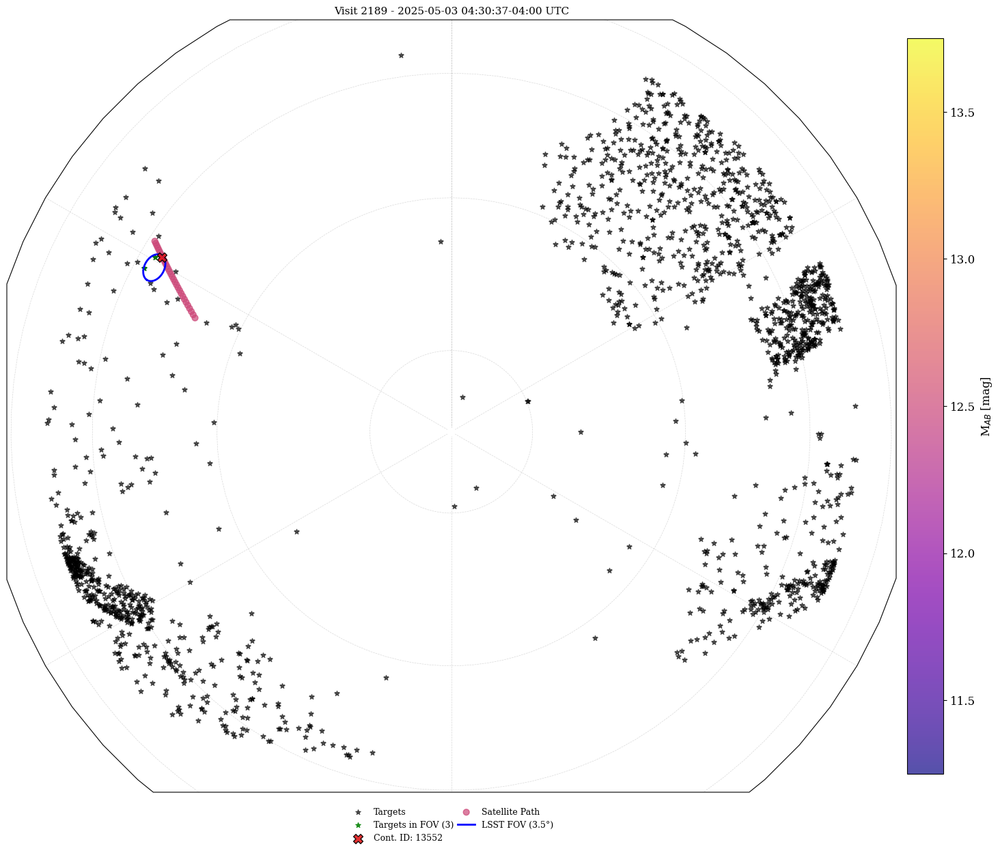

Plotting may / 2025-05-03 / exposure 2368
Field center: RA=168.234°, Dec=3.954°
Field center (Alt/Az): Alt=46.991°, Az=42.442°
Visit 2368 - 2025-05-03 19:18:56-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/not_fov/visit_2368_fov_cartopy_orthographic.png


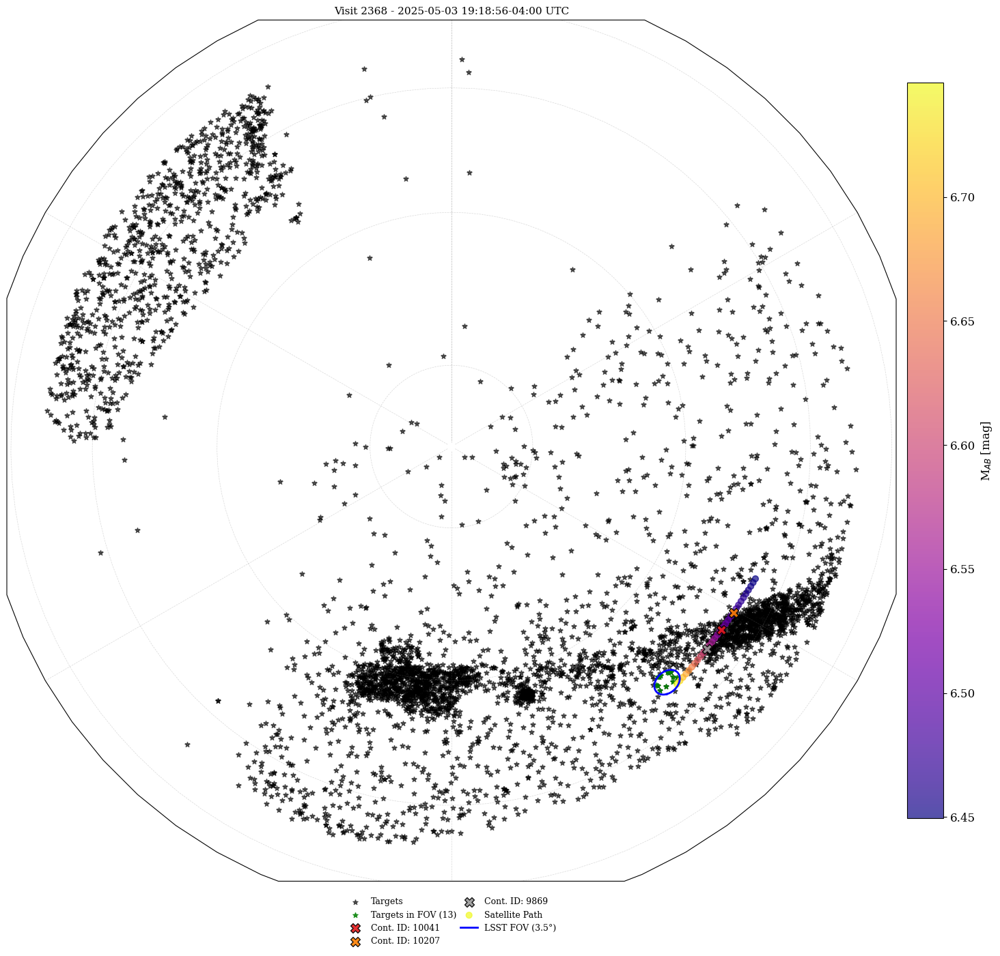

Plotting may / 2025-05-03 / exposure 2377
Field center: RA=162.017°, Dec=8.682°
Field center (Alt/Az): Alt=46.793°, Az=29.304°
Visit 2377 - 2025-05-03 19:24:44-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/not_fov/visit_2377_fov_cartopy_orthographic.png


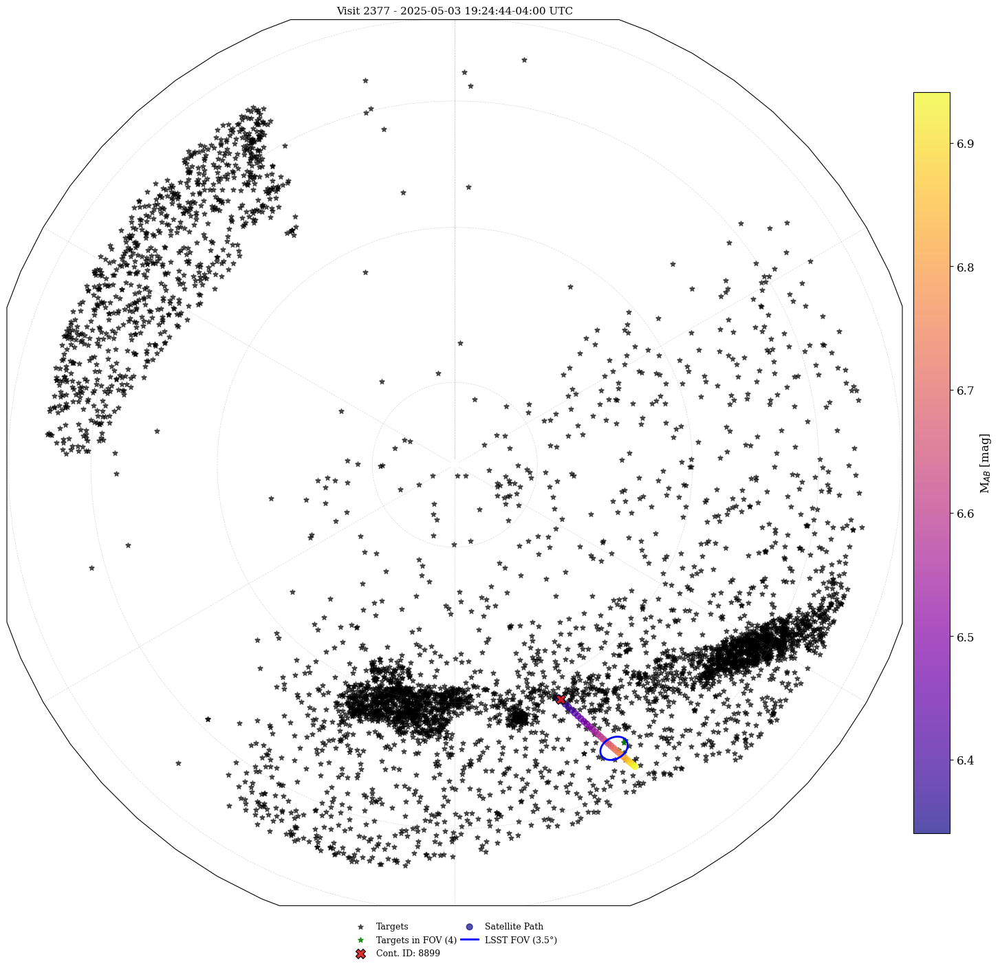

Plotting may / 2025-05-03 / exposure 2398
Field center: RA=150.027°, Dec=1.998°
Field center (Alt/Az): Alt=57.644°, Az=7.653°
Visit 2398 - 2025-05-03 19:39:35-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/not_fov/visit_2398_fov_cartopy_orthographic.png


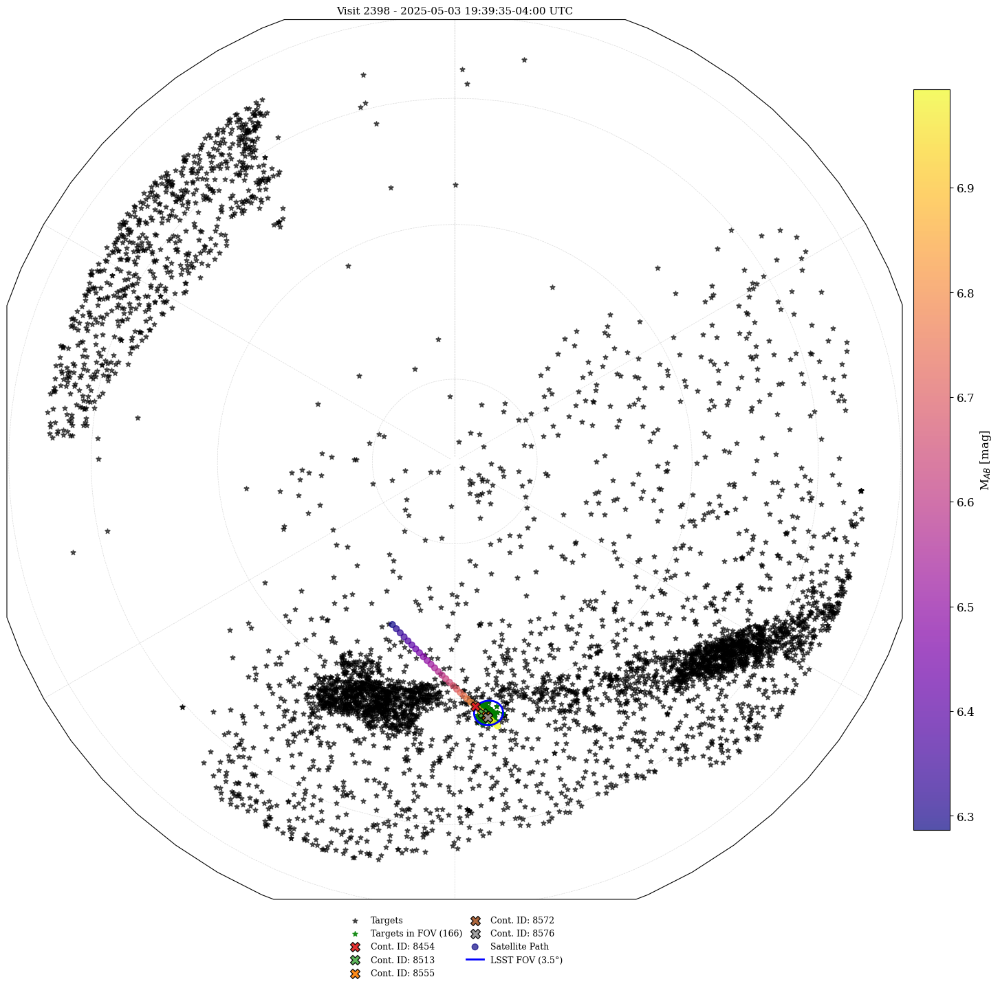

Plotting may / 2025-05-03 / exposure 2401
Field center: RA=150.027°, Dec=1.998°
Field center (Alt/Az): Alt=57.693°, Az=6.815°
Visit 2401 - 2025-05-03 19:41:23-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/not_fov/visit_2401_fov_cartopy_orthographic.png


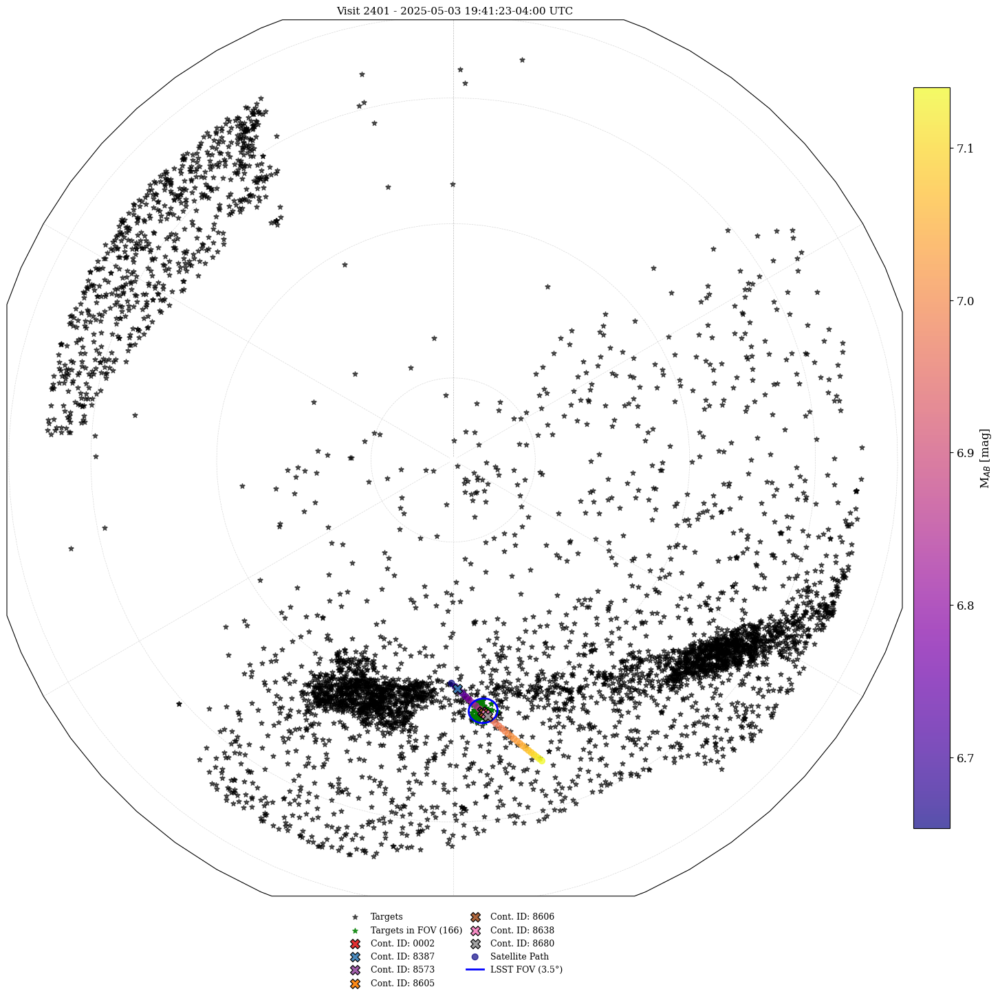

Plotting may / 2025-05-03 / exposure 2420
Field center: RA=179.232°, Dec=-11.324°
Field center (Alt/Az): Alt=56.996°, Az=61.630°
Visit 2420 - 2025-05-03 19:55:36-04:00 UTC
Saved: /data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/not_fov/visit_2420_fov_cartopy_orthographic.png


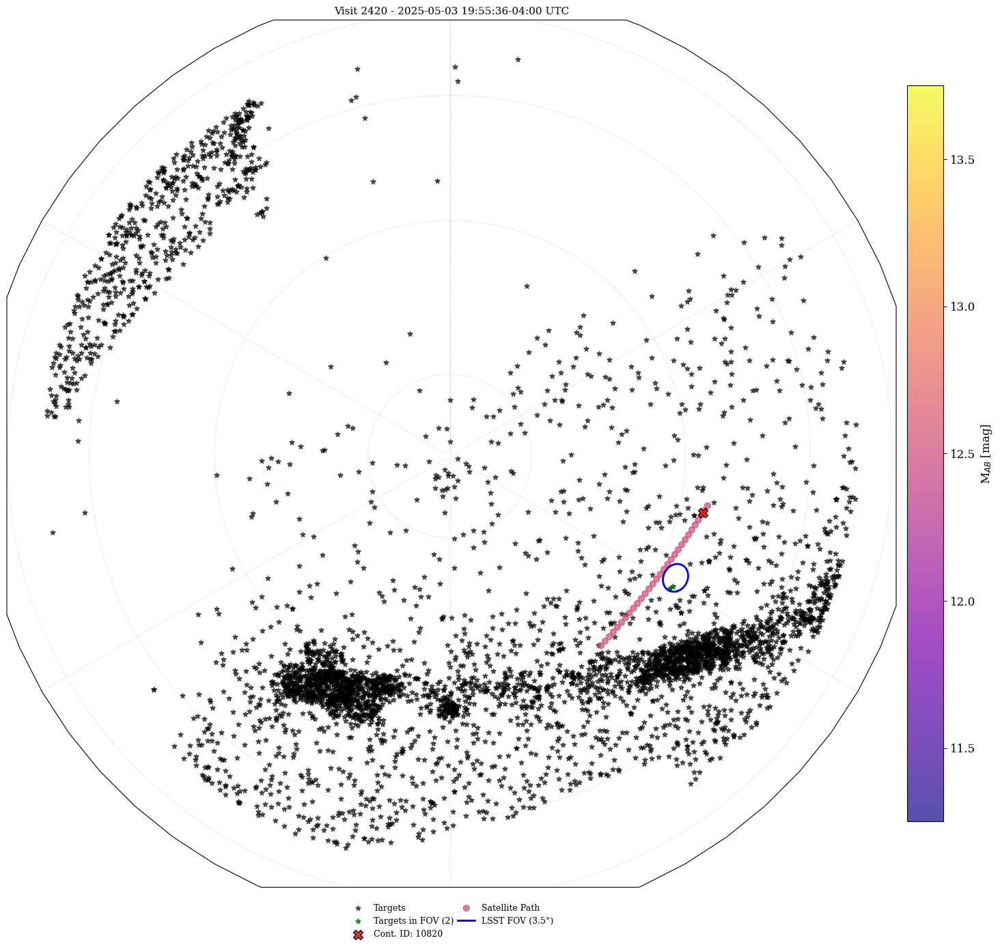

Plotting may / 2025-05-03 / exposure 2425


KeyboardInterrupt: 

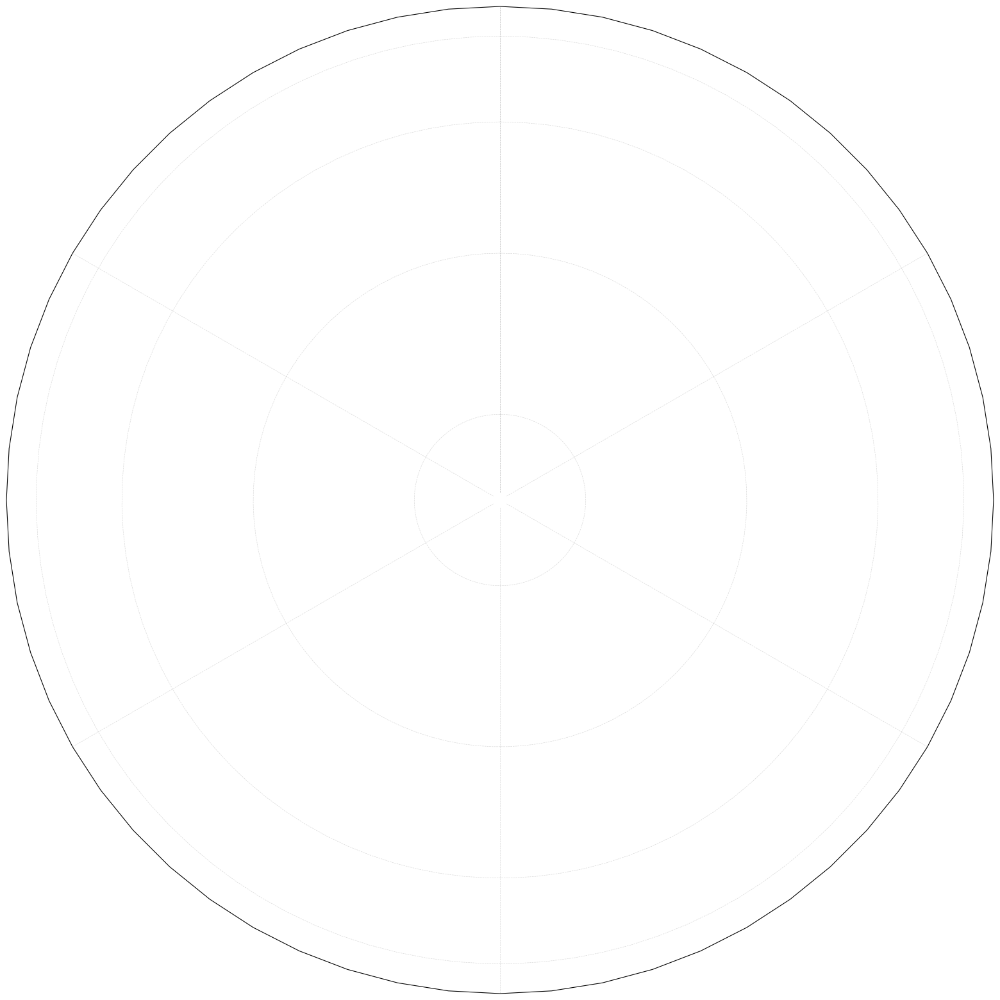

In [18]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature

def plot_visit_fov_and_targets_cartopy(exp_data, targets, fov_radius_deg=1.75):
    """
    Plot visit field of view and targets using Cartopy with Orthographic projection.
    Shows sky as viewed from Rubin Observatory in alt/az coordinates.
    """
    fig = plt.figure(figsize=(20, 20))
    # Create orthographic projection centered on zenith (alt=90)
    ax = fig.add_subplot(111, projection=ccrs.Orthographic(central_longitude=0, central_latitude=90))

    if 'SATELLITE_DATA' not in exp_data:
        print("No SATELLITE_DATA found in exposure")
        return None, None

    if 'VISIT_INFO' not in exp_data:
        print("No VISIT_INFO found in exposure")
        return None, None

    sat_header = exp_data['SATELLITE_DATA']['header']
    visit_data = exp_data['VISIT_INFO']['data']

    if visit_data is None or len(visit_data) == 0:
        print("No visit data available")
        return None, None

    obs_time = Time(datetime.fromisoformat(sat_header['EXPSTART']))
    rubin_location = EarthLocation.of_site('rubin')
    altaz_frame = AltAz(obstime=obs_time, location=rubin_location)

    field_coord = SkyCoord(ra=visit_data['FIELD_RA'][0]*u.deg,
                        dec=visit_data['FIELD_DEC'][0]*u.deg, frame='icrs')

    field_altaz = field_coord.transform_to(altaz_frame)
    field_alt = field_altaz.alt.deg
    field_az = field_altaz.az.deg

    # Add gridlines
    ax.gridlines(draw_labels=False, linewidth=0.5, color='gray', alpha=0.3, linestyle='--')

    if targets is not None and len(targets) > 0:
        ti = ts.from_datetime(datetime.fromisoformat(sat_header['EXPSTART']))

        target_coords = []
        target_altaz_list = []
        for target_star in targets:
            astrometric = rubinobs_astr.at(ti).observe(target_star)
            apparent = astrometric.apparent()
            alt, az, distance = apparent.altaz()

            if alt.degrees > 30:
                coord = SkyCoord(ra=target_star.ra._degrees*u.deg,
                                dec=target_star.dec.degrees*u.deg, frame='icrs')
                target_coords.append(coord)
                target_altaz_list.append((az.degrees, alt.degrees))

        if target_coords:
            target_coords = SkyCoord(target_coords)
            target_altaz = target_coords.transform_to(altaz_frame)
            margin = fov_radius_deg * 100
            separations_deg = field_altaz.separation(target_altaz).deg
            # visible = target_altaz.alt.deg > 30
            nearby_mask = (separations_deg <= margin) 
            fov_mask = (separations_deg <= fov_radius_deg)

            # Plot nearby targets
            if np.any(nearby_mask):
                ax.scatter(target_altaz.az.deg[nearby_mask],
                        target_altaz.alt.deg[nearby_mask], 
                        c='black', s=30, alpha=0.6, marker='*',
                        label=f'Targets',
                        transform=ccrs.PlateCarree())
            # ax.scatter(target_altaz.az.deg,
            #         target_altaz.alt.deg, 
            #         c='black', s=30, alpha=0.6, marker='*',
            #         label=f'Targets',
            #         transform=ccrs.PlateCarree())
            # Plot targets in FOV
            if np.any(fov_mask):
                ax.scatter(target_altaz.az.deg[fov_mask],
                        target_altaz.alt.deg[fov_mask], 
                        c='green', s=30, alpha=0.8, marker='*',
                        label=f'Targets in FOV ({fov_mask.sum()})',
                        transform=ccrs.PlateCarree())

    if 'CONTAMINATED_TARGETS' in exp_data:
        cont_data = exp_data['CONTAMINATED_TARGETS']['data']
        if cont_data is not None and len(cont_data) > 0:
            if 'Target_Alt' in cont_data.dtype.names and 'Target_Az' in cont_data.dtype.names:
                cont_altitudes = cont_data['Target_Alt']
                cont_azimuths = cont_data['Target_Az']
                cont_altaz = SkyCoord(az=cont_azimuths*u.deg, alt=cont_altitudes*u.deg, frame=altaz_frame)

                unique_targets = np.unique(cont_data['Target_Name'])
                colors = plt.cm.Set1(np.linspace(0, 1, len(unique_targets)))

                for i, target_name in enumerate(unique_targets):
                    target_indices = np.where(cont_data['Target_Name'] == target_name)[0]
                    if len(target_indices) > 0:
                        target_name_str = target_name.split()[1].split('_')[1]
                        ax.scatter(cont_altaz.az.deg[target_indices],
                                cont_altaz.alt.deg[target_indices],
                                c=[colors[i]], s=100, marker='X', edgecolors='black',
                                alpha=0.9, label=f'Cont. ID: {target_name_str}', 
                                zorder=4, transform=ccrs.PlateCarree())

    sat_data = exp_data['SATELLITE_DATA']['data']
    if sat_data is not None and len(sat_data) > 0:
        sat_altitudes = sat_data['Altitude']
        sat_azimuths = sat_data['Azimuth']

        if 'AB_Magnitude' in sat_data.dtype.names:
            ab_magnitudes = sat_data['AB_Magnitude']
            sc = ax.scatter(sat_azimuths, sat_altitudes,
                            c=ab_magnitudes, cmap='plasma', s=40, alpha=0.7, 
                            label='Satellite Path', transform=ccrs.PlateCarree())
            cbar = plt.colorbar(sc, ax=ax, label=r'M$_{AB}$ [mag]', 
                            shrink=0.7, pad=0.01)
        else:
            ax.scatter(sat_azimuths, sat_altitudes, 
                    c='red', s=40, alpha=0.7, label='Satellite Path',
                    transform=ccrs.PlateCarree())

    # Plot FOV boundary as a circle
    fov_boundary = field_coord.directional_offset_by(
        position_angle=np.linspace(0, 360, 100)*u.deg, 
        separation=fov_radius_deg*u.deg
    )
    fov_boundary_altaz = fov_boundary.transform_to(altaz_frame)
    ax.plot(fov_boundary_altaz.az.deg, fov_boundary_altaz.alt.deg, 
            color='blue', linewidth=2, transform=ccrs.PlateCarree(),
            label=f'LSST FOV ({fov_radius_deg*2:.1f}°)')

    # Set axis labels and appearance
    ax.set_xlabel('Azimuth (degrees)', fontsize=11)
    ax.set_ylabel('Altitude (degrees)', fontsize=11)

    # Set extent to show reasonable area around zenith
    # extent_range = fov_radius_deg * 3
    # ax.set_extent([field_az - extent_range, field_az + extent_range,
    #             max(0, field_alt - extent_range), min(90, field_alt + extent_range)],
    #             crs=ccrs.PlateCarree())

    visit_id = visit_data['VISIT_ID'][0] if 'VISIT_ID' in visit_data.dtype.names else 'Unknown'
    filter_name = visit_data['FILTER'][0] if 'FILTER' in visit_data.dtype.names else 'Unknown'
    if isinstance(filter_name, bytes):
        filter_name = filter_name.decode()

    ti = ts.from_datetime(datetime.fromisoformat(sat_header['EXPSTART']))
    title = f'Visit {visit_id} - {ti.astimezone(zone)} UTC'
    ax.set_title(title, fontsize=11)

    ax.legend(loc='upper center', fontsize=9, framealpha=0.95, ncol=2, columnspacing=0.5, bbox_to_anchor=(0.5, -0.01))
    plt.subplots_adjust(wspace=0.0, hspace=0.0)

    print(f"Field center: RA={visit_data['FIELD_RA'][0]:.3f}°, Dec={visit_data['FIELD_DEC'][0]:.3f}°")
    print(f"Field center (Alt/Az): Alt={field_alt:.3f}°, Az={field_az:.3f}°")
    print(title)

    return fig, ax  

def plot_contaminated_exposures_from_fov_df(monthly_exposures_data, fov_contamination_df, targets):
    """
    Plot only exposures listed in fov_contamination_df (faster than scanning all monthly exposures).
    Expected columns in fov_contamination_df: month, day, exposure_id
    """
    required = {'month', 'day', 'visit_id'}
    missing = required - set(fov_contamination_df.columns)
    if missing:
        print(f"Missing required columns in fov_contamination_df: {missing}")
        return

    exposure_rows = fov_contamination_df[list(required)].dropna().drop_duplicates()
    print(f"Total unique contaminated exposures to plot: {len(exposure_rows)}")

    for _, row in exposure_rows.iterrows():
        month = str(row['month']).lower()
        day = str(row['day'])
        exp_id = row['visit_id']
        try:
            exp_id = int(exp_id)
        except Exception:
            pass

        if month not in monthly_exposures_data:
            print(f"Month not found in monthly_exposures_data: {month}")
            continue
        if day not in monthly_exposures_data[month]:
            print(f"Day not found: {month}/{day}")
            continue
        if exp_id not in monthly_exposures_data[month][day]:
            print(f"Exposure not found: {month}/{day}/{exp_id}")
            continue

        exp_data = monthly_exposures_data[month][day][exp_id]
        print(f"Plotting {month} / {day} / exposure {exp_id}")
        fig, ax = plot_visit_fov_and_targets_cartopy(exp_data, targets, fov_radius_deg=1.75)
        if fig is not None:
            save_path = os.path.join('/data/a.saricaoglu/repo/RubinsForge/Skyfield/plots/contaminated_exposures/fixed/not_fov', f"visit_{exp_id}_fov_cartopy_orthographic.png")
            fig.savefig(save_path, dpi=300, bbox_inches='tight')
            print(f"Saved: {save_path}")
            plt.show()
        else:
            print("Failed to create plot")
plot_contaminated_exposures_from_fov_df(monthly_exposures_data, contamination_df, targets_)

In [39]:
total_visits = opsim_data['visit_id'].nunique()
visits_with_events = daily_stats['num_exposures'].sum()
visits_with_contamination = contamination_df_0_analysis['visit_id'].nunique()
print(f"Total unique visits in opsim_data: {total_visits}")
print(f"Visits with events: {visits_with_events}")
print(f"Visits with contamination: {visits_with_contamination}")
percentage_contaminated = (visits_with_contamination / visits_with_events) * 100 if visits_with_events > 0 else 0
print(f"Percentage of visits with contamination: {percentage_contaminated:.2f}%")
percentage_with_events = (visits_with_events / total_visits) * 100 if total_visits > 0 else 0
print(f"Percentage of visits with events: {percentage_with_events:.2f}%")

total_unique_targets_observed = opsim_data['target_id'].nunique()
total_unique_targets_in_iereg = len(set(opsim_data['target_id'].unique()) & set(iereg_target_nos))
print(f"Total unique targets observed: {total_unique_targets_observed}")
print(f"Unique targets in IEREG: {total_unique_targets_in_iereg} out of {total_unique_targets_observed} observed targets")
contaminated_targets = contamination_df_0_analysis['target_name'].unique()
contaminated_targets_in_iereg = [t for t in contaminated_targets if t in iereg_target_nos]
num_contaminated_targets = len(contaminated_targets)
print(f"Total unique targets observed: {total_unique_targets_observed}")
print(f"Number of unique targets with contamination: {num_contaminated_targets}")
percentage_targets_contaminated = (num_contaminated_targets / total_unique_targets_observed) * 100 if total_unique_targets_observed > 0 else 0
print(f"Percentage of targets with contamination: {percentage_targets_contaminated:.2f}%")
contaminated_targets_in_iereg_count = len(contaminated_targets_in_iereg)
print(f"Number of contaminated targets in IEREG: {contaminated_targets_in_iereg_count} out of {num_contaminated_targets} contaminated targets")
contaminated_targets_in_iereg_percentage = (contaminated_targets_in_iereg_count / total_unique_targets_in_iereg) * 100 if total_unique_targets_in_iereg > 0 else 0
print(f"Percentage of contaminated targets in IEREG: {contaminated_targets_in_iereg_percentage:.2f}%")
targets_contaminated_in_fov = contamination_df_0_analysis['inside_lsst_fov'].sum()
print(f"Percentage of contaminated targets inside LSST FOV to total observed : {targets_contaminated_in_fov*100/total_unique_targets_observed:.2f}%")
print(f"Number of contaminated targets inside LSST FOV: {targets_contaminated_in_fov} out of {num_contaminated_targets} contaminated targets")
percentage_contaminated_in_fov = (targets_contaminated_in_fov / num_contaminated_targets) * 100 if num_contaminated_targets > 0 else 0
print(f"Percentage of contaminated targets inside LSST FOV: {percentage_contaminated_in_fov:.2f}%")
fovV_targets_in_iereg = [t for t in contaminated_targets if t in iereg_target_nos and contamination_df_0_analysis.loc[contamination_df_0_analysis['target_name'] == t, 'inside_lsst_fov'].iloc[0]]
print(f"Number of contaminated targets inside LSST FOV that are in IEREG: {len(fovV_targets_in_iereg)} out of {contaminated_targets_in_iereg_count} contaminated targets in IEREG")
percentage_fovV_in_iereg = (len(fovV_targets_in_iereg) / contaminated_targets_in_iereg_count) * 100 if contaminated_targets_in_iereg_count > 0 else 0
print(f"Percentage of contaminated targets inside LSST FOV that are in IEREG: {percentage_fovV_in_iereg:.2f}%")
percentage_iereg_contaminated_in_fov = (len(fovV_targets_in_iereg) / total_unique_targets_in_iereg) * 100 if total_unique_targets_in_iereg > 0 else 0
print(f"Percentage of IEREG targets that are contaminated and inside LSST FOV: {percentage_iereg_contaminated_in_fov:.2f}%")

Total unique visits in opsim_data: 45509
Visits with events: 12103
Visits with contamination: 3373
Percentage of visits with contamination: 27.87%
Percentage of visits with events: 26.59%
Total unique targets observed: 13735
Unique targets in IEREG: 13025 out of 13735 observed targets
Total unique targets observed: 13735
Number of unique targets with contamination: 4553
Percentage of targets with contamination: 33.15%
Number of contaminated targets in IEREG: 4477 out of 4553 contaminated targets
Percentage of contaminated targets in IEREG: 34.37%
Percentage of contaminated targets inside LSST FOV to total observed : 6.32%
Number of contaminated targets inside LSST FOV: 868 out of 4553 contaminated targets
Percentage of contaminated targets inside LSST FOV: 19.06%
Number of contaminated targets inside LSST FOV that are in IEREG: 585 out of 4477 contaminated targets in IEREG
Percentage of contaminated targets inside LSST FOV that are in IEREG: 13.07%
Percentage of IEREG targets that are 

In [16]:
(713/13730)*100

5.193008011653314